# **Regression Project: Boston House Price Prediction**

# **Marks: 60**

Welcome to the project on regression. We will use the **Boston house price dataset** for this project.

-------------------------------
## **Objective**
-------------------------------

The problem at hand is to **predict the housing prices of a town or a suburb based on the features of the locality provided to us**. In the process, we need to **identify the most important features affecting the price of the house**. We need to employ techniques of data preprocessing and build a linear regression model that predicts the prices for the unseen data.

----------------------------
## **Dataset**
---------------------------

Each record in the database describes a house in Boston suburb or town. The data was drawn from the Boston Standard Metropolitan Statistical Area (SMSA) in 1970. Detailed attribute information can be found below:

Attribute Information:

- **CRIM:** Per capita crime rate by town
- **ZN:** Proportion of residential land zoned for lots over 25,000 sq.ft.
- **INDUS:** Proportion of non-retail business acres per town
- **CHAS:** Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
- **NOX:** Nitric Oxide concentration (parts per 10 million)
- **RM:** The average number of rooms per dwelling
- **AGE:** Proportion of owner-occupied units built before 1940
- **DIS:** Weighted distances to five Boston employment centers
- **RAD:** Index of accessibility to radial highways
- **TAX:** Full-value property-tax rate per 10,000 dollars
- **PTRATIO:** Pupil-teacher ratio by town
- **LSTAT:** % lower status of the population
- **MEDV:** Median value of owner-occupied homes in 1000 dollars

## **Importing the necessary libraries**

In [167]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings("ignore")

### Loading the dataset

In [168]:
df = pd.read_csv("Boston.csv")

## Data Overview

- Observations
- Sanity checks

In [169]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [170]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

Duplicate rows: 0
Missing values: 0


In [171]:
import io

buf = io.StringIO()
df.info(buf=buf)
info_lines = buf.getvalue().splitlines()

# Right-hand table with a "Unique" header, pushed down 3 lines so it lines up with the df.info() column rows
nunique_lines = [""] * 3 + df.nunique().rename("Unique").to_frame().to_string().splitlines()

gap = 4
divider = "│"

width = max(len(l) for l in info_lines)
for i in range(max(len(info_lines), len(nunique_lines))):
    left = info_lines[i] if i < len(info_lines) else ""
    right = nunique_lines[i] if i < len(nunique_lines) else ""
    print(left.ljust(width) + " " * gap + divider + " " * gap + right)

<class 'pandas.core.frame.DataFrame'>    │    
RangeIndex: 506 entries, 0 to 505        │    
Data columns (total 13 columns):         │    
 #   Column   Non-Null Count  Dtype      │             Unique
---  ------   --------------  -----      │    CRIM        504
 0   CRIM     506 non-null    float64    │    ZN           26
 1   ZN       506 non-null    float64    │    INDUS        76
 2   INDUS    506 non-null    float64    │    CHAS          2
 3   CHAS     506 non-null    int64      │    NOX          81
 4   NOX      506 non-null    float64    │    RM          446
 5   RM       506 non-null    float64    │    AGE         356
 6   AGE      506 non-null    float64    │    DIS         412
 7   DIS      506 non-null    float64    │    RAD           9
 8   RAD      506 non-null    int64      │    TAX          66
 9   TAX      506 non-null    int64      │    PTRATIO      46
 10  PTRATIO  506 non-null    float64    │    LSTAT       455
 11  LSTAT    506 non-null    float64    │    MEDV   

## About this dataset: unit of analysis and feature definitions

**The confusion.** The course materials describe the data in two incompatible ways. This notebook says *"Each record in the database describes a house in Boston suburb or town"*, while the course webpage it was downloaded from says *"Each record in the database describes a suburb or town in a Boston"*. The first makes each row an individual house. The second makes it an area. The attribute descriptions don't settle it either:

- ZN, INDUS and AGE are called proportions but range from 0 to 100.
- The terms unit, dwelling, home and property are used without definition.
- CHAS refers to a "tract" without explaining how a tract relates to a town or suburb.
- Several proportions don't state what they are a proportion of.

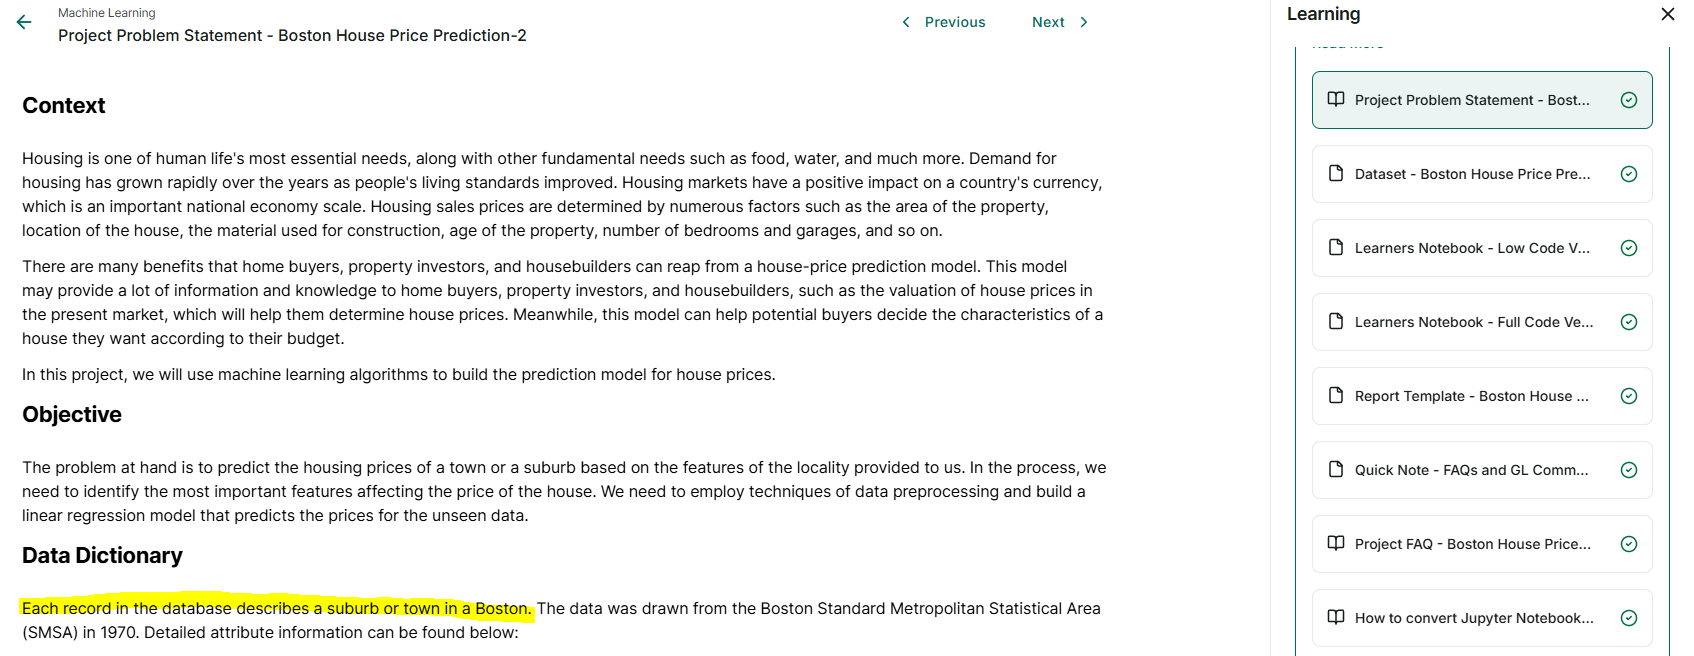

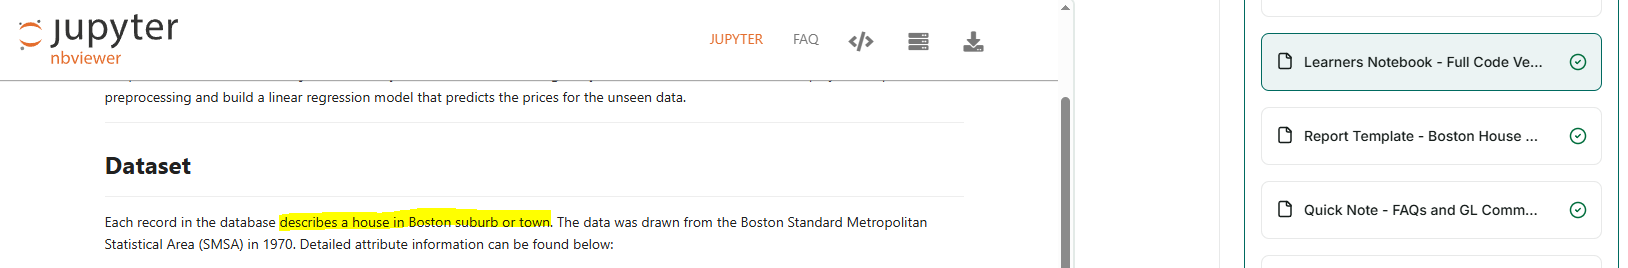

**What I found.** After conducting some brief research I found that neither description matches the original source. The data comes a study in 1978 which used 506 'tracts' from the 1970 Boston Standard Metropolitan Statistical Area. According to the US Census Bureau, a 'census tract' is a small statistical area, usually with a few thousand residents. The Bureau's current guideline is 1,200 to 8,000 people, ideally about 4,000. 

The 506 tracts sit within 92 towns, and each town contains one or more tracts. This was confirmed by matching the provided CSV against a labelled, corrected copy of the data (`BostonHousing2` in the R package `mlbench`), which includes town and tract identifiers.

**NOTE:** *For the sake of the exercise, I will treat the dataset as if it contains 78 distinct towns, as this is the number I might reasonably infer (as demosntrated below) had I not done external research .*

In [172]:
"""
Shows, using only Boston.csv, that the town-level variables can be identified from the data.

The data dictionary describes INDUS as measured "per town". If that's true, every tract in a
town has the same INDUS value. If each town's tracts are also listed together, INDUS will form
unbroken runs of identical values down the file, one run per town.

So each run of INDUS is treated as a block (a candidate town), and every column is checked for
whether it ever changes inside a block. A town-level variable never should. A tract-level
variable should change inside most of them.

Boston.csv is re-read here so the check sees the original columns in their original row order,
whatever later cells do to df.
"""
boston = pd.read_csv("Boston.csv")

# A new block starts wherever INDUS differs from the row above
block = (boston["INDUS"] != boston["INDUS"].shift()).cumsum()
sizes = block.value_counts()
n_multi = (sizes > 1).sum()  # single-tract blocks can't vary, so they're left out of the count

varies_col = f"varies inside (of {n_multi} blocks)"
table = pd.DataFrame({
    "distinct values": boston.nunique(),
    varies_col: boston.groupby(block).nunique().gt(1).sum(),
}).sort_values(varies_col)
print(table.to_string())

town_level = table.index[table[varies_col] == 0].tolist()
n_combos = len(boston[town_level].drop_duplicates())
print(f"\nConstant inside every block: {', '.join(town_level)}")
print(f"{block.nunique()} blocks and {n_combos} distinct combinations of those values, "
      "so every block has its own combination and none reappears later in the file.")
print(f"(INDUS alone has {boston['INDUS'].nunique()} distinct values because some values recur in "
      "separate blocks. The other town-level columns tell those blocks apart.)")
print(f"Tracts per block: min {sizes.min()}, median {sizes.median():.0f}, max {sizes.max()}")

         distinct values  varies inside (of 61 blocks)
ZN                    26                             0
INDUS                 76                             0
RAD                    9                             0
TAX                   66                             0
PTRATIO               46                             0
NOX                   81                             4
CHAS                   2                             8
DIS                  412                            37
CRIM                 504                            61
RM                   446                            61
AGE                  356                            61
LSTAT                455                            61
MEDV                 229                            61

Constant inside every block: ZN, INDUS, RAD, TAX, PTRATIO
78 blocks and 78 distinct combinations of those values, so every block has its own combination and none reappears later in the file.
(INDUS alone has 76 distinct values be

Other findings:

- **Town-level variables.** ZN, INDUS, RAD, TAX and PTRATIO are measured per town and repeated for every tract in that town.
- **Proportions.** They are recorded as percentages on a 0 to 100 scale.
- **Owner-occupied housing only.** RM, AGE and MEDV describe owner-occupied housing only.

**FYI - Data quality issues in the target.**

- **Censoring.** MEDV is censored at both ends. A value of 50.0 means $50,000 or more (16 rows), and 5.0 means $5,000 or less (2 rows).
- **Miscoded values.** This file contains the original, uncorrected MEDV, which has 8 known miscoded values (Gilley and Pace, 1996).
    - For the sake of the exercise I will continue with the dataset as originally provided.

**Adopted definitions.** These definitions are used for the rest of the project.

| Feature | Definition | Measured at |
|---|---|---|
| CRIM | Crime rate, units undocumented ("per capita" is a later addition; the original says "crime rate by town", source FBI 1970). Labelled by town but varies by tract, though about 97% of its variation is between towns. Treated as a relative crime index | Mostly town, partly tract |
| ZN | % of the town's residential land zoned for lots over 25,000 sq ft (0–100) | Town |
| INDUS | Non-retail business acres per town, as a % (0–100) | Town |
| CHAS | 1 if the tract bounds the Charles River, otherwise 0 | Tract |
| NOX | Nitric oxides concentration (parts per 10 million), modelled | Model zone (122 zones) |
| RM | Average number of rooms per owner-occupied housing unit | Tract |
| AGE | % of owner-occupied housing units built before 1940 (0–100) | Tract |
| DIS | Weighted distance to five Boston employment centres | Tract |
| RAD | Index of accessibility to radial highways | Town |
| TAX | Full-value property tax rate per $10,000 | Town |
| PTRATIO | Pupil-teacher ratio | Town |
| LSTAT | % of the population classed as lower status (0–100) | Tract |
| MEDV | Median value of owner-occupied housing unit, in $1,000s (1970 dollars). Censored at 5 and 50 | Tract |

**Sources**

- Harrison, D. & Rubinfeld, D.L. (1978). Hedonic housing prices and the demand for clean air. *Journal of Environmental Economics and Management*, 5, 81–102. https://doi.org/10.1016/0095-0696(78)90006-2
- Gilley, O.W. & Pace, R.K. (1996). On the Harrison and Rubinfeld data. *Journal of Environmental Economics and Management*, 31, 403–405. https://doi.org/10.1006/jeem.1996.0052
- Bivand, R. (2017). Revisiting the Boston data set: Changing the units of observation affects estimated willingness to pay for clean air. *REGION*, 4(1), 109–127. https://doi.org/10.18335/region.v4i1.107
- US Census Bureau, Geography glossary (census tract). https://www.census.gov/programs-surveys/geography/about/glossary.html
- `mlbench` R package, `BostonHousing2` dataset. https://github.com/cran/mlbench

In [173]:
# Axis labels taken from the adopted definitions above, so every graph describes each feature the same way
LABELS = {
    "CRIM":    "CRIM: crime rate (relative index, units undocumented)",
    "ZN":      "ZN: % of residential land zoned for lots > 25,000 sq ft",
    "INDUS":   "INDUS: non-retail business acres (% of town)",
    "CHAS":    "CHAS: tract bounds the Charles River (1 = yes)",
    "NOX":     "NOX: nitric oxides concentration (parts per 10 million, modelled)",
    "RM":      "RM: average rooms per owner-occupied housing unit",
    "AGE":     "AGE: % of owner-occupied units built before 1940",
    "DIS":     "DIS: weighted distance to five Boston employment centres",
    "RAD":     "RAD: index of accessibility to radial highways",
    "TAX":     "TAX: full-value property tax rate (dollars per $10,000)",
    "PTRATIO": "PTRATIO: pupil-teacher ratio (pupils per teacher)",
    "LSTAT":   "LSTAT: % of population classed as lower status",
    "MEDV":    "MEDV: median value of owner-occupied units ($1,000s, 1970 dollars)",
}

# Short unit tags for the small panels of the overview grid
UNITS = {
    "CRIM": "index", "ZN": "%", "INDUS": "%", "CHAS": "0 = no, 1 = yes",
    "NOX": "parts per 10 million", "RM": "rooms", "AGE": "%", "DIS": "weighted distance",
    "RAD": "index", "TAX": "dollars per $10,000", "PTRATIO": "pupils per teacher",
    "LSTAT": "%", "MEDV": "$1,000s (1970)",
}

# Every row is one tract, so every count is a count of tracts. Town-level features (ZN, INDUS, RAD, TAX, PTRATIO)
# repeat the town's value on each of its tracts, so their bar heights also reflect how many tracts a town has.
# (Matplotlib reads a pair of "$" in one label as maths, so each label above keeps to a single "$".)
TRACTS = "Number of tracts"
TRACTS_TOWN = "Number of tracts\n(each tract carries its town's value)"

#### **Observation A:** 
- The dataset consists of 506 rows and 13 columns.
- There are 2 datatypes across the 13 columns in the dataset.
    - float64 (a number with fractional/decimal parts)
        - represented in column # 0, 1, 2, 4, 5, 6, 7, 10, 11, 12
    - int64 (a whole number)
        - represented in column # 3, 8, 9
- `CHAS` is a binary categorisation, identifying whether land borders on a river (1=yes)
- `RAD` is a categorical variable with values 1-8 and 24.
- No strings "str" exist within this dataset (string of text, also referred to as an object (obj))
- No duplicate rows and no missing values, so no cleaning is needed at this stage.
- MEDV is likely our dependant variable (given that it represents a value assigned to a housing unit). However, I will investigate later 

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

#### Note

I have reordered the questions to maintain a more logical flow. Question 3 preceeds Question 2, etc.

In [174]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
ZN,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
INDUS,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
CHAS,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
AGE,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


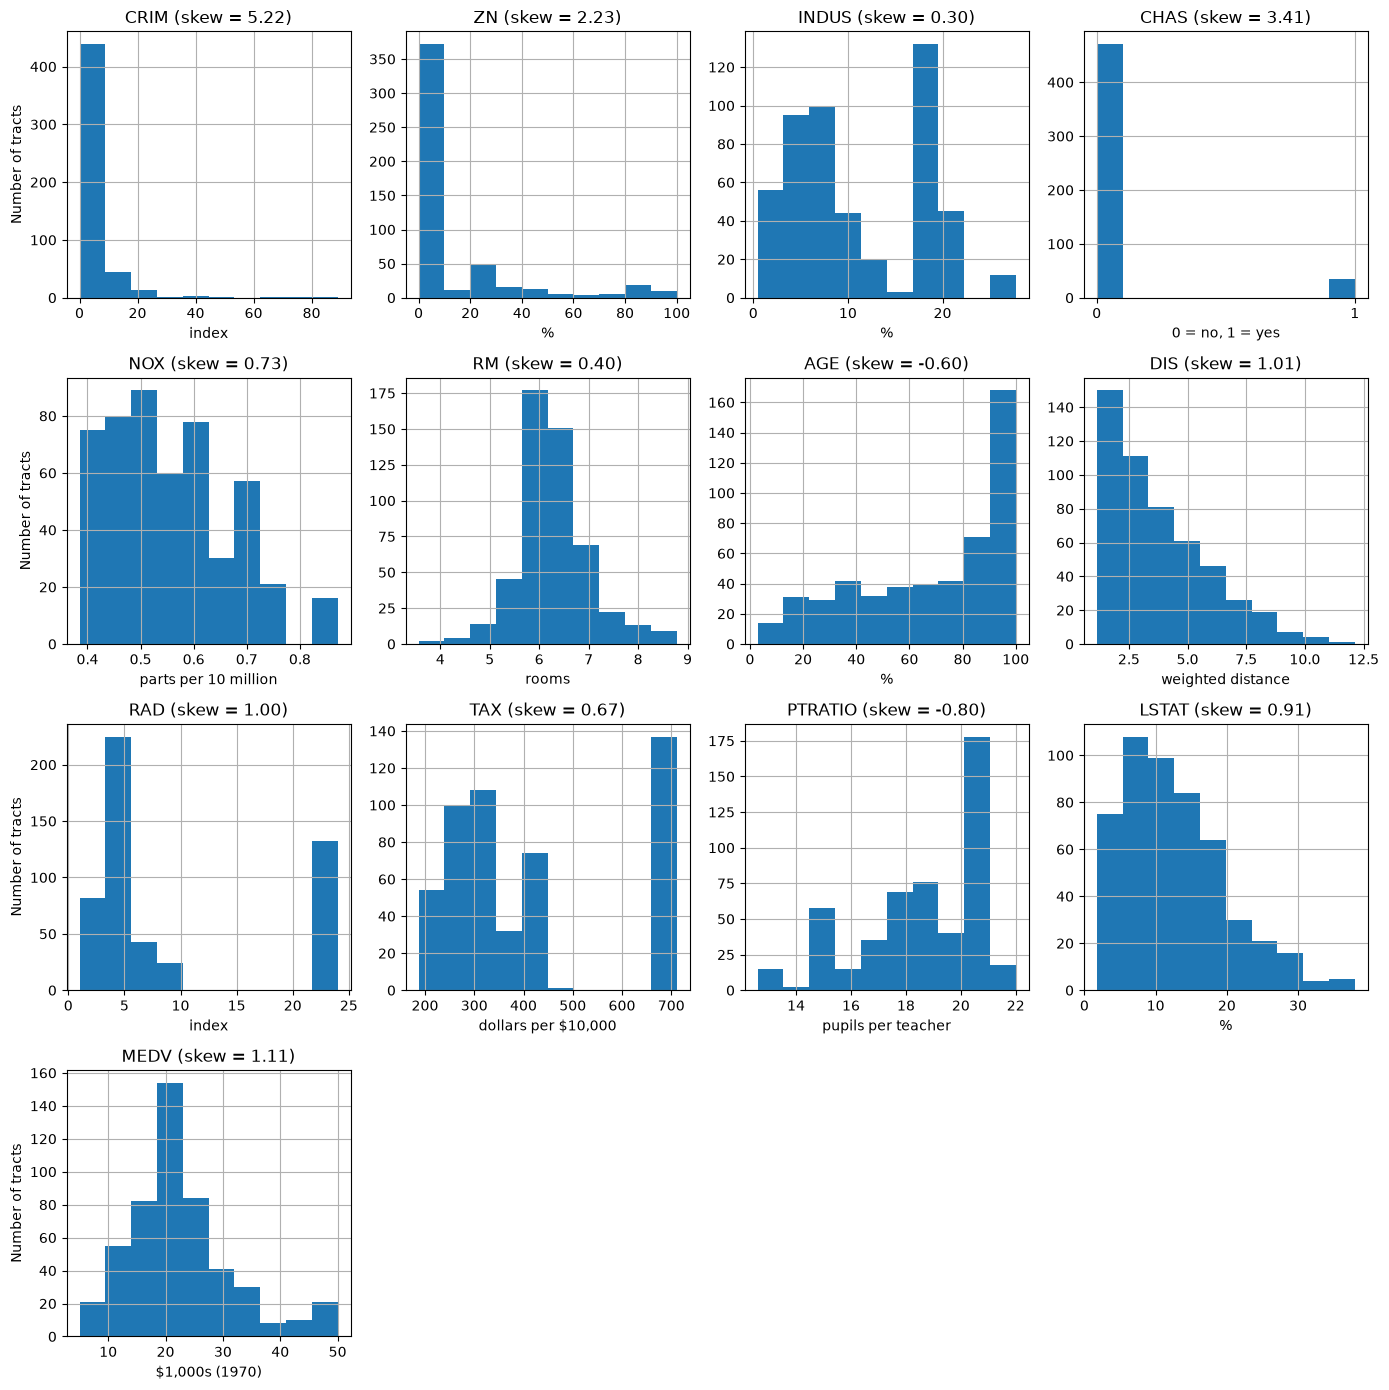

In [175]:
skew = df.skew().sort_values()

fig, axes = plt.subplots(4, 4, figsize = (14, 14))
df.hist(ax = axes.flat[:df.shape[1]])
for i, ax in enumerate(axes.flat):
    col = ax.get_title()
    if col in skew.index:
        ax.set_title(f"{col} (skew = {skew[col]:.2f})")
        ax.set_xlabel(UNITS[col])
        if i % 4 == 0:   # y label on the left-hand column only
            ax.set_ylabel(TRACTS)
        if col == "CHAS":   # binary, so only 0 and 1 are meaningful ticks
            ax.set_xticks([0, 1])
    else:
        ax.set_visible(False)
plt.tight_layout()
plt.show()

#### **Observation B:**
- **Skewness:**
    - *Strongly skewed to the right*
        - `CRIM` (5.2), 
        - `CHAS` (3.4, binary so not meaningful),
        - `ZN` (2.2). 
    - *Moderately skewed to the right*
        - `MEDV` (1.1), 
        - `DIS` (1.0), 
        - `RAD` (1.0) 
        - `LSTAT` (0.9). 
    - *Moderately skewed to the left* 
        - `PTRATIO` (-0.8),
        - `AGE` (-0.6).

### Univariate - `CRIM`

Crime rate, units undocumented ("per capita" is a later addition. Treated as a relative crime index)

In [176]:
print(f"Distinct values: {df['CRIM'].nunique()} across {len(df)} rows")

Distinct values: 504 across 506 rows


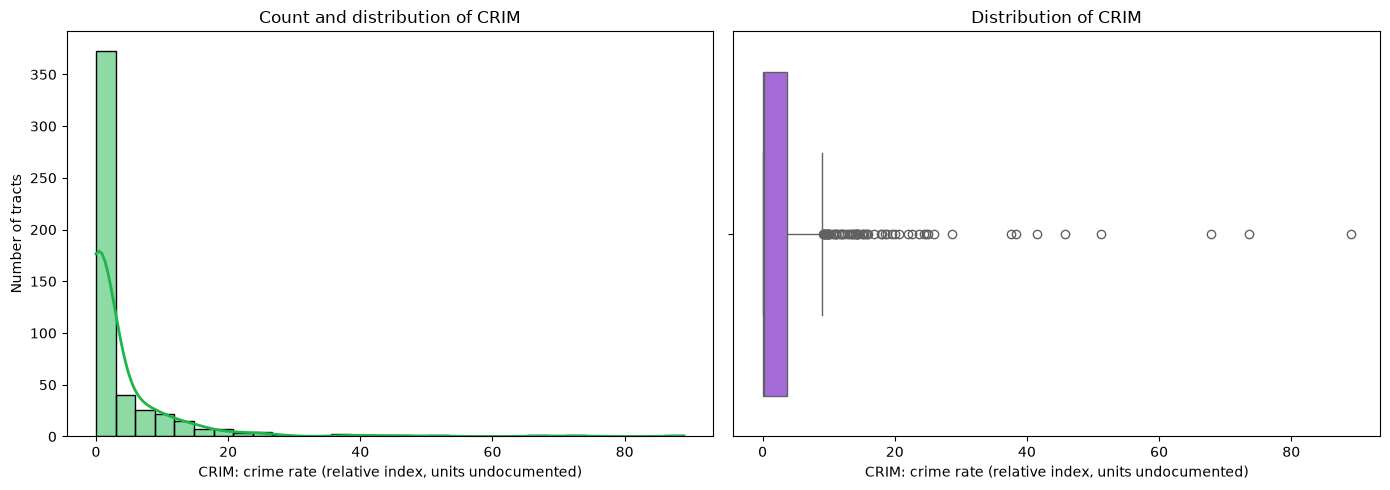

In [177]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (left)
sns.histplot(data=df, x="CRIM", bins=30, kde=True, color="#1CB64A",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title("Count and distribution of CRIM")
axes[0].set_xlabel(LABELS["CRIM"])
axes[0].set_ylabel(TRACTS)

# Boxplot (right)
sns.boxplot(data=df, x="CRIM", color="#A357EB", ax=axes[1])
axes[1].set_title("Distribution of CRIM")
axes[1].set_xlabel(LABELS["CRIM"])

plt.tight_layout()
plt.show()

In [178]:
# Descriptive statistics and outliers for CRIM
print(df["CRIM"].describe())
print("\nPercentiles:\n",df["CRIM"].quantile([0.90, 0.95, 0.99]))
print(f"\nSkewness: {df['CRIM'].skew():.2f}   Kurtosis: {df['CRIM'].kurt():.2f}")

q1, q3 = df["CRIM"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
n_out = (df["CRIM"] > upper).sum()
print(f"IQR upper fence: {upper:.2f} -> {n_out} outliers ({n_out / len(df):.1%})")

count    506.000000
mean       3.613524
std        8.601545
min        0.006320
25%        0.082045
50%        0.256510
75%        3.677083
max       88.976200
Name: CRIM, dtype: float64

Percentiles:
 0.90    10.75300
0.95    15.78915
0.99    41.37033
Name: CRIM, dtype: float64

Skewness: 5.22   Kurtosis: 37.13
IQR upper fence: 9.07 -> 66 outliers (13.0%)


In [179]:
# Checking the minimum value of the "CRIM" column to see if there are any zero or negative values which a log transformation cannot handle.
if (df["CRIM"] <= 0).any():
    print("CRIM contains zero or negative values, log transformation may not be appropriate.")
else:
    print("CRIM does not contain zero or negative values, log transformation is appropriate.")

CRIM does not contain zero or negative values, log transformation is appropriate.


In [180]:
# CRIM has no zeros (min = 0.00632), so a plain natural log is valid. log1p is shown for comparison only.
df["CRIM_log"] = np.log(df["CRIM"])
print(f"Skewness of CRIM:        {df['CRIM'].skew():.3f}")
print(f"Skewness of log(CRIM):   {df['CRIM_log'].skew():.3f}")
print(f"Skewness of log1p(CRIM): {np.log1p(df['CRIM']).skew():.3f}")

Skewness of CRIM:        5.223
Skewness of log(CRIM):   0.406
Skewness of log1p(CRIM): 1.269


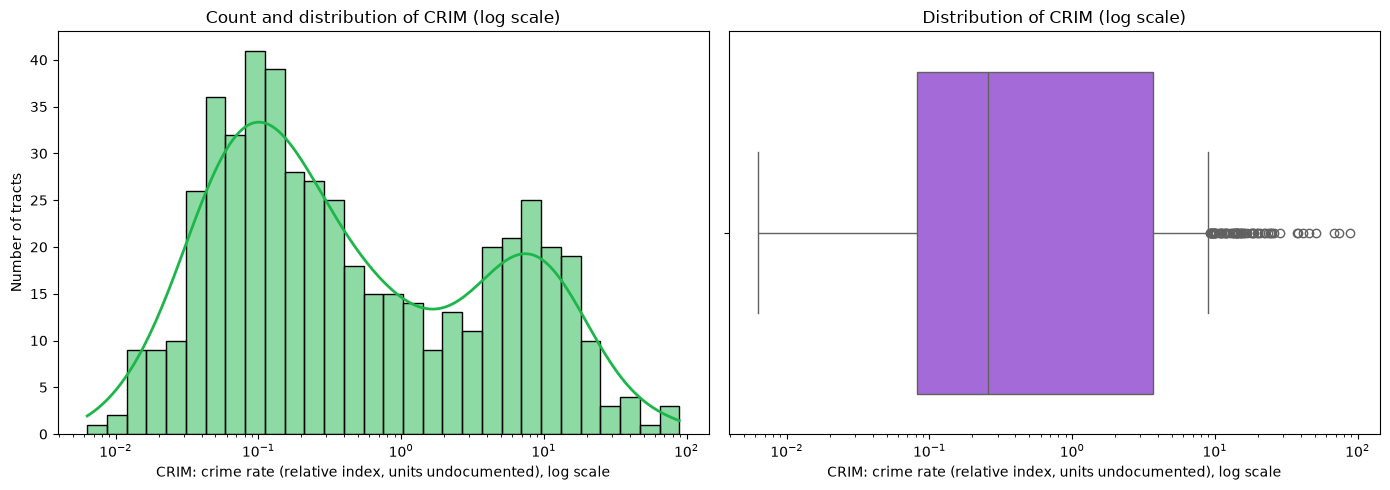

In [181]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="CRIM", bins=30, kde=True, log_scale=True, color="#1CB64A",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title("Count and distribution of CRIM (log scale)")
axes[0].set_xlabel(LABELS["CRIM"] + ", log scale")
axes[0].set_ylabel(TRACTS)

sns.boxplot(data=df, x="CRIM", color="#A357EB", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Distribution of CRIM (log scale)")
axes[1].set_xlabel(LABELS["CRIM"] + ", log scale")

plt.tight_layout()
plt.show()

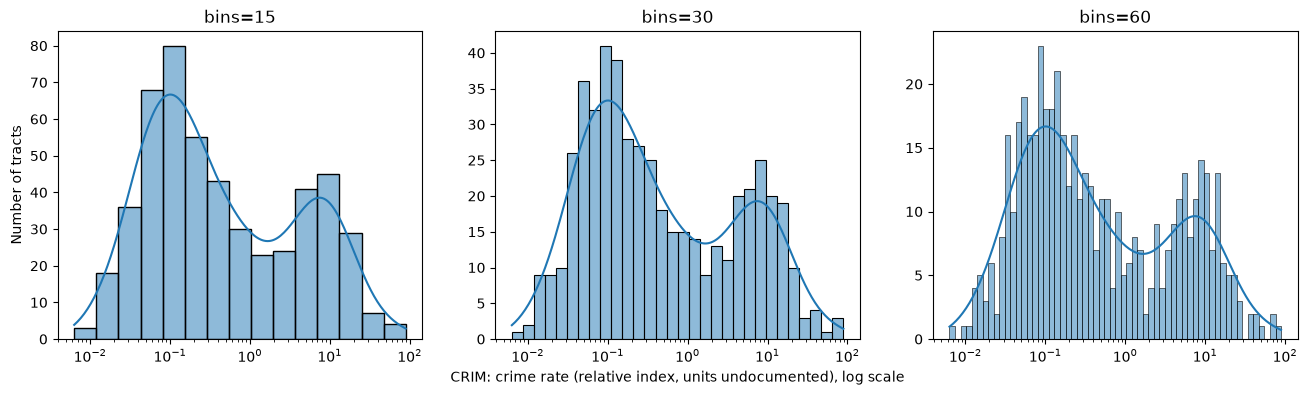

In [182]:
# After log transformation, the histogram appears to be bimodally distributed.
# Changing the number of bins to check if bimodality is a binning artefact.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, b in zip(axes, [15, 30, 60]):
    sns.histplot(data=df, x="CRIM", bins=b, kde=True, log_scale=True, ax=ax)
    ax.set_title(f"bins={b}")
    ax.set_xlabel("")
    ax.set_ylabel("")
# One x label under the middle panel serves all three
axes[0].set_ylabel(TRACTS)
axes[1].set_xlabel(LABELS["CRIM"] + ", log scale")
plt.show()

In [183]:
# Threshold of 1 sits in the valley between the two modes on the log-scale histogram (cell above).
df["CRIM_group"] = np.where(df["CRIM"] > 1, "high", "low")
df["CRIM_group"].value_counts()

CRIM_group
low     332
high    174
Name: count, dtype: int64

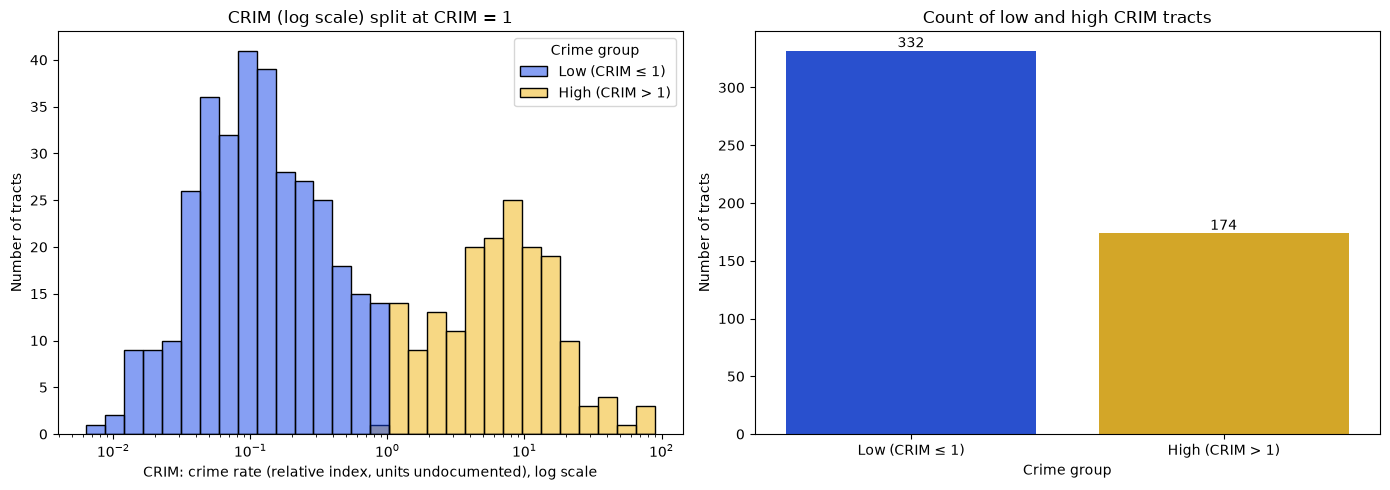

In [184]:
palette = {"low": "#0E41E9", "high": "#F0B30B"}
group_names = {"low": "Low (CRIM ≤ 1)", "high": "High (CRIM > 1)"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram split by group (left)
sns.histplot(data=df, x="CRIM", hue="CRIM_group", palette=palette, log_scale=True, bins=30, ax=axes[0])
axes[0].set_title("CRIM (log scale) split at CRIM = 1")
axes[0].set_xlabel(LABELS["CRIM"] + ", log scale")
axes[0].set_ylabel(TRACTS)
legend = axes[0].get_legend()
legend.set_title("Crime group")
for text in legend.get_texts():
    text.set_text(group_names[text.get_text()])

# Count of each group (right)
sns.countplot(data=df, x="CRIM_group", hue="CRIM_group", order=["low", "high"], palette=palette, legend=False, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container)
axes[1].set_title("Count of low and high CRIM tracts")
axes[1].set_xticks([0, 1], [group_names["low"], group_names["high"]])
axes[1].set_xlabel("Crime group")
axes[1].set_ylabel(TRACTS)

plt.tight_layout()
plt.show()

#### **Observation C:**
As crime rate goes up, house price (MEDV) tends to go down. I will investigate this further in the bivariate and multivariate analysis.

#### Observations from univariate analysis of `CRIM`

- **Shape:** `CRIM` (alleged 'per-capita' crime rate) is extremely right-skewed (skew = 5.22, kurtosis = 37.1). The mean (3.61) is about 14x the median (0.26), and the maximum (88.98) is far above the 99th percentile (41.4).
- **Outliers:** 66 tracts (13.0%) lie above the IQR upper fence (Q3 + 1.5 x IQR = 9.07). These are real high-crime tracts rather than data errors, so they are kept and handled by transformation instead of removal.
- **Transformation:** `CRIM` has no zero or negative values (min = 0.00632), so a plain `log` transformation is valid. It reduces skew from 5.22 to 0.41, whereas `log1p` only reaches 1.27 because it barely changes values below 1.
- **Bimodality:** on a log scale the distribution has two modes (around 0.05-0.1 and around 5-10). The pattern persists with 15, 30 and 60 bins, so it is not a binning artefact.
- **Groups:** splitting at `CRIM` = 1, which sits in the valley between the modes, gives 332 low-crime and 174 high-crime tracts.

### Univariate - `ZN`
Percentage of the town's residential land zoned for lots over 25,000 sq ft

In [185]:
print(f"Distinct values: {df['ZN'].nunique()} across {len(df)} rows")

Distinct values: 26 across 506 rows


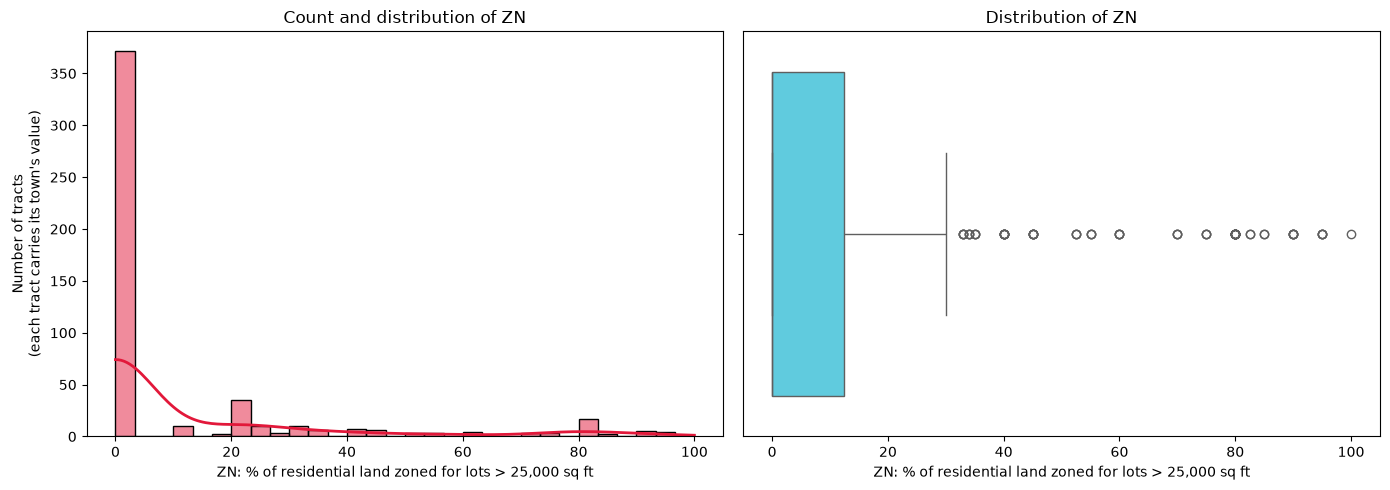

In [186]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (left)
sns.histplot(data=df, x="ZN", bins=30, kde=True, color="#E2183A",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title("Count and distribution of ZN")
axes[0].set_xlabel(LABELS["ZN"])
axes[0].set_ylabel(TRACTS_TOWN)

# Boxplot (right)
sns.boxplot(data=df, x="ZN", color="#4BDAF3", ax=axes[1])
axes[1].set_title("Distribution of ZN")
axes[1].set_xlabel(LABELS["ZN"])

plt.tight_layout()
plt.show()

In [187]:
# Descriptive statistics and outliers for ZN
print(df["ZN"].describe())
print("\nPercentiles:\n",df["ZN"].quantile([0.90, 0.95, 0.99]))
print(f"\nSkewness: {df['ZN'].skew():.3f}   Kurtosis: {df['ZN'].kurt():.3f}")

q1, q3 = df["ZN"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
n_out = (df["ZN"] > upper).sum()
print(f"IQR upper fence: {upper:.3f} -> {n_out} outliers ({n_out / len(df):.1%})")

count    506.000000
mean      11.363636
std       23.322453
min        0.000000
25%        0.000000
50%        0.000000
75%       12.500000
max      100.000000
Name: ZN, dtype: float64

Percentiles:
 0.90    42.5
0.95    80.0
0.99    90.0
Name: ZN, dtype: float64

Skewness: 2.226   Kurtosis: 4.032
IQR upper fence: 31.250 -> 68 outliers (13.4%)


In [188]:
# Checking the minimum value of the "ZN" column to see if there are any zero or negative values which a log transformation cannot handle.
if (df["ZN"] <= 0).any():
    print("ZN contains zero or negative values, log transformation may not be appropriate.")
else:
    print("ZN does not contain zero or negative values, log transformation is appropriate.")

# Counting the number of zeros in the "ZN" column and in every column of the feature set.
print(f"Number of zeros in ZN: {(df['ZN'] == 0).sum()}")
print("Count of zeros in each column:")
print((df == 0).sum())

ZN contains zero or negative values, log transformation may not be appropriate.
Number of zeros in ZN: 372
Count of zeros in each column:
CRIM            0
ZN            372
INDUS           0
CHAS          471
NOX             0
RM              0
AGE             0
DIS             0
RAD             0
TAX             0
PTRATIO         0
LSTAT           0
MEDV            0
CRIM_log        0
CRIM_group      0
dtype: int64


In [189]:
zn = df["ZN"]

# Plain log applied to every row: log(0) = -inf, so the skewness is undefined (NaN)
with np.errstate(divide="ignore"):
    zn_log_all = np.log(zn)

# Plain log is undefined at 0, so it can only be applied to the non-zero rows
zn_log_nonzero = np.log(zn[zn > 0])

# log1p works on every row
zn_log1p = np.log1p(zn)

print(f"Zeros in ZN: {(zn == 0).sum()} of {len(zn)} ({(zn == 0).mean():.0%})")
print(f"Skewness of ZN:                    {zn.skew():.3f}")
print(f"Skewness of log(ZN), all rows:      {zn_log_all.skew():.3f}")
print(f"Skewness of log(ZN), non-zero only: {zn_log_nonzero.skew():.3f}")
print(f"Skewness of log1p(ZN), all rows:    {zn_log1p.skew():.3f}")
print(f"Skewness of log1p(ZN), non-zero only: {np.log1p(zn[zn > 0]).skew():.3f}")

Zeros in ZN: 372 of 506 (74%)
Skewness of ZN:                    2.226
Skewness of log(ZN), all rows:      nan
Skewness of log(ZN), non-zero only: 0.150
Skewness of log1p(ZN), all rows:    1.193
Skewness of log1p(ZN), non-zero only: 0.172


#### Observation D
The overwhelming number of 0s makes it difficult to observe the data, even when log transformed. I'll drop the 0s for now to help with visibility.

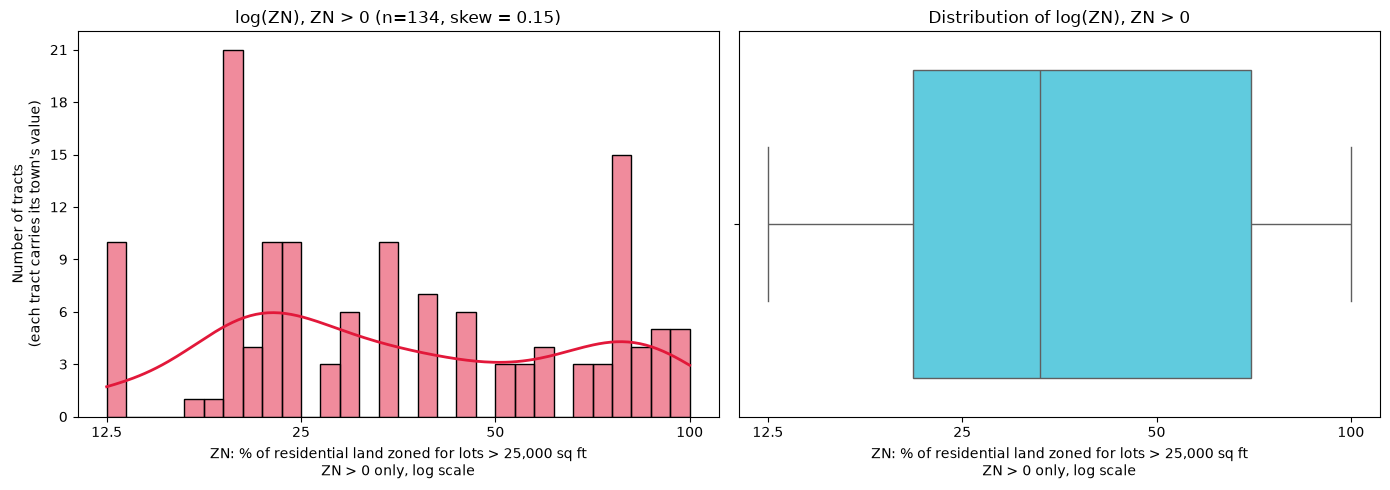

In [190]:
# natural log over non-zero rows only
zn_log_nz = np.log(df.loc[df["ZN"] > 0, "ZN"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(x=zn_log_nz, bins=30, kde=True, color="#E2183A",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title(f"log(ZN), ZN > 0 (n={len(zn_log_nz)}, skew = {zn_log_nz.skew():.2f})")

sns.boxplot(x=zn_log_nz, color="#4BDAF3", ax=axes[1])
axes[1].set_title("Distribution of log(ZN), ZN > 0")

# Ticks sit at the log of ZN = 12.5, 25, 50 and 100 (each double the last) but are labelled in the original %
zn_ticks = [12.5, 25, 50, 100]
for ax in axes:
    ax.set_xticks(np.log(zn_ticks), [str(t) for t in zn_ticks])
    ax.set_xlabel(LABELS["ZN"] + "\nZN > 0 only, log scale")
axes[0].set_ylabel(TRACTS_TOWN)
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))   # counts are whole tracts

plt.tight_layout()
plt.show()

#### Observation E
Looking at the Kernel Density Esitmate (KDE), there appears to be another, albeit milder, bimodal distribution. Now that I've removed the 0s I'll check whether the log transformation is weirdly shaping my data.

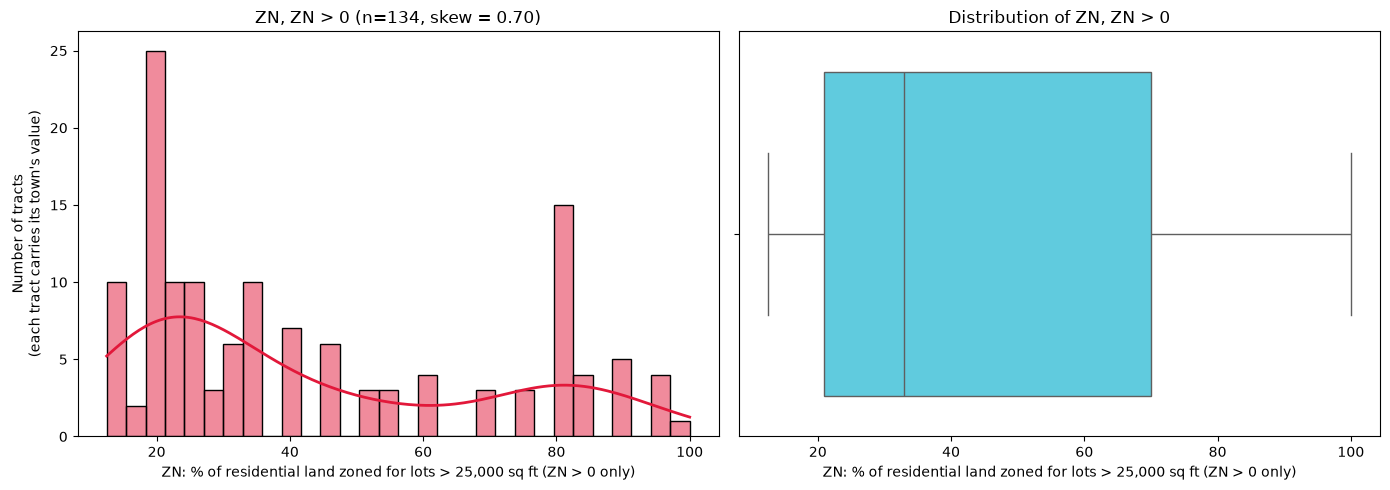

In [191]:
# ZN > 0 only, no log transformation
zn_nz = df.loc[df["ZN"] > 0, "ZN"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(x=zn_nz, bins=30, kde=True, color="#E2183A",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title(f"ZN, ZN > 0 (n={len(zn_nz)}, skew = {zn_nz.skew():.2f})")
axes[0].set_xlabel(LABELS["ZN"] + " (ZN > 0 only)")
axes[0].set_ylabel(TRACTS_TOWN)

sns.boxplot(x=zn_nz, color="#4BDAF3", ax=axes[1])
axes[1].set_title("Distribution of ZN, ZN > 0")
axes[1].set_xlabel(LABELS["ZN"] + " (ZN > 0 only)")

plt.tight_layout()
plt.show()

#### Observation F
The second peak in the KDE line appears to be largely driven by the spike around 80-85. It may be an artefact of the histogram's bins. I'll have a look at the actual counts of each distinct value.

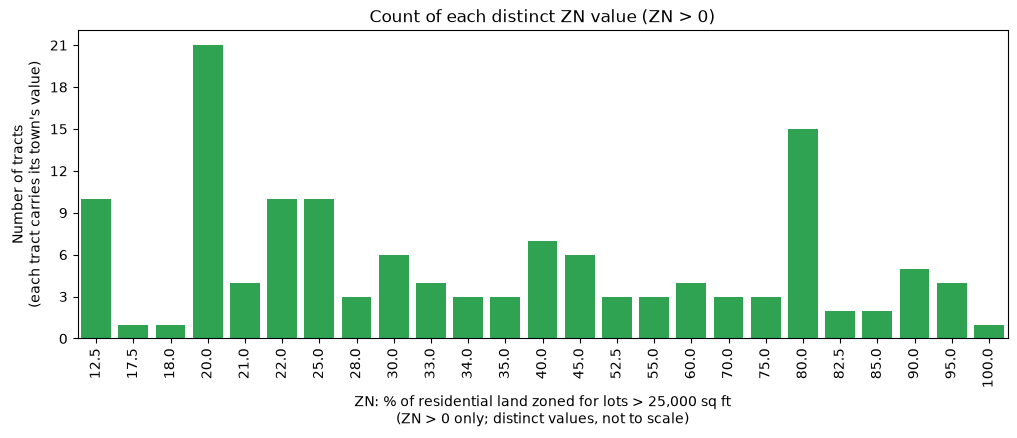

In [192]:
counts = zn_nz.value_counts().sort_index()
plt.figure(figsize=(12, 4))
sns.countplot(x=zn_nz, color="#1CB64A")
plt.xticks(rotation=90)
plt.title("Count of each distinct ZN value (ZN > 0)")
plt.xlabel(LABELS["ZN"] + "\n(ZN > 0 only; distinct values, not to scale)")
plt.ylabel(TRACTS_TOWN)
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))   # counts are whole tracts
plt.show()

#### Observation G
There does appear to be a genuine spike in the number of tracts whose town has 80% of residential land zoned for lots over 25,000 sq.ft. I'll keep this in mind when moving into the bivariate and multivariate analysis.
*Noting that this is still a relatively small proporition of the overall number of the total number of entries. 

#### Observations from univariate analysis of `ZN`
- **Shape:** there are 26 distinct values. 372 of the 506 tracts (74%) have ZN = 0, so Q1 and the median are both 0 and Q3 is only 12.5. A long right tail up to 100 pulls the mean (11.36) well above the median. The distribution is strongly right-skewed (skew = 2.23, kurtosis = 4.03).

- **Outliers:** the IQR upper fence of 31.25 flags 68 tracts (13.4%). The fence is that low only because so many values are zero, so these are real zoning values rather than errors.

- **Non-zero values (134 tracts):** values come in round steps (12.5, 20, 25, 80 and so on). The most common are 20 (21 tracts) and 80 (15 tracts). The spike at 80 shows up in the per-value countplot, so it is not a binning artefact. 76 of the 134 non-zero tracts (57%) are below 40%, and only one tract reaches 100.

- **Transformation:** a plain log can't handle the zeros. log1p across all rows only brings the skew down to 1.19, because the spike at zero remains. The skew comes from that spike rather than from the tail, so a zero / non-zero indicator is worth considering in preprocessing.

### Univariate - `INDUS`
Non-retail business acres per town, as a percentage

In [193]:
print(f"Distinct values: {df['INDUS'].nunique()} across {len(df)} rows")

Distinct values: 76 across 506 rows


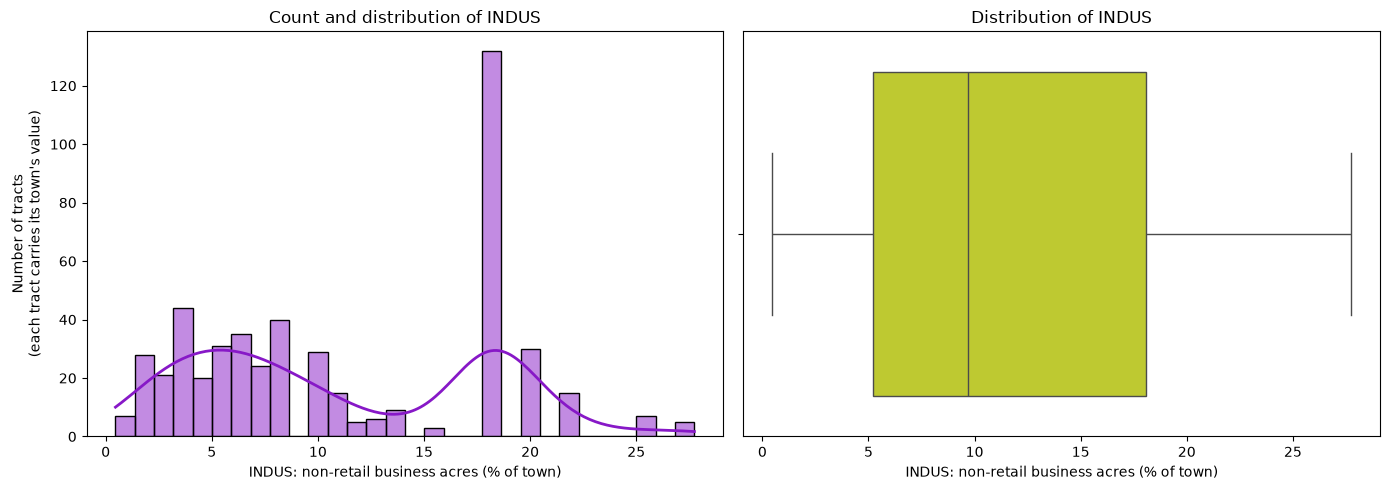

In [194]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (left)
sns.histplot(data=df, x="INDUS", bins=30, kde=True, color="#8718C7",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title("Count and distribution of INDUS")
axes[0].set_xlabel(LABELS["INDUS"])
axes[0].set_ylabel(TRACTS_TOWN)

# Boxplot (right)
sns.boxplot(data=df, x="INDUS", color="#D4E218", ax=axes[1])
axes[1].set_title("Distribution of INDUS")
axes[1].set_xlabel(LABELS["INDUS"])

plt.tight_layout()
plt.show()

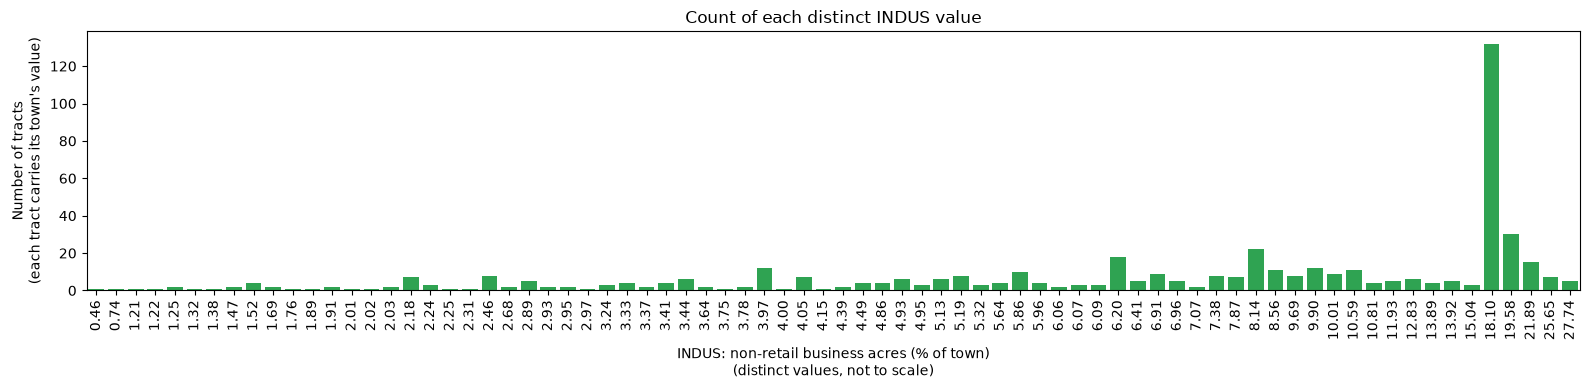

In [195]:
#I would have found the spike in the ZN count if I had moved to a countplot of non-zero ZN values much sooner. I'll jump to that approach this time.
indus = df["INDUS"]
counts = indus.value_counts().sort_index()

plt.figure(figsize=(16, 4))
# Values shown to 2 dp so every tick reads the same way (otherwise 18.10 appears as 18.1)
sns.countplot(x=indus.map("{:.2f}".format), order=[f"{v:.2f}" for v in counts.index], color="#1CB64A")
plt.xticks(rotation=90)
plt.title("Count of each distinct INDUS value")
plt.xlabel(LABELS["INDUS"] + "\n(distinct values, not to scale)")
plt.ylabel(TRACTS_TOWN)
plt.tight_layout()
plt.show()

In [196]:
# Descriptive statistics and outliers for INDUS
print(df["INDUS"].describe())
print("\nPercentiles:\n", df["INDUS"].quantile([0.90, 0.95, 0.99]))
print(f"\nSkewness: {df['INDUS'].skew():.2f}   Kurtosis: {df['INDUS'].kurt():.2f}")

q1, q3 = df["INDUS"].quantile([0.25, 0.75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
n_out = ((df["INDUS"] < lower) | (df["INDUS"] > upper)).sum()
print(f"IQR fences: {lower:.2f} to {upper:.2f} -> {n_out} outliers ({n_out / len(df):.1%})")

# Most frequent distinct values: INDUS is a town-level value repeated across tracts
print("\nMost frequent INDUS values:\n", df["INDUS"].value_counts().head(10))
print(f"Distinct values: {df['INDUS'].nunique()} across {len(df)} rows")

# No zeros or negatives, so log is valid. Checking whether a transformation is needed at all.
print(f"\nSkewness of INDUS:      {df['INDUS'].skew():.3f}")
print(f"Skewness of log(INDUS): {np.log(df['INDUS']).skew():.3f}")

count    506.000000
mean      11.136779
std        6.860353
min        0.460000
25%        5.190000
50%        9.690000
75%       18.100000
max       27.740000
Name: INDUS, dtype: float64

Percentiles:
 0.90    19.58
0.95    21.89
0.99    25.65
Name: INDUS, dtype: float64

Skewness: 0.30   Kurtosis: -1.23
IQR fences: -14.18 to 37.47 -> 0 outliers (0.0%)

Most frequent INDUS values:
 INDUS
18.10    132
19.58     30
8.14      22
6.20      18
21.89     15
3.97      12
9.90      12
8.56      11
10.59     11
5.86      10
Name: count, dtype: int64
Distinct values: 76 across 506 rows

Skewness of INDUS:      0.295
Skewness of log(INDUS): -0.643


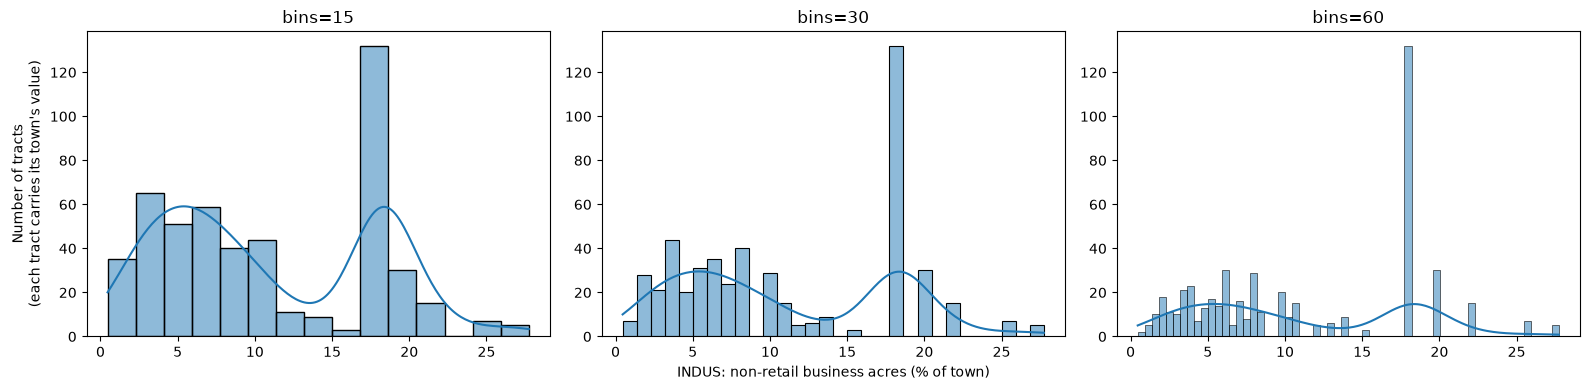

In [197]:
# The histogram looks multi-modal. Changing the number of bins to check if this is a binning artefact.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, b in zip(axes, [15, 30, 60]):
    sns.histplot(data=df, x="INDUS", bins=b, kde=True, ax=ax)
    ax.set_title(f"bins={b}")
    ax.set_xlabel("")
    ax.set_ylabel("")
# One x label under the middle panel serves all three
axes[0].set_ylabel(TRACTS_TOWN)
axes[1].set_xlabel(LABELS["INDUS"])
plt.tight_layout()
plt.show()

INDUS_group
low     317
high    189
Name: count, dtype: int64


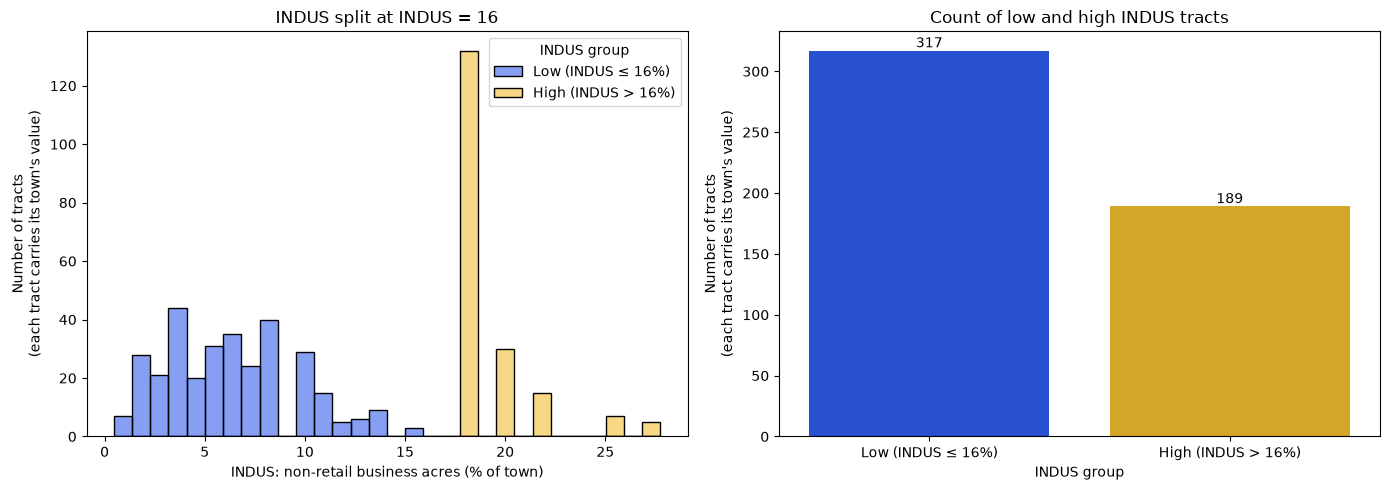

In [198]:
# Threshold of 16 sits in the sparsely populated gap between the two clusters (almost no tracts between ~14 and ~17.7).
df["INDUS_group"] = np.where(df["INDUS"] > 16, "high", "low")
print(df["INDUS_group"].value_counts())

palette = {"low": "#0E41E9", "high": "#F0B30B"}
group_names = {"low": "Low (INDUS ≤ 16%)", "high": "High (INDUS > 16%)"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram split by group (left)
sns.histplot(data=df, x="INDUS", hue="INDUS_group", palette=palette, bins=30, ax=axes[0])
axes[0].set_title("INDUS split at INDUS = 16")
axes[0].set_xlabel(LABELS["INDUS"])
axes[0].set_ylabel(TRACTS_TOWN)
legend = axes[0].get_legend()
legend.set_title("INDUS group")
for text in legend.get_texts():
    text.set_text(group_names[text.get_text()])

# Count of each group (right)
sns.countplot(data=df, x="INDUS_group", hue="INDUS_group", order=["low", "high"], palette=palette, legend=False, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container)
axes[1].set_title("Count of low and high INDUS tracts")
axes[1].set_xticks([0, 1], [group_names["low"], group_names["high"]])
axes[1].set_xlabel("INDUS group")
axes[1].set_ylabel(TRACTS_TOWN)

plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `INDUS`

- **Shape:** `INDUS` ranges from 0.46 to 27.74 with a mean of 11.14 and a median of 9.69. It is only mildly right-skewed (skew = 0.30) and flat-topped (kurtosis = -1.23). The histogram is multi-modal rather than bell-shaped, with a broad cluster between about 2 and 14 and a separate cluster around 18-20.
- **Repeated values:** `INDUS` has only 76 distinct values across 506 rows because it is a town-level value copied onto every tract in that town. 132 tracts (26%) share the single value 18.10, followed by 19.58 (30 tracts), 8.14 (22), 6.20 (18) and 21.89 (15). The tall spike at 18.10 is also why the 75th percentile equals exactly 18.10, so `INDUS` behaves like a semi-categorical variable.
- **Outliers:** none. The IQR fences are -14.18 and 37.47, and the maximum is 27.74. The high-`INDUS` tracts are a genuine group of industrial towns rather than extreme values, so nothing needs removing.
- **Bimodality:** the gap between the two clusters persists with 15, 30 and 60 bins, so it is not a binning artefact.
- **Groups:** splitting at `INDUS` = 16, in the sparsely populated gap between the clusters, gives 317 low-`INDUS` and 189 high-`INDUS` tracts.

### Univariate - `CHAS`
Binary flag. 1 if the tract bounds the Charles River, otherwise 0.

In [199]:
print(f"Distinct values: {df['CHAS'].nunique()} across {len(df)} rows")
print(f"Descriptive statistics for CHAS:\n{df['CHAS'].describe()}")

Distinct values: 2 across 506 rows
Descriptive statistics for CHAS:
count    506.000000
mean       0.069170
std        0.253994
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: CHAS, dtype: float64


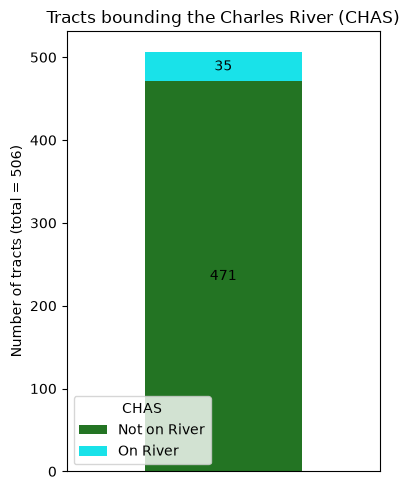

In [200]:
df["OnRiver"] = np.where(df["CHAS"] > 0, "On River", "Not on River")

palette = {"Not on River": "#237423", "On River": "#19E2E9"}
counts = df["OnRiver"].value_counts()

# One stacked bar: one column per class, so the segments stack
ax = counts.to_frame().T.plot(kind="bar", stacked=True, color=palette, figsize=(4, 5))
for container in ax.containers:
    ax.bar_label(container, label_type="center")
ax.set_xticks([])
ax.set_ylabel(f"Number of tracts (total = {len(df)})")
ax.set_title("Tracts bounding the Charles River (CHAS)")
ax.get_legend().set_title("CHAS")
plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `CHAS`

- **Shape:** binary. 35 of the 506 tracts (6.9%) bound the Charles River and 471 (93.1%) do not. The mean of 0.069 is that same proportion.

- **Imbalance:** anything learned about the river-bounding (waterfront) tracts rests on only 35 rows.

- **Skew and outliers:** the skew of 3.41 reflects the imbalance and says nothing about shape. Q1 and Q3 are both 0, so a boxplot would mark every 1 as an outlier, but none of them is. CHAS should stay as a 0/1 tag and no transformation is needed.

### Univariate - `NOX`

In [201]:
print(f"Distinct values: {df['NOX'].nunique()} across {len(df)} rows")

Distinct values: 81 across 506 rows


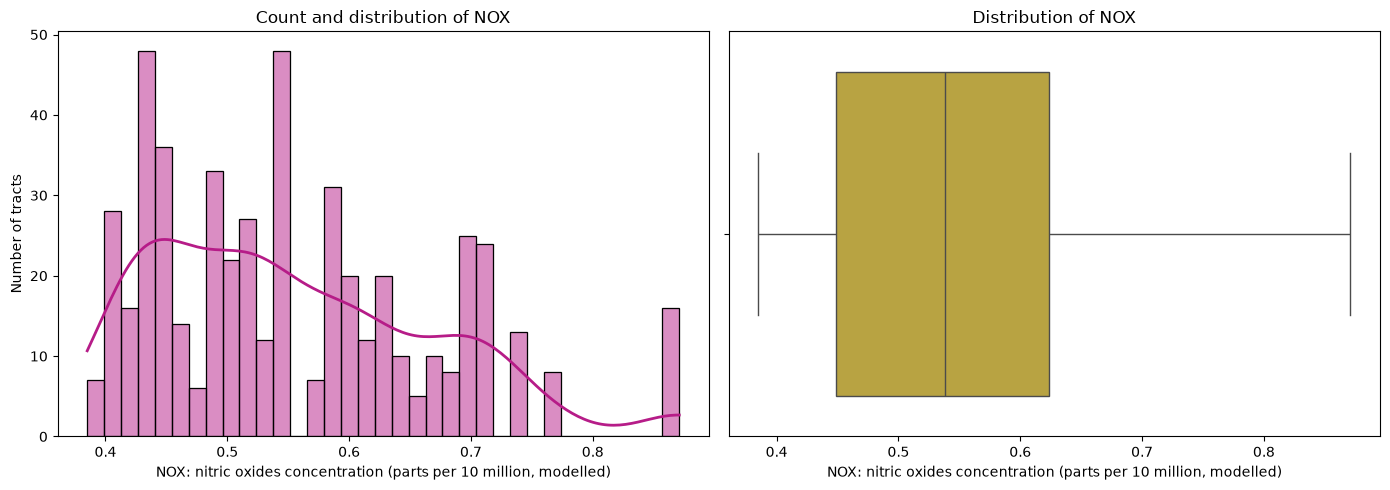

In [202]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (left)
sns.histplot(data=df, x="NOX", bins=35, kde=True, color="#B61C88",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title("Count and distribution of NOX")
axes[0].set_xlabel(LABELS["NOX"])
axes[0].set_ylabel(TRACTS)

# Boxplot (right)
sns.boxplot(data=df, x="NOX", color="#CCAF2E", ax=axes[1])
axes[1].set_title("Distribution of NOX")
axes[1].set_xlabel(LABELS["NOX"])

plt.tight_layout()
plt.show()

In [203]:
# Descriptive statistics and outliers for NOX
print(df["NOX"].describe())
print("\nPercentiles:\n", df["NOX"].quantile([0.90, 0.95, 0.99]))
print(f"\nSkewness: {df['NOX'].skew():.2f}   Kurtosis: {df['NOX'].kurt():.2f}")

q1, q3 = df["NOX"].quantile([0.25, 0.75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
n_out = ((df["NOX"] < lower) | (df["NOX"] > upper)).sum()
print(f"IQR fences: {lower:.2f} to {upper:.2f} -> {n_out} outliers ({n_out / len(df):.1%})")

# Most frequent distinct values: NOX is a value placed over 122 modelled zones
print("\nMost frequent NOX values:\n", df["NOX"].value_counts().head(10))
print(f"Distinct values: {df['NOX'].nunique()} across {len(df)} rows")

# Values above the 95th percentile, to show the gap below the maximum
print("\nValues above the 95th percentile:\n", df.loc[df["NOX"] > df["NOX"].quantile(0.95), "NOX"].value_counts().sort_index())

count    506.000000
mean       0.554695
std        0.115878
min        0.385000
25%        0.449000
50%        0.538000
75%        0.624000
max        0.871000
Name: NOX, dtype: float64

Percentiles:
 0.90    0.713
0.95    0.740
0.99    0.871
Name: NOX, dtype: float64

Skewness: 0.73   Kurtosis: -0.06
IQR fences: 0.19 to 0.89 -> 0 outliers (0.0%)

Most frequent NOX values:
 NOX
0.538    23
0.713    18
0.437    17
0.871    16
0.624    15
0.489    15
0.693    14
0.605    14
0.740    13
0.544    12
Name: count, dtype: int64
Distinct values: 81 across 506 rows

Values above the 95th percentile:
 NOX
0.770     8
0.871    16
Name: count, dtype: int64


#### Observations from univariate analysis of `NOX`

- **Shape:** ranges from 0.385 to 0.871, with a mean of 0.555 and a median of 0.538. It is moderately right-skewed (skew = 0.73) with tails close to normal (kurtosis = -0.06). The middle half of tracts lies between 0.449 and 0.624.

- **Repeated values:** only 81 distinct values across 506 tracts, because NOX is modelled per zone and repeated for every tract in that zone. The most common value, 0.538 (23 tracts), is also the median.

- **Isolated top group:** the maximum, 0.871, is the fourth most common value (16 tracts). A clear gap separates it from the rest: no tract falls between 0.77 and 0.871.

- **Outliers:** none. The IQR fences (0.19 to 0.89) contain every value, including the 0.871 group.

### Univariate - `RM`
Average number of rooms per owner-occupied housing unit

In [204]:
print(f"Distinct values: {df['RM'].nunique()} across {len(df)} rows")

Distinct values: 446 across 506 rows


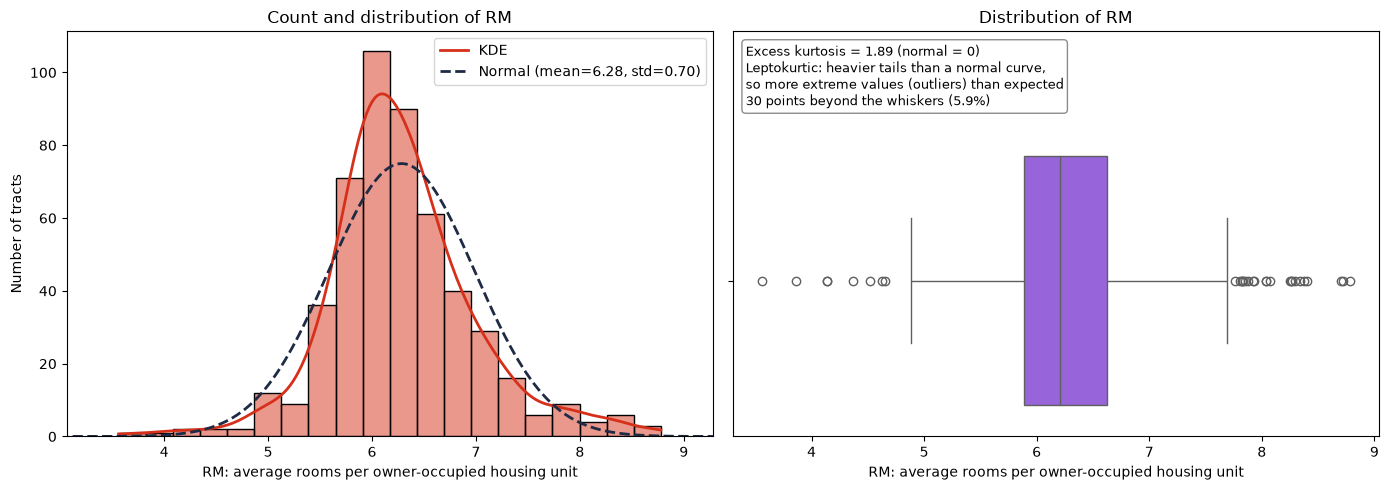

In [205]:
NORMAL_COLOUR = "#1F2A44"   # colour of the dashed normal curve - change this to customise it

x = df["RM"]
n_bins = 20
bin_width = (x.max() - x.min()) / n_bins

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (left)
sns.histplot(data=df, x="RM", bins=n_bins, kde=True, color="#D6301A",
             line_kws={"linewidth": 2, "color": "crimson", "label": "KDE"}, ax=axes[0])

# Perfect normal curve using the sample mean and std, scaled from density to counts so it sits on the histogram
grid = np.linspace(x.min() - 3 * x.std(), x.max() + 3 * x.std(), 500)
normal_counts = stats.norm.pdf(grid, loc=x.mean(), scale=x.std()) * len(x) * bin_width
axes[0].plot(grid, normal_counts, linestyle="--", linewidth=2, color=NORMAL_COLOUR,
             label=f"Normal (mean={x.mean():.2f}, std={x.std():.2f})")
axes[0].set_xlim(x.min() - 0.5, x.max() + 0.5)
axes[0].set_title("Count and distribution of RM")
axes[0].set_xlabel(LABELS["RM"])
axes[0].set_ylabel(TRACTS)
axes[0].legend()

# Boxplot (right)
sns.boxplot(data=df, x="RM", color="#9550EE", ax=axes[1])
axes[1].set_title("Distribution of RM")
axes[1].set_xlabel(LABELS["RM"])

# Kurtosis label. pandas .kurt() is excess kurtosis (normal = 0)
kurt = x.kurt()
if kurt > 0.5:
    shape = "Leptokurtic: heavier tails than a normal curve,\nso more extreme values (outliers) than expected"
elif kurt < -0.5:
    shape = "Platykurtic: lighter tails than a normal curve,\nso fewer extreme values than expected"
else:
    shape = "Mesokurtic: tails similar to a normal curve"

q1, q3 = x.quantile([0.25, 0.75])
n_out = ((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum()
axes[1].set_ylim(0.5, -0.8)   # headroom above the box for the label
axes[1].text(0.02, 0.97, f"Excess kurtosis = {kurt:.2f} (normal = 0)\n{shape}\n"
             f"{n_out} points beyond the whiskers ({n_out / len(x):.1%})",
             transform=axes[1].transAxes, va="top", ha="left", fontsize=9,
             bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "grey", "alpha": 0.9})

plt.tight_layout()
plt.show()

IQR = 0.738; fences: 4.778 to 7.731
Outliers: 8 below 4.78, 22 above 7.73


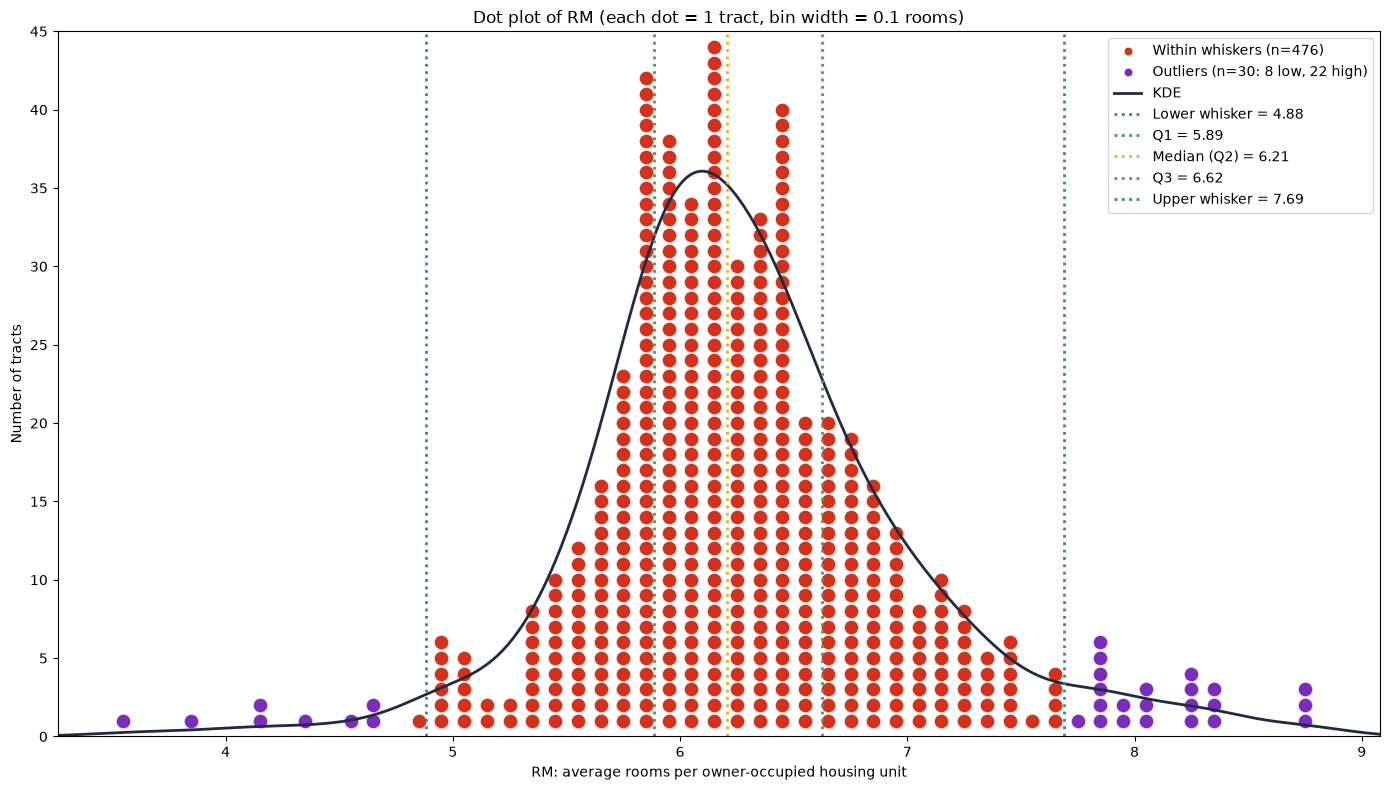

In [206]:
# Dot plot: one point per tract, x = RM, y = how many tracts share that RM (points stack, so none overlap).
# RM has 446 distinct values across 506 rows, so exact values would almost all stack to height 1 and
# neighbouring values (e.g. 6.001 and 6.002) would sit on top of each other. Values are therefore grouped
# into bins of BIN_WIDTH. Make it smaller to get closer to exact values.
BIN_WIDTH = 0.1
DOT_COLOUR = "#D6301A"
OUTLIER_COLOUR = "#7B2CBF"
KDE_COLOUR = "#1F2A44"
# Box plot lines (colours can be changed here)
SUMMARY_COLOURS = {"Lower whisker": "#2E86AB", "Q1": "#3FA34D", "Median (Q2)": "#F0B30B", "Q3": "#3FA34D", "Upper whisker": "#2E86AB"}

x = df["RM"]

# Same rule as the box plot: a point is an outlier if it is more than 1.5 x IQR beyond Q1 or Q3.
# Each whisker ends at the most extreme point still inside those fences.
q1, median, q3 = x.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (x < lower_fence) | (x > upper_fence)
lower_whisker = x[~is_outlier].min()
upper_whisker = x[~is_outlier].max()
n_low, n_high = (x < lower_fence).sum(), (x > upper_fence).sum()

bin_centre = (np.floor(x / BIN_WIDTH) + 0.5) * BIN_WIDTH
stack_height = bin_centre.groupby(bin_centre).cumcount() + 1   # 1, 2, 3 ... within each bin

fig, ax = plt.subplots(figsize=(14, 8))
ax.scatter(bin_centre[~is_outlier], stack_height[~is_outlier], color=DOT_COLOUR, edgecolor="white", linewidth=0.3,
           label=f"Within whiskers (n={(~is_outlier).sum()})")
ax.scatter(bin_centre[is_outlier], stack_height[is_outlier], color=OUTLIER_COLOUR, edgecolor="white", linewidth=0.3,
           label=f"Outliers (n={is_outlier.sum()}: {n_low} low, {n_high} high)")

# KDE, scaled from density to counts so it matches the dot stacks (same Scott bandwidth as sns.kdeplot)
grid = np.linspace(x.min() - 0.3, x.max() + 0.3, 500)
kde_counts = stats.gaussian_kde(x)(grid) * len(x) * BIN_WIDTH
ax.plot(grid, kde_counts, color=KDE_COLOUR, linewidth=2, label="KDE")

# Vertical lines for the five numbers the box plot draws
summary = {"Lower whisker": lower_whisker, "Q1": q1, "Median (Q2)": median, "Q3": q3, "Upper whisker": upper_whisker}
for name, value in summary.items():
    ax.axvline(value, color=SUMMARY_COLOURS[name], linestyle=":", linewidth=2, label=f"{name} = {value:.2f}")

ax.set_xlim(x.min() - 0.3, x.max() + 0.3)
ax.set_ylim(0, max(stack_height.max(), kde_counts.max()) + 1)
ax.set_xlabel(LABELS["RM"])
ax.set_ylabel(TRACTS)
ax.set_title(f"Dot plot of RM (each dot = 1 tract, bin width = {BIN_WIDTH} rooms)")
ax.legend(loc="upper right")
plt.tight_layout()

# Size the dots so neighbouring bins and neighbouring stack positions just touch rather than overlap
fig.canvas.draw()
px_per_x = abs(ax.transData.transform((BIN_WIDTH, 0))[0] - ax.transData.transform((0, 0))[0])
px_per_y = abs(ax.transData.transform((0, 1))[1] - ax.transData.transform((0, 0))[1])
diameter_pts = 0.9 * min(px_per_x, px_per_y) * 72 / fig.dpi
for collection in ax.collections:
    collection.set_sizes([diameter_pts ** 2])

print(f"IQR = {iqr:.3f}; fences: {lower_fence:.3f} to {upper_fence:.3f}")
print(f"Outliers: {n_low} below {lower_fence:.2f}, {n_high} above {upper_fence:.2f}")
plt.show()

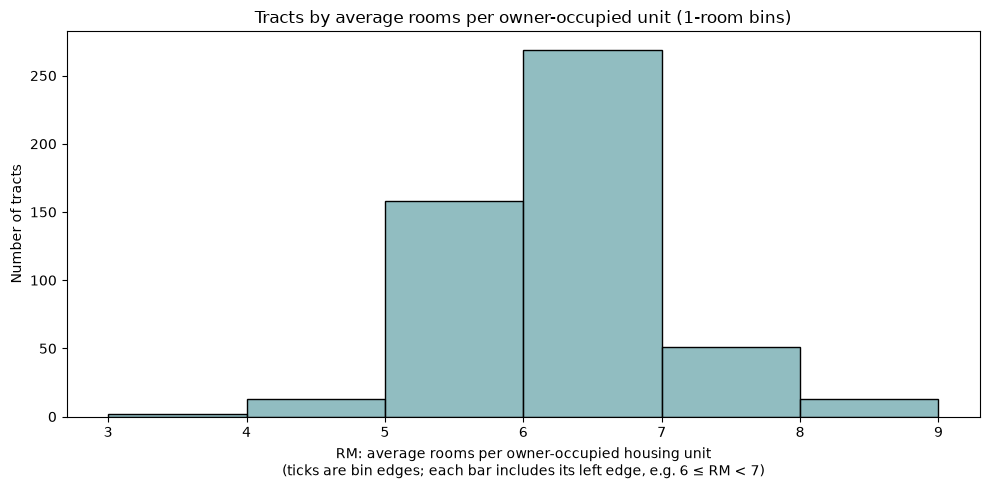

In [207]:
# Define exact integer boundaries (e.g., [3, 4, 5, 6, 7, 8, 9])
min_val = int(np.floor(df["RM"].min()))
max_val = int(np.ceil(df["RM"].max()))
bins = np.arange(min_val, max_val + 1)

plt.figure(figsize=(10, 5))
ax = sns.histplot(data=df, x="RM", bins=bins, color="#6DA7AC")

# Set x-ticks directly at each integer edge
ax.set_xticks(bins)
ax.set_title("Tracts by average rooms per owner-occupied unit (1-room bins)")
ax.set_xlabel(LABELS["RM"] + "\n(ticks are bin edges; each bar includes its left edge, e.g. 6 ≤ RM < 7)")
ax.set_ylabel(TRACTS)
plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `RM`

- **Shape:** the most bell-shaped feature. The mean is 6.28 rooms, the median 6.21 and the standard deviation 0.70, with only a mild right skew (0.40). The middle half of tracts is tightly packed between 5.89 and 6.62 rooms (IQR = 0.74). The most common 1-room band is 6 to 7 rooms (about 270 tracts), followed by 5 to 6 rooms (about 160).

- **Peakedness:** the distribution is taller and narrower than the fitted normal curve and has heavier tails (excess kurtosis = 1.89, leptokurtic).

- **Outliers:** 30 tracts (5.9%) fall outside the fences, on both sides: 8 below 4.78 rooms (the lowest is 3.56) and 22 above 7.73 (the highest is 8.78). These are plausible averages, so they should be kept.

- **Transformation:** not needed for skew. The heavy tails may be worth keeping an eye on.

### Univariate - `AGE`
Proportion of owner-occupied units built before 1940

In [208]:
print(f"Distinct values: {df['AGE'].nunique()} across {len(df)} rows")

Distinct values: 356 across 506 rows


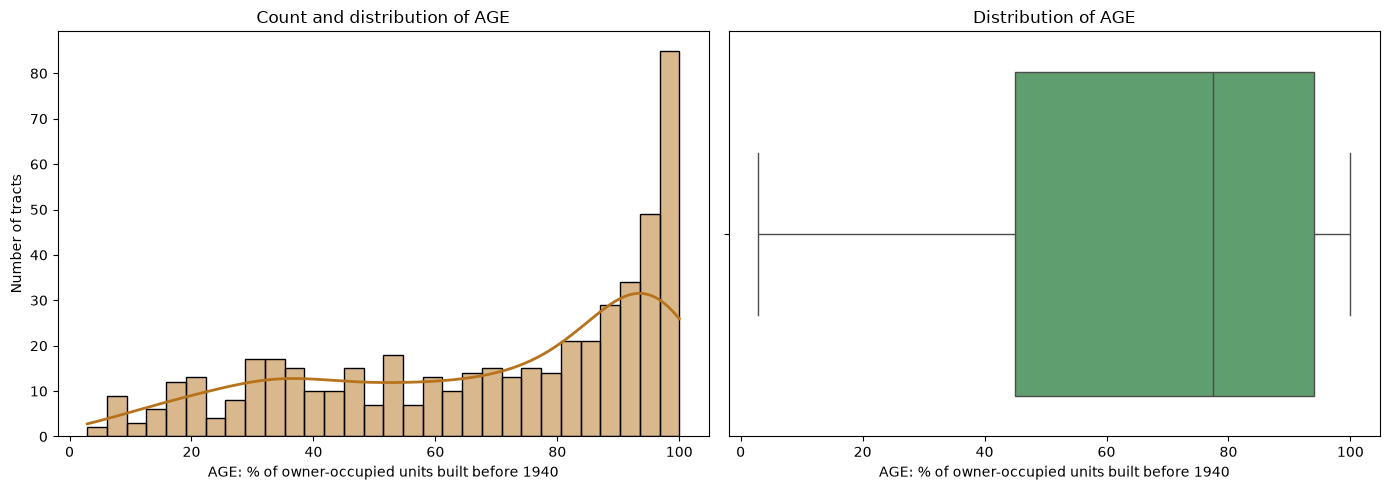

In [209]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (left)
sns.histplot(data=df, x="AGE", bins=30, kde=True, color="#B6731C",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title("Count and distribution of AGE")
axes[0].set_xlabel(LABELS["AGE"])
axes[0].set_ylabel(TRACTS)

# Boxplot (right)
sns.boxplot(data=df, x="AGE", color="#55A868", ax=axes[1])
axes[1].set_title("Distribution of AGE")
axes[1].set_xlabel(LABELS["AGE"])

plt.tight_layout()
plt.show()

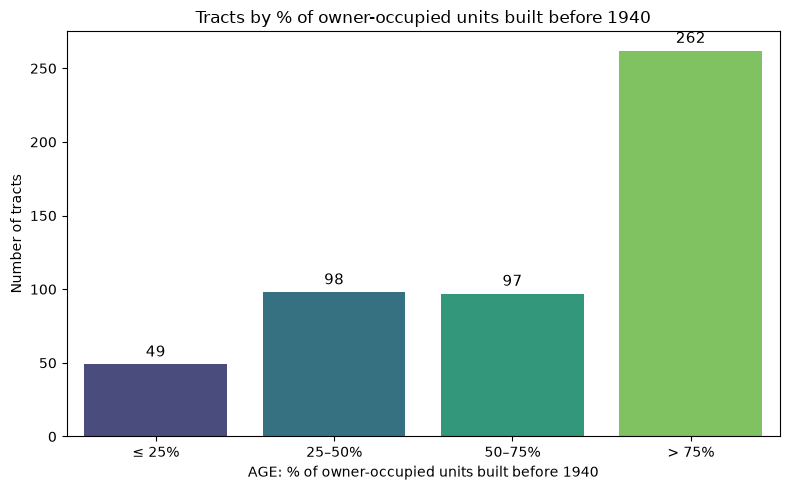

In [210]:
age_bins = pd.cut(df["AGE"], bins=[0, 25, 50, 75, 100], labels=["≤ 25%", "25–50%", "50–75%", "> 75%"])

plt.figure(figsize=(8, 5))
ax = sns.countplot(x=age_bins, hue=age_bins, palette="viridis", legend=False)

# Label each bar with its count
for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

ax.set_title("Tracts by % of owner-occupied units built before 1940")
ax.set_xlabel(LABELS["AGE"])
ax.set_ylabel(TRACTS)
plt.tight_layout()
plt.show()

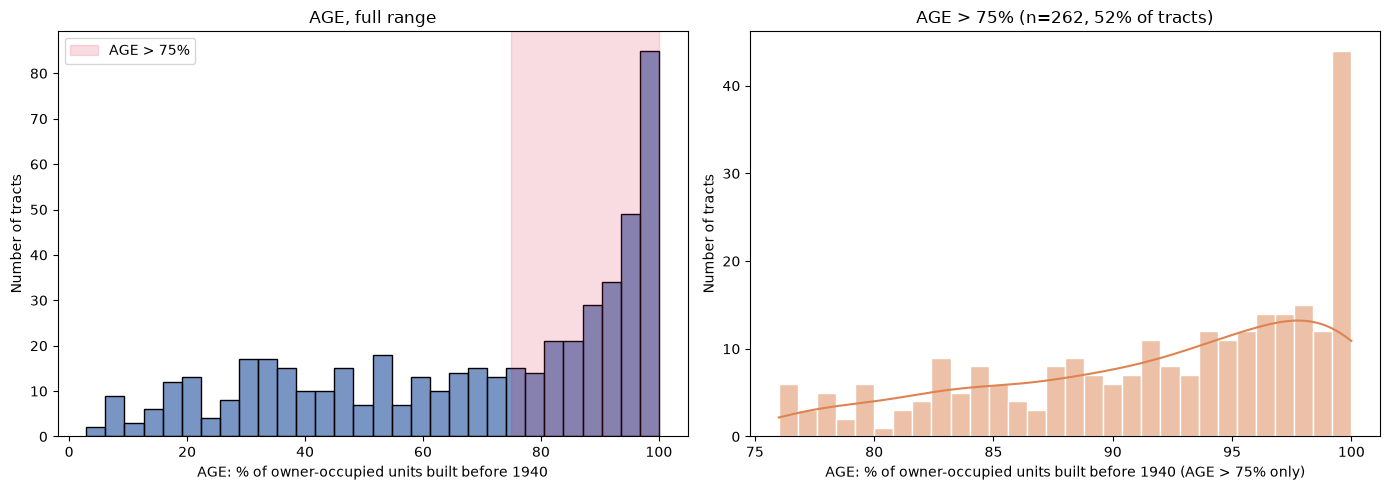

In [211]:
top = df[df["AGE"] > 75]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full distribution with the top bin highlighted
sns.histplot(data=df, x="AGE", bins=30, color="#4C72B0", ax=axes[0])
axes[0].axvspan(75, 100, color="crimson", alpha=0.15, label="AGE > 75%")
axes[0].set_title("AGE, full range")
axes[0].set_xlabel(LABELS["AGE"])
axes[0].set_ylabel(TRACTS)
axes[0].legend()

# Zoom on the top bin only
sns.histplot(data=top, x="AGE", bins=30, kde=True, color="#DD8452",
             edgecolor="white", ax=axes[1])
axes[1].set_title(f"AGE > 75% (n={len(top)}, {len(top)/len(df):.0%} of tracts)")
axes[1].set_xlabel(LABELS["AGE"] + " (AGE > 75% only)")
axes[1].set_ylabel(TRACTS)

plt.tight_layout()
plt.show()


In [212]:
print(f"The dataset contains {(df['AGE'] == 100).sum()} tracts where every owner-occupied unit was built before 1940 (AGE = 100).")

The dataset contains 43 tracts where every owner-occupied unit was built before 1940 (AGE = 100).


#### Observations from univariate analysis of `AGE`

- **Shape:** left-skewed (skew = -0.60). The mean (68.6) is below the median (77.5). Values range from 2.9 to 100, and the middle half of tracts lies between 45.0% and 94.1%. No outliers.

- **Concentration at the top:** 262 tracts (52%) have more than 75% of their owner-occupied units built before 1940. By quarter, the counts are 49 / 98 / 97 / 262. Below about 75% the histogram is roughly flat, and above 80% it climbs steeply.

- **Ceiling:** 43 tracts have AGE = 100, the most common value. This pile-up sits at the natural maximum of a percentage, so it is a ceiling effect rather than an error.

### Univariate - `DIS`
Weighted distance to five Boston employment centres

In [213]:
print(f"Distinct values: {df['DIS'].nunique()} across {len(df)} rows")
print(df["DIS"].value_counts().head(10))
print(f"Descriptive statistics for DIS:\n{df['DIS'].describe()}")

# IQR fences and outliers. Some outlier values are shared by more than one tract, so the boxplot shows fewer circles than outliers
q1, q3 = df["DIS"].quantile([0.25, 0.75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
outliers = df.loc[(df["DIS"] < lower) | (df["DIS"] > upper), "DIS"]
print(f"\nIQR fences: {lower:.2f} to {upper:.2f} -> {len(outliers)} outliers ({len(outliers) / len(df):.1%})")
print("Outlier values and the number of tracts at each:\n", outliers.value_counts().sort_index())

Distinct values: 412 across 506 rows
DIS
3.4952    5
5.7209    4
5.2873    4
6.8147    4
5.4007    4
6.3361    3
3.9454    3
6.4980    3
4.7211    3
4.8122    3
Name: count, dtype: int64
Descriptive statistics for DIS:
count    506.000000
mean       3.795043
std        2.105710
min        1.129600
25%        2.100175
50%        3.207450
75%        5.188425
max       12.126500
Name: DIS, dtype: float64

IQR fences: -2.53 to 9.82 -> 5 outliers (1.0%)
Outlier values and the number of tracts at each:
 DIS
10.5857    2
10.7103    2
12.1265    1
Name: count, dtype: int64


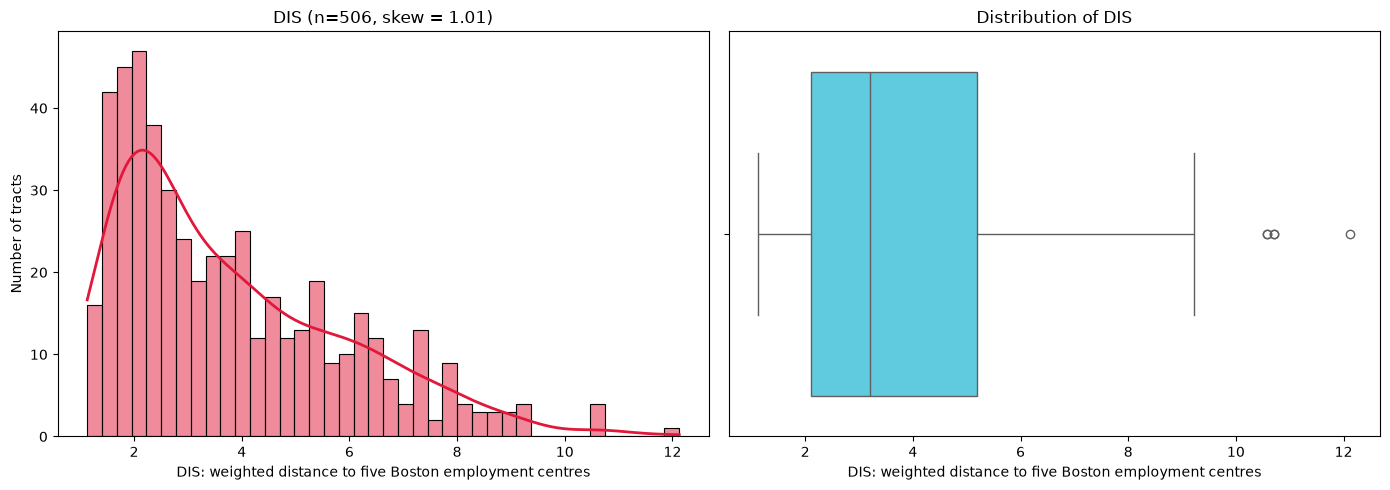

In [214]:
# Full DIS range, no filtering and no log transformation
dis = df["DIS"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(x=dis, bins=40, kde=True, color="#E2183A",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title(f"DIS (n={len(dis)}, skew = {dis.skew():.2f})")
axes[0].set_xlabel(LABELS["DIS"])
axes[0].set_ylabel(TRACTS)

sns.boxplot(x=dis, color="#4BDAF3", ax=axes[1])
axes[1].set_title("Distribution of DIS")
axes[1].set_xlabel(LABELS["DIS"])

plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `DIS`

- **Shape:** right-skewed (skew = 1.01). Values range from 1.13 to 12.13, with a median of 3.21 and a mean of 3.80. The middle half lies between 2.10 and 5.19. Counts peak around 2 and fall away steadily after that.

- **Outliers:** the upper fence is about 9.82 (5.19 + 1.5 × 3.09). Five tracts lie above it, but the boxplot shows only 3 circles because two of the values are each shared by two tracts. These are distant tracts, not errors.

- **Repeated values:** there are 412 distinct values, and the most common (3.4952) appears only 5 times, so DIS is effectively continuous.

- **Transformation:** every value is positive (minimum 1.13) and the skew is to the right, so a log is worth testing in preprocessing.

### Univariate - `RAD`
Index of accessibility to radial highways

In [215]:
print(f"Distinct values: {df['RAD'].nunique()} across {len(df)} rows")
print(f"Descriptive statistics for RAD:\n{df['RAD'].describe()}")

Distinct values: 9 across 506 rows
Descriptive statistics for RAD:
count    506.000000
mean       9.549407
std        8.707259
min        1.000000
25%        4.000000
50%        5.000000
75%       24.000000
max       24.000000
Name: RAD, dtype: float64


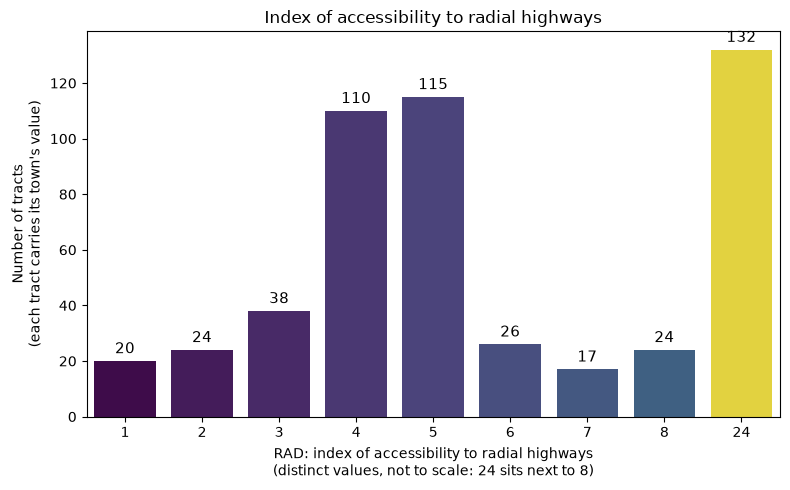

In [216]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x=df["RAD"], hue=df["RAD"], palette="viridis", legend=False)

# Label each bar with its count
for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)

ax.set_title("Index of accessibility to radial highways")
ax.set_xlabel(LABELS["RAD"] + "\n(distinct values, not to scale: 24 sits next to 8)")
ax.set_ylabel(TRACTS_TOWN)
plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `RAD`

- Type: 9 distinct values: 1 to 8, and 24. RAD is an index, so it should be read as categorical (ordered) rather than as a measured quantity. No values fall between 8 and 24, so 24 is a separate category and does not mean "three times as accessible as 8".
- Counts: 24 is the most common value (132 tracts, 26%), followed by 5 (115) and 4 (110). Values 4 and 5 together account for 225 tracts (44%). Each of the remaining six values has between 17 and 38 tracts.
- Misleading summary statistics: the mean (9.55) lands in the empty gap between 8 and 24, and no tract has a value near it. The median is 5. The skew of 1.00 and Q3 = 24 both come from the 24 group.
- Outliers: none. The 24 group is too large (Q3 is 24 itself) to count as outliers.

### Univariate - `TAX`
Full-value property tax rate per $10,000

In [217]:
print(f"Distinct values: {df['TAX'].nunique()} across {len(df)} rows")
print(f"Descriptive statistics for TAX:\n{df['TAX'].describe()}")

# Most frequent values, and every value from 450 up, to show the gap between the two clusters
print("\nMost frequent TAX values:\n", df["TAX"].value_counts().head(5))
print("\nTAX values of 450 and above:\n", df.loc[df["TAX"] >= 450, "TAX"].value_counts().sort_index())

Distinct values: 66 across 506 rows
Descriptive statistics for TAX:
count    506.000000
mean     408.237154
std      168.537116
min      187.000000
25%      279.000000
50%      330.000000
75%      666.000000
max      711.000000
Name: TAX, dtype: float64

Most frequent TAX values:
 TAX
666    132
307     40
403     30
437     15
304     14
Name: count, dtype: int64

TAX values of 450 and above:
 TAX
469      1
666    132
711      5
Name: count, dtype: int64


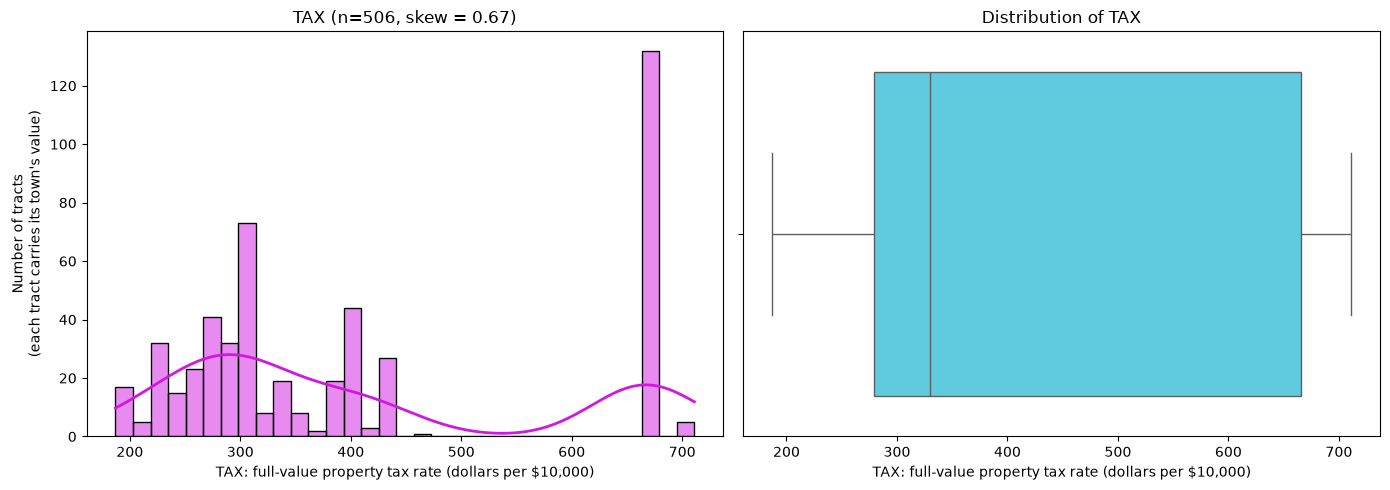

In [218]:
dis = df["TAX"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(x=dis, bins=33, kde=True, color="#D118E2",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title(f"TAX (n={len(dis)}, skew = {dis.skew():.2f})")
axes[0].set_xlabel(LABELS["TAX"])
axes[0].set_ylabel(TRACTS_TOWN)

sns.boxplot(x=dis, color="#4BDAF3", ax=axes[1])
axes[1].set_title("Distribution of TAX")
axes[1].set_xlabel(LABELS["TAX"])

plt.tight_layout()
plt.show()

TAX_group
lower     369
higher    137
Name: count, dtype: int64


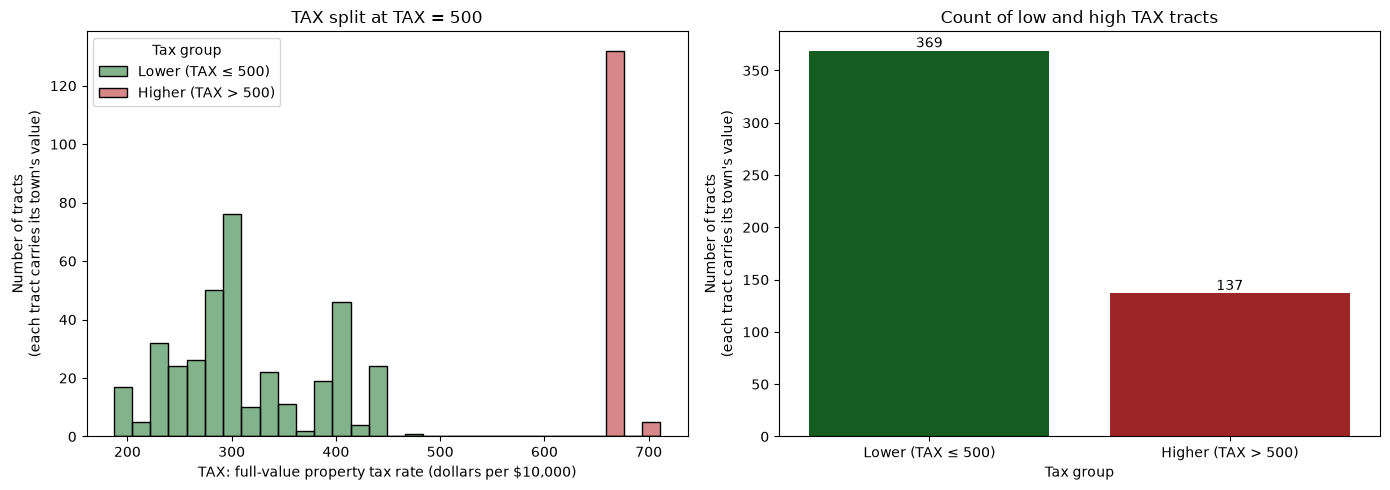

In [219]:
# Threshold of 500 separates the low-TAX and higher-TAX clusters.
df["TAX_group"] = np.where(df["TAX"] > 500, "higher", "lower")
print(df["TAX_group"].value_counts())

palette = {"lower": "#086818", "higher": "#B11111"}
group_names = {"lower": "Lower (TAX ≤ 500)", "higher": "Higher (TAX > 500)"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram split by group (left)
sns.histplot(data=df, x="TAX", hue="TAX_group", palette=palette, bins=30, ax=axes[0])
axes[0].set_xlabel(LABELS["TAX"])
axes[0].set_ylabel(TRACTS_TOWN)
axes[0].set_title("TAX split at TAX = 500")
legend = axes[0].get_legend()
legend.set_title("Tax group")
for text in legend.get_texts():
    text.set_text(group_names[text.get_text()])

# Count of each group (right)
sns.countplot(data=df, x="TAX_group", hue="TAX_group", order=["lower", "higher"], palette=palette, legend=False, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container)
axes[1].set_title("Count of low and high TAX tracts")
axes[1].set_xticks([0, 1], [group_names["lower"], group_names["higher"]])
axes[1].set_xlabel("Tax group")
axes[1].set_ylabel(TRACTS_TOWN)

plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `TAX`

- **Shape:** bimodal, with two separate clusters. The lower cluster runs from 187 to about 470 (369 tracts, 73%). The higher cluster sits at 666 and 711 (137 tracts, 27%). No tracts fall between about 470 and 666.

- **Spike:** 666 is the most common value (132 tracts). That spike is why Q3 is exactly 666.

- **Summary statistics:** the median is 330, but the high cluster pulls the mean up to 408, which lands in the empty gap. The skew of 0.67 understates how far TAX is from normal, because the real issue is the two clusters, not the tail.

- **Outliers:** none. The high cluster is more than a quarter of the data, so the whiskers reach both ends.

### Univariate - `PTRATIO`
Pupil-teacher ratio 

In [220]:
print(f"Distinct values: {df['PTRATIO'].nunique()} across {len(df)} rows")
print(f"Descriptive statistics for PTRATIO:\n{df['PTRATIO'].describe()}")

Distinct values: 46 across 506 rows
Descriptive statistics for PTRATIO:
count    506.000000
mean      18.455534
std        2.164946
min       12.600000
25%       17.400000
50%       19.050000
75%       20.200000
max       22.000000
Name: PTRATIO, dtype: float64


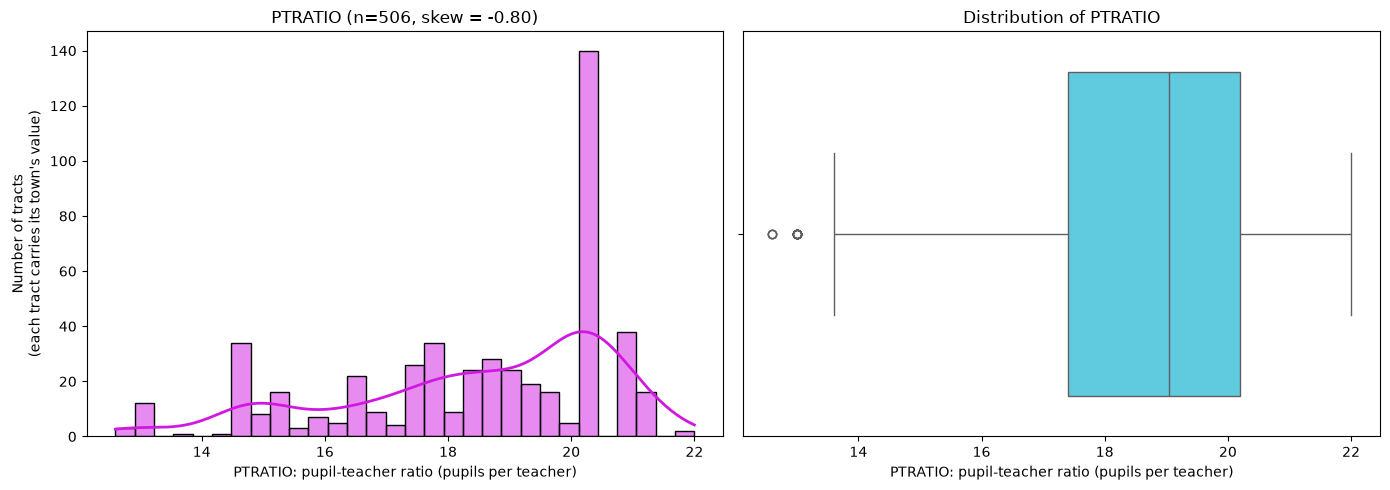

In [221]:
dis = df["PTRATIO"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(x=dis, bins=30, kde=True, color="#D118E2",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title(f"PTRATIO (n={len(dis)}, skew = {dis.skew():.2f})")
axes[0].set_xlabel(LABELS["PTRATIO"])
axes[0].set_ylabel(TRACTS_TOWN)

sns.boxplot(x=dis, color="#4BDAF3", ax=axes[1])
axes[1].set_title("Distribution of PTRATIO")
axes[1].set_xlabel(LABELS["PTRATIO"])

plt.tight_layout()
plt.show()

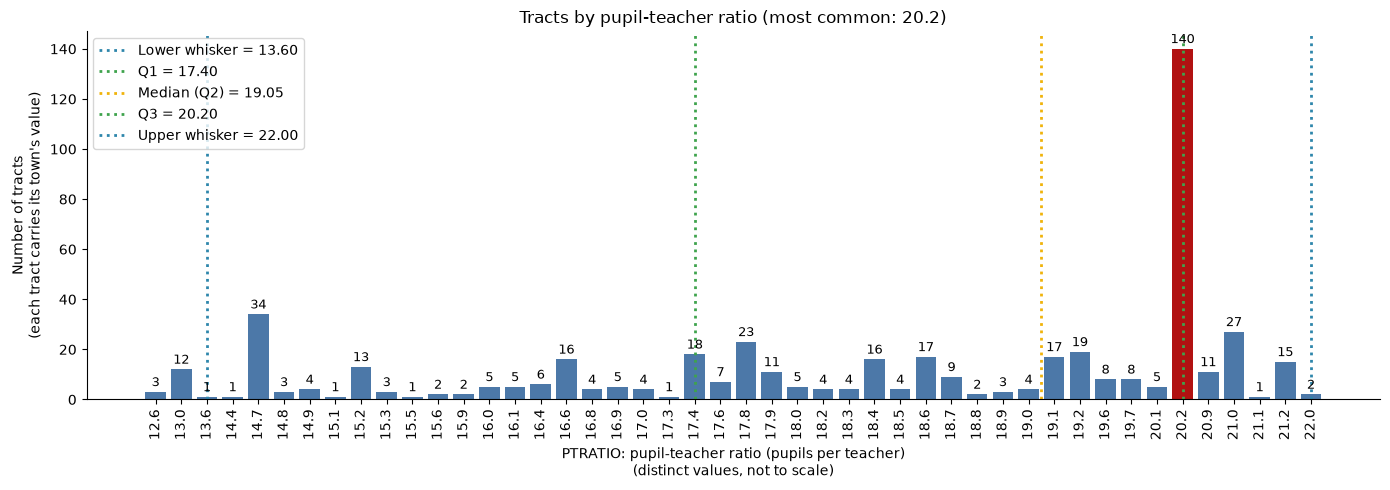

In [222]:
# One bar per distinct ratio, in numeric order; the most common ratio is highlighted
x = df["PTRATIO"]
counts = x.value_counts().sort_index()
colors = ["#B11111" if n == counts.max() else "#4C78A8" for n in counts]

# The five numbers the box plot draws: whiskers end at the most extreme points within 1.5 x IQR of Q1 and Q3
q1, median, q3 = x.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
inside = x[(x >= q1 - 1.5 * iqr) & (x <= q3 + 1.5 * iqr)]
summary = {"Lower whisker": inside.min(), "Q1": q1, "Median (Q2)": median, "Q3": q3, "Upper whisker": inside.max()}
line_colours = {"Lower whisker": "#2E86AB", "Q1": "#3FA34D", "Median (Q2)": "#F0B30B", "Q3": "#3FA34D", "Upper whisker": "#2E86AB"}

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(counts.index.astype(str), counts.values, color=colors)
ax.bar_label(ax.containers[0], fontsize=9, padding=2)

# Bars sit at positions 0, 1, 2, ..., so convert each value to a bar position (a value between two bars lands between them)
for name, value in summary.items():
    ax.axvline(np.interp(value, counts.index, np.arange(len(counts))), color=line_colours[name],
               linestyle=":", linewidth=2, label=f"{name} = {value:.2f}")

ax.tick_params(axis="x", rotation=90)
ax.set_title(f"Tracts by pupil-teacher ratio (most common: {counts.idxmax()})")
ax.set_xlabel(LABELS["PTRATIO"] + "\n(distinct values, not to scale)")
ax.set_ylabel(TRACTS_TOWN)
ax.legend(loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `PTRATIO`

- Of the 506 tracts, there were never more than 22 pupils for every teacher.

- By far the most common ratio was 20.2 students for every teacher. This occured in 106 more tracts than the next most common ratio of 14.7 students for every teacher.

- **Shape:** left-skewed (skew = -0.80). Values range from 12.6 to 22.0, with a median of 19.05 and a mean of 18.46. The middle half lies between 17.4 and 20.2.

- **Spike:** 20.2 accounts for 140 tracts (28%). That spike is why Q3 is exactly 20.2.

- **Outliers:** 15 tracts fall below the lower fence of 13.2: 3 at 12.6 and 12 at 13.0. The boxplot shows them as only 2 circles because each circle is a repeated value. They are real low ratios.

- **Discrete:** 46 distinct values, each recorded to one decimal place.


### Univariate - `LSTAT`
% of the population classed as lower status (per tract)

In [223]:
print(f"Distinct values: {df['LSTAT'].nunique()} across {len(df)} rows")
print(f"Descriptive statistics for LSTAT:\n{df['LSTAT'].describe()}")

# IQR fences and outliers
q1, q3 = df["LSTAT"].quantile([0.25, 0.75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
outliers = df.loc[(df["LSTAT"] < lower) | (df["LSTAT"] > upper), "LSTAT"]
print(f"\nIQR fences: {lower:.2f} to {upper:.2f} -> {len(outliers)} outliers ({len(outliers) / len(df):.1%})")
print("Outlier values and the number of tracts at each:\n", outliers.value_counts().sort_index())

Distinct values: 455 across 506 rows
Descriptive statistics for LSTAT:
count    506.000000
mean      12.653063
std        7.141062
min        1.730000
25%        6.950000
50%       11.360000
75%       16.955000
max       37.970000
Name: LSTAT, dtype: float64

IQR fences: -8.06 to 31.96 -> 7 outliers (1.4%)
Outlier values and the number of tracts at each:
 LSTAT
31.99    1
34.02    1
34.37    1
34.41    1
34.77    1
36.98    1
37.97    1
Name: count, dtype: int64


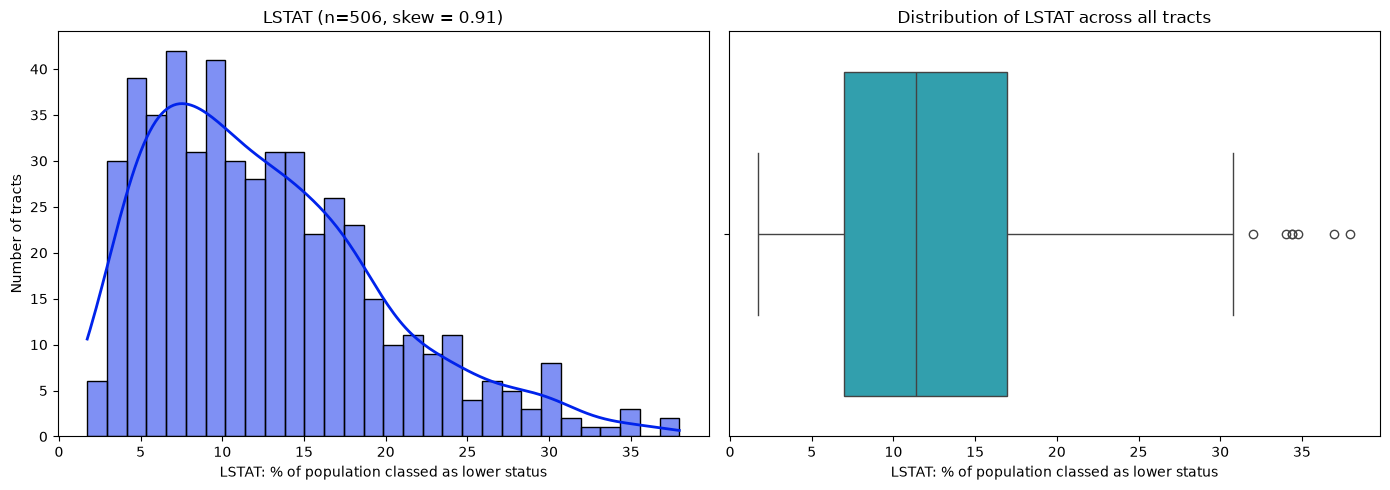

In [224]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (left)
sns.histplot(data=df, x="LSTAT", bins=30, kde=True, color="#0023EB",
             line_kws={"linewidth": 2, "color": "crimson"}, ax=axes[0])
axes[0].set_title(f"LSTAT (n={len(df['LSTAT'])}, skew = {df['LSTAT'].skew():.2f})")
axes[0].set_xlabel(LABELS["LSTAT"])
axes[0].set_ylabel(TRACTS)

# Boxplot (right)
sns.boxplot(data=df, x="LSTAT", color="#1DAFC2", ax=axes[1])
axes[1].set_title("Distribution of LSTAT across all tracts")
axes[1].set_xlabel(LABELS["LSTAT"])

plt.tight_layout()
plt.show()

#### Observations from univariate analysis of `LSTAT`

- **Shape:** right-skewed (skew = 0.91). Values range from 1.73% to 37.97%, with a median of 11.36 and a mean of 12.65. The middle half lies between 6.95 and 16.96. Counts peak around 5 to 10% and then tail off to the right.

- **Outliers:** the upper fence is about 31.96 (16.96 + 1.5 × 10.01). Seven tracts lie above it (32.0 to 38.0), and there are none on the low side. They are real values.

- **Transformation:** every value is positive and the skew is to the right, so a log is worth testing.

### Univariate - `MEDV`
Median value of owner-occupied housing unit, in $1,000s (1970 dollars)
This is the dependant (target) variable for the entire project.

In [225]:
print(f"Distinct values: {df['MEDV'].nunique()} across {len(df)} rows")
print (f"Description:\n{df['MEDV'].describe()}")
print (f"head:\n{df['MEDV'].head(10)}")

Distinct values: 229 across 506 rows
Description:
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64
head:
0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
5    28.7
6    22.9
7    27.1
8    16.5
9    18.9
Name: MEDV, dtype: float64


IQR = 7.975; fences: 5.062 to 36.963
Outliers: 2 below 5.06, 38 above 36.96


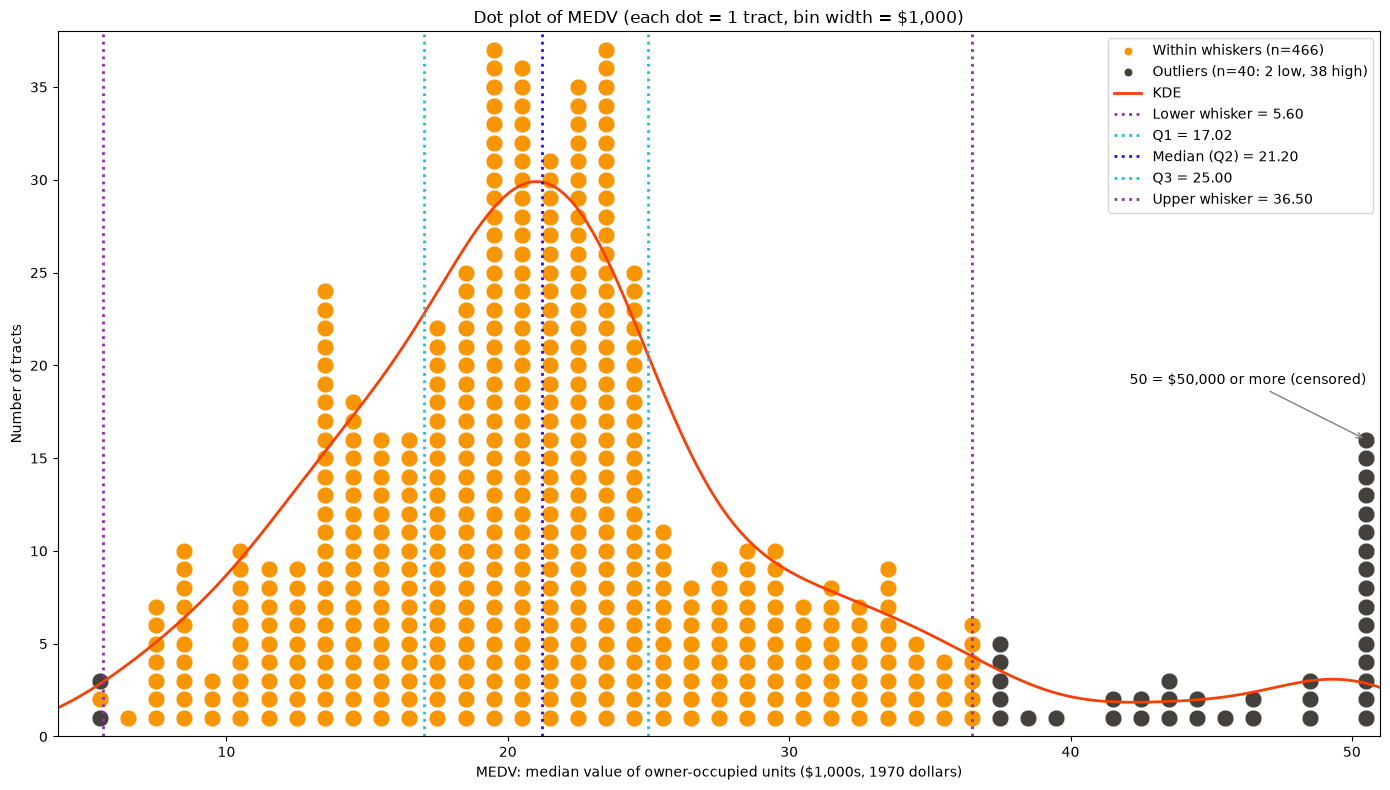

In [226]:
# Dot plot: one point per tract, x = MEDV, y = how many tracts share that MEDV (points stack, so none overlap).
# MEDV has 229 distinct values across 506 rows, so exact values would almost all stack to height 1 and neighbouring values (e.g. 6.001 and 6.002) would sit on top of each other. Values are therefore grouped into bins of BIN_WIDTH. Make it smaller to get closer to exact values.
BIN_WIDTH = 1.0
DOT_COLOUR = "#F79503"
OUTLIER_COLOUR = "#44413D"
KDE_COLOUR = "#F74008"
# Box plot lines (colours can be changed here)
SUMMARY_COLOURS = {"Lower whisker": "#922EAB", "Q1": "#0AC5F3", "Median (Q2)": "#2D0BF0", "Q3": "#0AC5F3", "Upper whisker": "#922EAB"}

x = df["MEDV"]

# Same rule as the box plot: a point is an outlier if it is more than 1.5 x IQR beyond Q1 or Q3.
# Each whisker ends at the most extreme point still inside those fences.
q1, median, q3 = x.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (x < lower_fence) | (x > upper_fence)
lower_whisker = x[~is_outlier].min()
upper_whisker = x[~is_outlier].max()
n_low, n_high = (x < lower_fence).sum(), (x > upper_fence).sum()

bin_centre = (np.floor(x / BIN_WIDTH) + 0.5) * BIN_WIDTH
stack_height = bin_centre.groupby(bin_centre).cumcount() + 1   # 1, 2, 3 ... within each bin

fig, ax = plt.subplots(figsize=(14, 8))
ax.scatter(bin_centre[~is_outlier], stack_height[~is_outlier], color=DOT_COLOUR, edgecolor="white", linewidth=0.3,
           label=f"Within whiskers (n={(~is_outlier).sum()})")
ax.scatter(bin_centre[is_outlier], stack_height[is_outlier], color=OUTLIER_COLOUR, edgecolor="white", linewidth=0.3,
           label=f"Outliers (n={is_outlier.sum()}: {n_low} low, {n_high} high)")

# KDE, scaled from density to counts so it matches the dot stacks (same Scott bandwidth as sns.kdeplot)
grid = np.linspace(x.min() - BIN_WIDTH, x.max() + BIN_WIDTH, 500)
kde_counts = stats.gaussian_kde(x)(grid) * len(x) * BIN_WIDTH
ax.plot(grid, kde_counts, color=KDE_COLOUR, linewidth=2, label="KDE")

# Vertical lines for the five numbers the box plot draws
summary = {"Lower whisker": lower_whisker, "Q1": q1, "Median (Q2)": median, "Q3": q3, "Upper whisker": upper_whisker}
for name, value in summary.items():
    ax.axvline(value, color=SUMMARY_COLOURS[name], linestyle=":", linewidth=2, label=f"{name} = {value:.2f}")

ax.set_xlim(x.min() - BIN_WIDTH, x.max() + BIN_WIDTH)
ax.set_ylim(0, max(stack_height.max(), kde_counts.max()) + 1)
ax.set_xlabel(LABELS["MEDV"])
ax.set_ylabel(TRACTS)
ax.set_title(f"Dot plot of MEDV (each dot = 1 tract, bin width = ${BIN_WIDTH * 1000:,.0f})")
# MEDV is censored at 50: a value of 50 means $50,000 or more, not exactly $50,000
ax.annotate("50 = $50,000 or more (censored)", xy=(bin_centre[x == 50].iloc[0], stack_height[x == 50].max()),
            xytext=(0, 40), textcoords="offset points", ha="right", arrowprops={"arrowstyle": "->", "color": "grey"})
ax.legend(loc="upper right")
plt.tight_layout()

# Size the dots so neighbouring bins and neighbouring stack positions just touch rather than overlap
fig.canvas.draw()
px_per_x = abs(ax.transData.transform((BIN_WIDTH, 0))[0] - ax.transData.transform((0, 0))[0])
px_per_y = abs(ax.transData.transform((0, 1))[1] - ax.transData.transform((0, 0))[1])
diameter_pts = 0.9 * min(px_per_x, px_per_y) * 72 / fig.dpi
for collection in ax.collections:
    collection.set_sizes([diameter_pts ** 2])

print(f"IQR = {iqr:.3f}; fences: {lower_fence:.3f} to {upper_fence:.3f}")
print(f"Outliers: {n_low} below {lower_fence:.2f}, {n_high} above {upper_fence:.2f}")
plt.show()

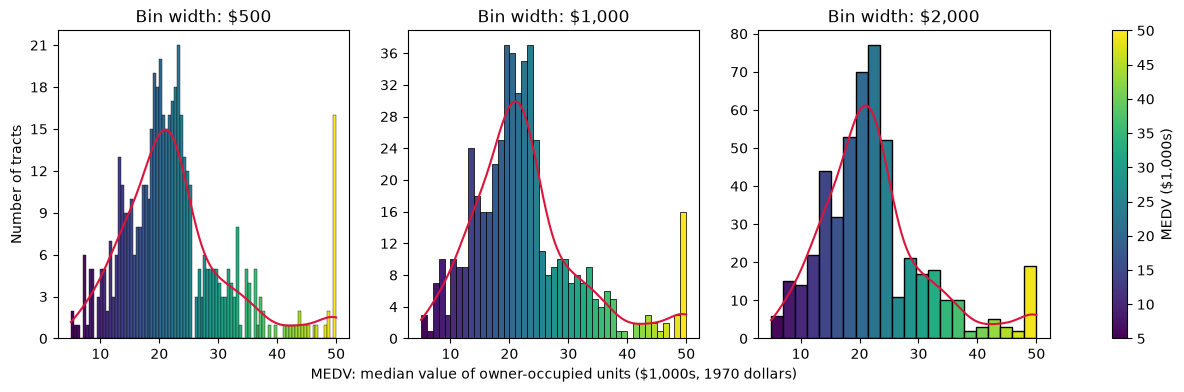

In [227]:
# Checking for binning artefacts: same data, same range, three fixed bin widths ($1000s)
# Bars are coloured by MEDV value (viridis); the KDE line is crimson so it stays visible on top.
cmap, norm = plt.get_cmap("viridis"), plt.Normalize(5, 50)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, w in zip(axes, [0.5, 1, 2]):
    sns.histplot(data=df, x="MEDV", binwidth=w, binrange=(5, 50), kde=True, ax=ax)
    for bar in ax.patches:
        bar.set_facecolor(cmap(norm(bar.get_x() + bar.get_width() / 2)))
    for line in ax.lines:
        line.set_color("crimson")
    ax.set_title(f"Bin width: ${w * 1000:,.0f}")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))   # counts are whole tracts
# One x label under the middle panel serves all three
axes[0].set_ylabel(TRACTS)
axes[1].set_xlabel(LABELS["MEDV"])
# The bar colours repeat the MEDV value, so the colour bar uses the same scale as the x-axis
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, label="MEDV ($1,000s)")
plt.show()

#### Observations from univariate analysis of `MEDV`

- **Shape:** right-skewed (skew = 1.11). Values range from 5 to 50 ($5,000 to $50,000), with a median of 21.2 and a mean of 22.53. The middle half lies between 17.0 and 25.0, and the main peak is around $19,000 to $24,000.

- **Censoring:** 16 tracts sit at exactly 50.0, which is the most common value. The spike persists at bin widths of $500, $1,000 and $2,000, so it comes from the cap (50 means $50,000 or more) and not from binning. The 2 tracts at 5.0 are the lower cap.

- **Outliers:** 40 tracts (7.9%) lie outside the whiskers. The 2 low ones are both 5.0. Of the 38 high ones, 16 are the capped 50s and the other 22 are spread between about 37 and 49.

- **Implication:** the true values of the 16 capped tracts are unknown, so the right tail is cut off. A log transformation of MEDV is worth testing.

#### **Question 3: What are all the inferences that can be found by doing univariate analysis for different variables?**

#### **Question 1: What does the distribution of 'MEDV' look like?**

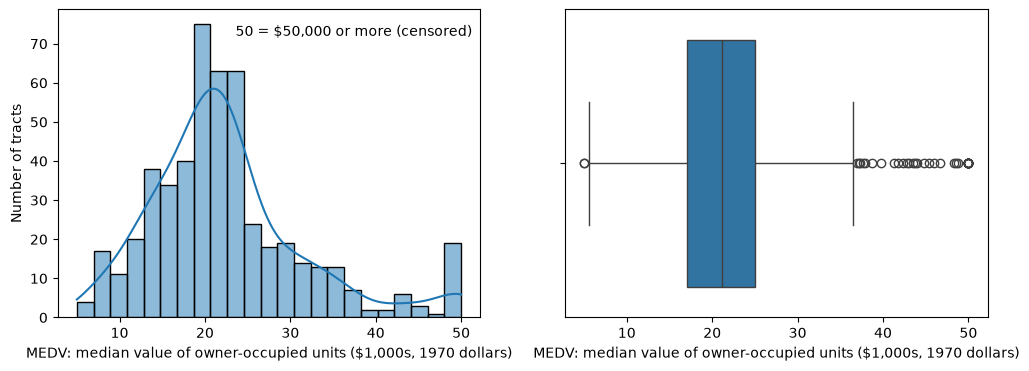

The distribution of MEDV is right-skewed (skew = 1.11), with a spike at the maximum value: 16 rows have MEDV of 50 (the censoring cap).


In [228]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["MEDV"], kde=True, ax=ax[0])
sns.boxplot(x=df["MEDV"], ax=ax[1])
ax[0].set_xlabel(LABELS["MEDV"])
ax[0].set_ylabel(TRACTS)
ax[0].text(0.98, 0.95, "50 = $50,000 or more (censored)", transform=ax[0].transAxes, ha="right", va="top")
ax[1].set_xlabel(LABELS["MEDV"])
plt.show()
print(f"The distribution of MEDV is right-skewed (skew = {df['MEDV'].skew():.2f}), with a spike at the maximum value: {(df['MEDV'] == 50).sum()} rows have MEDV of 50 (the censoring cap).")

- A log transformation of MEDV is worth testing in preprocessing.

#### **Answer 1:**
- MEDV is right-skewed (skew ~1.1) with mean ~22.5 and median ~21.2.
- There is a spike at 50 (16 rows), which suggests the value was capped when the data was collected. The boxplot flags 40 points as outliers, mostly the high end.

## Bivariate analysis

Every comparison in this section uses exactly **two features at a time**. Each row is still one tract, so every count is a count of tracts. `MEDV` is the target, so the section has three parts:

1. **Screening every pair.** All 78 pairs of the 13 features are ranked by two correlation measures. This is a table of pairs, not a heatmap. The heatmap belongs to the multivariate analysis.
2. **Each feature against `MEDV`.** The 12 features, in the same order as the univariate analysis.
3. **Feature against feature.** Every pair with |r| ≥ 0.7 (Question 4), plus the six pairs, all involving `CRIM`, that only reach 0.7 when measured by rank.

**How each kind of claim is demonstrated**

| Claim | Evidence used |
|---|---|
| Direction and strength | Pearson r (how close the points lie to a straight line) and Spearman ρ (how consistently one feature rises or falls as the other rises, whatever the shape) |
| Straight or curved | A LOWESS curve (a local average that assumes no shape) drawn against the straight least-squares line. R² of a straight line against R² with a squared term added. A Spearman ρ clearly larger than Pearson r |
| Whether a log straightens it | Pearson r recomputed after taking the log of one feature, the other, or both |
| Spread that changes along the line (fan shape) | Breusch-Pagan test on the straight-line fit, and the IQR of the second feature within equal-count bins of the first |
| Steps and thresholds | The median of the second feature within equal-count bins of the first |
| Effect of the `MEDV` cap at 50 | Pearson r with and without the 16 capped tracts |
| A correlation created by one cluster | Pearson r inside each cluster, and r over distinct value pairs only (so a town's value pair counts once, not once per tract) |
| Differences between groups (`CHAS`, `RAD`, the univariate groups) | Group medians, with a Mann-Whitney U test (two groups) or Kruskal-Wallis test (more than two) |

In [229]:
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

# The 13 original columns. The univariate analysis added helper columns to df (CRIM_log, CRIM_group, INDUS_group,
# OnRiver, TAX_group), so pair-wise work uses this list rather than df.columns
FEATURES = list(LABELS)

# Colours for every bivariate graph
POINT_COLOUR = "#2a78d6"     # one dot per tract
LINE_COLOUR = "#eb6834"      # straight least-squares line (dashed)
LOWESS_COLOUR = "#1F2A44"    # LOWESS curve: a local average that assumes no shape, so it shows any bend
CAPPED_COLOUR = "#44413D"    # tracts at MEDV = 50 ($50,000 or more), drawn as crosses
BOX_COLOUR = "#9ec5f4"       # box plots of one feature within bins of the other
GROUP_COLOURS = ["#2a78d6", "#eb6834"]   # two-group comparisons: first group blue, second orange

CAPPED = df["MEDV"] == 50
LOWESS_FRAC = 0.4   # share of tracts in each local average


def can_smooth(x):
    """A LOWESS curve needs neighbouring x values to average over. When one value holds more tracts than a
    single local average uses (ZN = 0 holds 74%, CHAS = 0 holds 93%), the curve there is meaningless."""
    return x.nunique() > 2 and x.value_counts().iloc[0] < LOWESS_FRAC * len(x)


def two_groups(mask, names):
    """Labels each tract names[1] where mask is True and names[0] elsewhere, keeping that order in tables and plots."""
    return pd.Series(pd.Categorical(np.where(mask, names[1], names[0]), categories=names), index=mask.index)


def pair_stats(x, y):
    """Prints the numbers behind each bivariate observation for one pair."""
    r, p_r = stats.pearsonr(x, y)
    rho, p_rho = stats.spearmanr(x, y)
    straight = sm.OLS(y, sm.add_constant(x)).fit()
    curved = sm.OLS(y, sm.add_constant(pd.DataFrame({"x": x, "x squared": x ** 2}))).fit()
    bp_p = het_breuschpagan(straight.resid, straight.model.exog)[1]
    print(f"{y.name} against {x.name}, {len(x)} tracts")
    print(f"Pearson r:     {r:+.3f}  (p = {p_r:.1e})")
    print(f"Spearman rho:  {rho:+.3f}  (p = {p_rho:.1e})   |rho| - |r| = {abs(rho) - abs(r):+.3f}")
    print(f"R-squared, straight line: {straight.rsquared:.3f}   with a squared term: {curved.rsquared:.3f}   "
          f"(gain {curved.rsquared - straight.rsquared:+.3f})")
    print(f"Breusch-Pagan p = {bp_p:.1e}  (below 0.05: the spread around the straight line changes with {x.name})")
    if y.name == "MEDV":
        keep = y < 50
        print(f"Pearson r without the {(~keep).sum()} capped tracts (MEDV = 50): "
              f"{stats.pearsonr(x[keep], y[keep])[0]:+.3f}")


def log_check(x, y):
    """Pearson r before and after taking logs, to see which version lies closest to a straight line."""
    versions = {
        f"{x.name} and {y.name}": (x, y),
        f"log({x.name}) and {y.name}": (np.log(x), y),
        f"{x.name} and log({y.name})": (x, np.log(y)),
        f"log({x.name}) and log({y.name})": (np.log(x), np.log(y)),
    }
    for name, (a, b) in versions.items():
        print(f"Pearson r, {name:<26} {a.corr(b):+.3f}")


def scatter_fit(ax, x, y, logx=False):
    """Scatter of y against x with the straight least-squares line and a LOWESS curve.
    With logx=True both lines are fitted to log(x) and the x-axis is drawn on a log scale.
    When y is MEDV, the capped tracts (MEDV = 50) are drawn as crosses."""
    fit_x = np.log(x) if logx else x
    capped = (y == 50) if y.name == "MEDV" else pd.Series(False, index=y.index)
    ax.scatter(x[~capped], y[~capped], s=18, alpha=0.5, color=POINT_COLOUR, edgecolor="white", linewidth=0.3,
               label="Tract")
    if capped.any():
        ax.scatter(x[capped], y[capped], s=36, marker="X", color=CAPPED_COLOUR,
                   label=f"MEDV = 50, capped ({capped.sum()} tracts)")
    slope, intercept = np.polyfit(fit_x, y, 1)
    grid = np.linspace(fit_x.min(), fit_x.max(), 200)
    ax.plot(np.exp(grid) if logx else grid, intercept + slope * grid, color=LINE_COLOUR, linestyle="--",
            linewidth=2, label="Straight line")
    if can_smooth(x):
        smooth = lowess(y, fit_x, frac=LOWESS_FRAC)
        ax.plot(np.exp(smooth[:, 0]) if logx else smooth[:, 0], smooth[:, 1], color=LOWESS_COLOUR, linewidth=2,
                label="LOWESS")
    if logx:
        ax.set_xscale("log")
        # Plain numbers rather than powers of 10; extra ticks at 2 and 5 when the range is under two decades
        ax.xaxis.set_major_locator(LogLocator(subs=(1, 2, 5) if np.log10(x.max() / x.min()) < 2 else (1,)))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(LABELS[x.name] + (", log scale" if logx else ""))
    ax.set_ylabel(LABELS[y.name])
    if capped.any():
        # A band above the capped row at MEDV = 50 holds the legend, so it covers no tracts
        ax.set_ylim(top=y.max() + 0.17 * (y.max() - y.min()))
        ax.legend(loc="upper center", ncol=4, fontsize=8)
    else:
        ax.legend()


def bubble(ax, x, y):
    """One circle per distinct (x, y) combination, with area set by the number of tracts that share it.
    Town-level features repeat on every tract of a town, so a plain scatter would hide stacked points."""
    combos = pd.DataFrame({x.name: x, y.name: y}).value_counts().rename("tracts").reset_index()
    ax.scatter(combos[x.name], combos[y.name], s=combos["tracts"] * 10, alpha=0.5, color=POINT_COLOUR,
               edgecolor="white", linewidth=0.5)
    top = combos.iloc[0]   # value_counts sorts by count, so the first row is the most shared combination
    ax.annotate(f"{int(top['tracts'])} tracts", (top[x.name], top[y.name]), xytext=(-25, 0),
                textcoords="offset points", ha="right", va="center")
    ax.set_xlabel(LABELS[x.name])
    ax.set_ylabel(LABELS[y.name])


def equal_bins(x, bins=5):
    """Splits x into bins holding about the same number of tracts, each labelled with the range of x inside it.
    A repeated value can't be split across bins, so a feature with a large spike gets fewer, uneven bins."""
    cut = pd.qcut(x, bins, duplicates="drop")
    ranges = x.groupby(cut, observed=True).agg(["min", "max"])
    return cut.cat.rename_categories([f"{lo:.3g} to {hi:.3g}" for lo, hi in ranges.values])


def binned_summary(groups, y):
    """Level (median, mean) and spread (IQR, min, max) of y within each group."""
    return y.groupby(groups, observed=True).agg(
        tracts="size", median="median", mean="mean",
        iqr=lambda v: v.quantile(0.75) - v.quantile(0.25), min="min", max="max").round(3)


def box_by_group(ax, groups, y, order=None, colours=None, points=False):
    """Box plot of y within each group, with the number of tracts under each group name.
    points=True also draws every tract, which suits small groups."""
    order = list(groups.cat.categories) if order is None else order
    counts = groups.value_counts()
    if colours is None:
        sns.boxplot(x=groups, y=y, order=order, color=BOX_COLOUR, showfliers=not points, ax=ax)
    else:
        sns.boxplot(x=groups, y=y, order=order, hue=groups, hue_order=order, palette=colours, legend=False,
                    showfliers=not points, ax=ax)
    if points:
        sns.stripplot(x=groups, y=y, order=order, color=CAPPED_COLOUR, size=3, alpha=0.5, jitter=0.2, ax=ax)
    ax.set_xticks(range(len(order)), [f"{g}\n({counts[g]} tracts)" for g in order])
    ax.set_ylabel(LABELS[y.name])

### Screening every pair
Every pair of the 13 original features is measured twice. Pearson r measures straight-line association. Spearman ρ works on ranks, so it measures whether one feature rises or falls consistently as the other rises, in any shape. Where |ρ| is clearly larger than |r|, the pair is related but not along a straight line, usually because of skew or a curve.

In [64]:
# Every pair of the 13 original features, measured two ways
rows = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        rows.append({"feature 1": a, "feature 2": b,
                     "pearson r": df[a].corr(df[b]),
                     "spearman rho": df[a].corr(df[b], method="spearman")})
pairs = pd.DataFrame(rows)
pairs["|rho| - |r|"] = pairs["spearman rho"].abs() - pairs["pearson r"].abs()
pairs = pairs.sort_values("pearson r", key=abs, ascending=False, ignore_index=True)

# Smallest |r| that is significant at the 5% level with this many tracts
n = len(df)
t_crit = stats.t.ppf(0.975, n - 2)
r_crit = t_crit / np.sqrt(n - 2 + t_crit ** 2)
print(f"{len(pairs)} pairs. With {n} tracts, any |r| above {r_crit:.3f} is significant at the 5% level.")
print(f"Pairs significant at 5%: {(pairs['pearson r'].abs() > r_crit).sum()} of {len(pairs)}")
print(f"Pairs with |r| >= 0.7: {(pairs['pearson r'].abs() >= 0.7).sum()}   "
      f"with |rho| >= 0.7: {(pairs['spearman rho'].abs() >= 0.7).sum()}")

78 pairs. With 506 tracts, any |r| above 0.087 is significant at the 5% level.
Pairs significant at 5%: 71 of 78
Pairs with |r| >= 0.7: 8   with |rho| >= 0.7: 13


In [65]:
# Pairs where either measure reaches 0.6, strongest straight-line association first
pairs[(pairs["pearson r"].abs() >= 0.6) | (pairs["spearman rho"].abs() >= 0.6)].round(3)

,feature 1,feature 2,pearson r,spearman rho,|rho| - |r|
0,RAD,TAX,0.910,0.705,-0.205
1,NOX,DIS,-0.769,-0.880,0.111
2,INDUS,NOX,0.764,0.791,0.028
3,AGE,DIS,-0.748,-0.802,0.054
4,LSTAT,MEDV,-0.738,-0.853,0.115
5,NOX,AGE,0.731,0.795,0.064
6,INDUS,TAX,0.721,0.664,-0.056
7,INDUS,DIS,-0.708,-0.757,0.049
8,RM,MEDV,0.695,0.634,-0.062
9,NOX,TAX,0.668,0.650,-0.018


In [66]:
# Pairs where the rank measure most exceeds the straight-line measure: related, but not along a straight line
pairs.sort_values("|rho| - |r|", ascending=False).head(10).round(3)

,feature 1,feature 2,pearson r,spearman rho,|rho| - |r|
37,CRIM,NOX,0.421,0.821,0.400
64,CRIM,ZN,-0.200,-0.572,0.371
45,CRIM,DIS,-0.380,-0.745,0.365
50,CRIM,AGE,0.353,0.704,0.351
39,CRIM,INDUS,0.407,0.736,0.329
65,NOX,PTRATIO,0.189,0.391,0.202
58,DIS,MEDV,0.250,0.446,0.196
35,CRIM,LSTAT,0.456,0.635,0.179
56,CRIM,PTRATIO,0.290,0.465,0.175
46,AGE,MEDV,-0.377,-0.548,0.171


In [67]:
# Every feature against the target, strongest straight-line association first
pairs[pairs["feature 2"] == "MEDV"].round(3)

,feature 1,feature 2,pearson r,spearman rho,|rho| - |r|
4,LSTAT,MEDV,-0.738,-0.853,0.115
8,RM,MEDV,0.695,0.634,-0.062
25,PTRATIO,MEDV,-0.508,-0.556,0.048
30,INDUS,MEDV,-0.484,-0.578,0.095
31,TAX,MEDV,-0.469,-0.562,0.094
36,NOX,MEDV,-0.427,-0.563,0.135
42,CRIM,MEDV,-0.388,-0.559,0.171
44,RAD,MEDV,-0.382,-0.347,-0.035
46,AGE,MEDV,-0.377,-0.548,0.171
48,ZN,MEDV,0.360,0.438,0.078


#### **Observation H:**
- **Significance separates almost nothing.** With 506 tracts, any |r| above 0.087 is significant at the 5% level, and 71 of the 78 pairs pass. Strength is what matters, not the p-value. The p-values are also optimistic, because tracts in the same town repeat the same town-level values and aren't independent.

- **Pairs with |r| ≥ 0.7 (Question 4):** eight.
    - `RAD`–`TAX` (0.910)
    - `NOX`–`DIS` (-0.769)
    - `INDUS`–`NOX` (0.764)
    - `AGE`–`DIS` (-0.748)
    - `LSTAT`–`MEDV` (-0.738)
    - `NOX`–`AGE` (0.731)
    - `INDUS`–`TAX` (0.721)
    - `INDUS`–`DIS` (-0.708)
    - `RM`–`MEDV` just misses, at 0.695.

- **Pairs with |ρ| ≥ 0.7:** 13. Seven of the eight above qualify (`INDUS`–`TAX` drops to ρ = 0.664). The other six all involve `CRIM`.

- **ρ well above r (related, but not along a straight line):** the five largest gaps are all `CRIM` pairs: `NOX` (+0.400), `ZN` (+0.371), `DIS` (+0.365), `AGE` (+0.351) and `INDUS` (+0.329). `DIS`–`MEDV` (+0.196) and `AGE`–`MEDV` (+0.171) are also in the top ten.

- **r well above ρ:** `RAD`–`TAX` (r = 0.910, ρ = 0.705). When r is that much larger, a small number of extreme points are driving it.

- **With `MEDV`:** `LSTAT` (-0.738) and `RM` (0.695) stand clear of the rest, followed by `PTRATIO` (-0.508), `INDUS` (-0.484) and `TAX` (-0.469). `CHAS` (0.175) and `DIS` (0.250) are the weakest. For 9 of the 12 features |ρ| is larger than |r|, so most relationships with `MEDV` hold their direction without being straight.

### Bivariate - each feature against `MEDV`
Each panel below is a separate pair: one feature against `MEDV`. The dark line is a LOWESS curve, which follows the points without assuming a straight line. Each pair is then examined in its own section, in the same order as the univariate analysis.

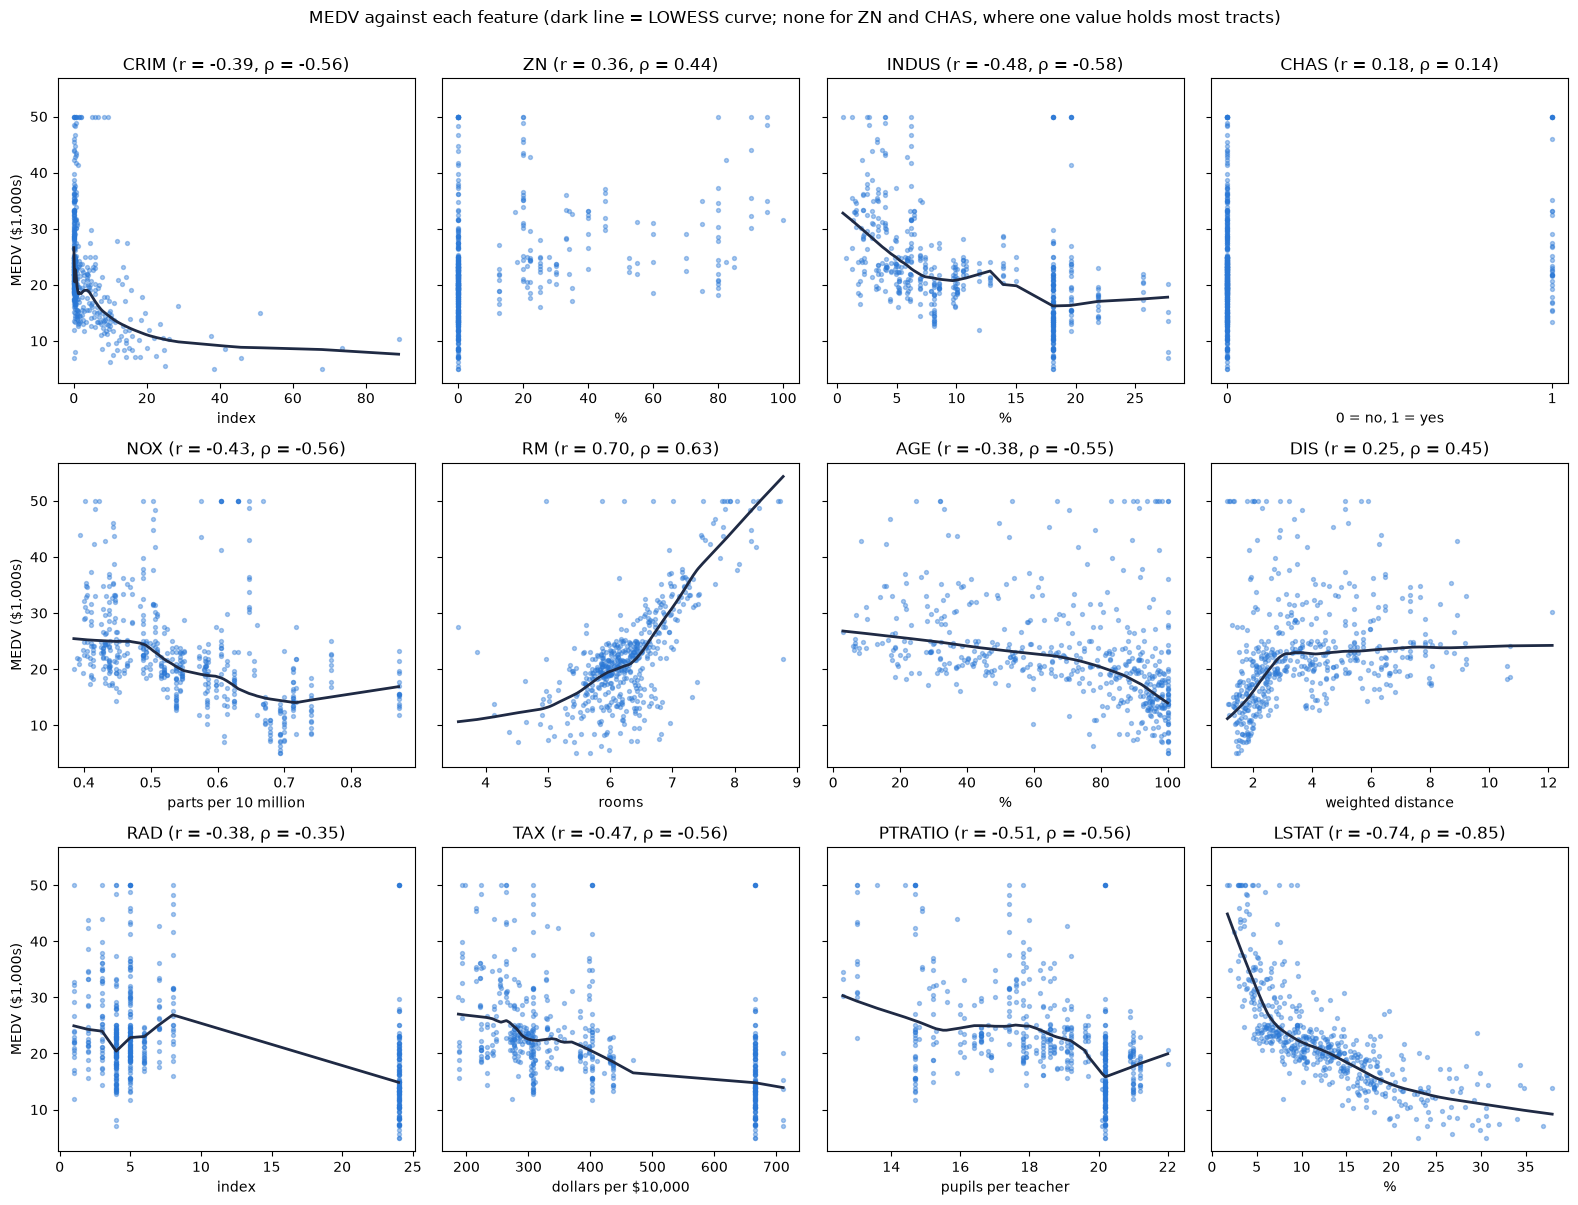

In [68]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharey=True)
for ax, col in zip(axes.flat, FEATURES[:-1]):
    x = df[col]
    ax.scatter(x, df["MEDV"], s=8, alpha=0.4, color=POINT_COLOUR)
    if can_smooth(x):   # left out for ZN and CHAS, where one value holds most tracts
        smooth = lowess(df["MEDV"], x, frac=LOWESS_FRAC)
        ax.plot(smooth[:, 0], smooth[:, 1], color=LOWESS_COLOUR, linewidth=2)
    ax.set_title(f"{col} (r = {x.corr(df['MEDV']):.2f}, ρ = {x.corr(df['MEDV'], method='spearman'):.2f})")
    ax.set_xlabel(UNITS[col])
    if col == "CHAS":   # binary, so only 0 and 1 are meaningful ticks
        ax.set_xticks([0, 1])
for ax in axes[:, 0]:
    ax.set_ylabel("MEDV ($1,000s)")
fig.suptitle("MEDV against each feature (dark line = LOWESS curve; none for ZN and CHAS, where one value holds most tracts)", y=1.0)
plt.tight_layout()
plt.show()

#### **Observation I:**
What the panels show, before testing:
- **Curves:** `LSTAT` falls steeply at low values and then flattens. `RM` is shallow up to about 6.5 rooms and steep above. `DIS` rises up to about 3 and is then flat. `CRIM` is squeezed against zero.
- **Groups rather than slopes:** `INDUS`, `RAD`, `TAX` and `PTRATIO` form vertical stripes, because many tracts share one town-level value. `ZN` and `CHAS` are effectively comparisons of two groups.
- **The cap:** every panel has a row of points at `MEDV` = 50.

Each of these is tested in the pair sections below.

### Bivariate - `CRIM` vs `MEDV`
Observation C suggested that `MEDV` falls as crime rises. This checks the direction, the shape of the fall, and whether the low- and high-crime groups from the univariate analysis differ in value.

In [69]:
pair_stats(df["CRIM"], df["MEDV"])

MEDV against CRIM, 506 tracts
Pearson r:     -0.388  (p = 1.2e-19)
Spearman rho:  -0.559  (p = 6.6e-43)   |rho| - |r| = +0.171
R-squared, straight line: 0.151   with a squared term: 0.210   (gain +0.059)
Breusch-Pagan p = 1.5e-01  (below 0.05: the spread around the straight line changes with CRIM)
Pearson r without the 16 capped tracts (MEDV = 50): -0.450


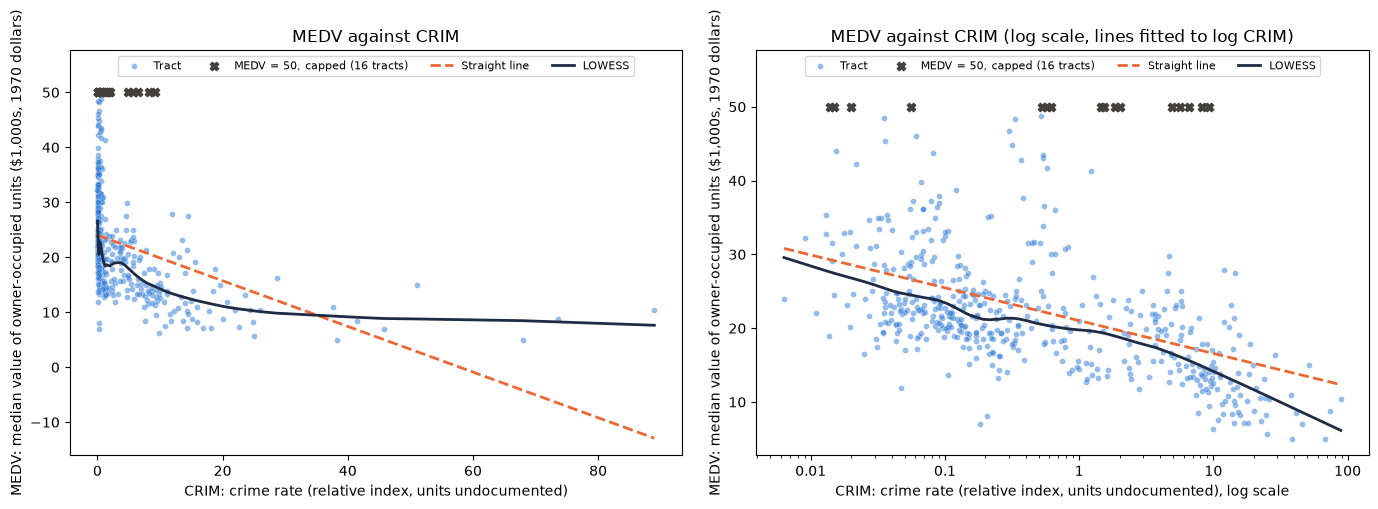

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["CRIM"], df["MEDV"])
axes[0].set_title("MEDV against CRIM")
scatter_fit(axes[1], df["CRIM"], df["MEDV"], logx=True)
axes[1].set_title("MEDV against CRIM (log scale, lines fitted to log CRIM)")
plt.tight_layout()
plt.show()

In [71]:
log_check(df["CRIM"], df["MEDV"])

Pearson r, CRIM and MEDV              -0.388
Pearson r, log(CRIM) and MEDV         -0.454
Pearson r, CRIM and log(MEDV)         -0.528
Pearson r, log(CRIM) and log(MEDV)    -0.567


                   tracts  median    mean    iqr   min   max
CRIM                                                        
0.00632 to 0.0642     102   24.55  27.205  9.575  11.9  50.0
0.0647 to 0.15        101   22.80  24.862  7.900  13.6  43.8
0.151 to 0.55         101   21.70  23.564  6.200   7.0  50.0
0.558 to 5.58         101   19.60  22.002  7.600  11.8  50.0
5.67 to 89            101   13.30  14.984  6.700   5.0  50.0

Median MEDV: low-crime 22.95, high-crime 15.20   Mann-Whitney U p = 1.7e-29
Capped tracts (MEDV = 50) in the high-crime group: 9 of 16. Other high-crime tracts above MEDV 30: 1 of 165


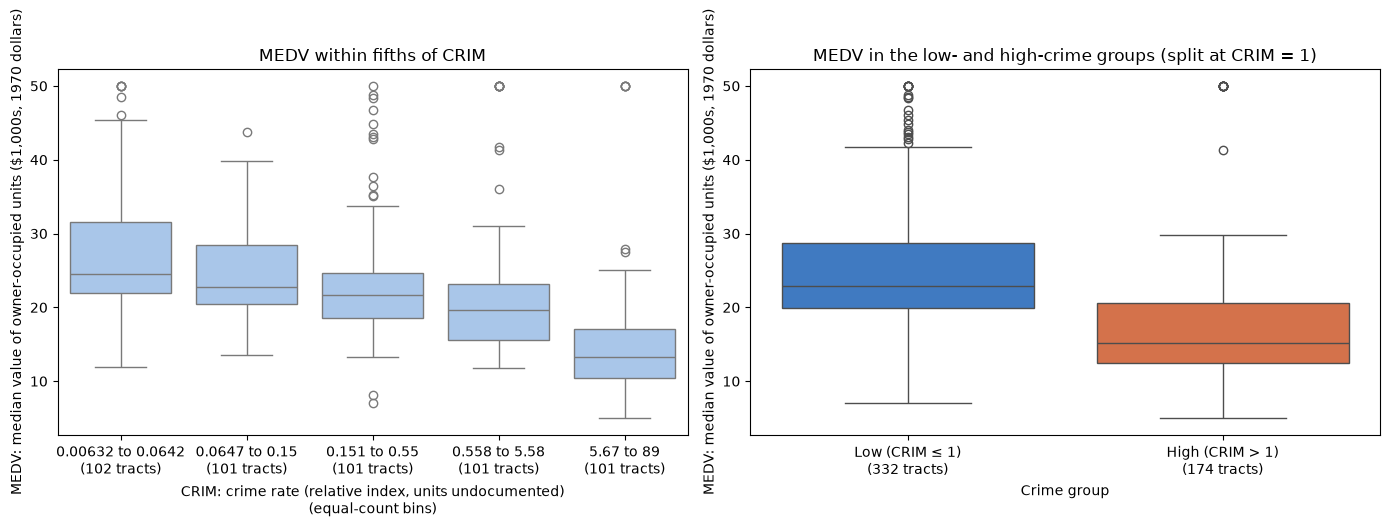

In [72]:
crim_bins = equal_bins(df["CRIM"])
print(binned_summary(crim_bins, df["MEDV"]))

crim_groups = two_groups(df["CRIM_group"] == "high", ["Low (CRIM ≤ 1)", "High (CRIM > 1)"])
low, high = df.loc[df["CRIM_group"] == "low", "MEDV"], df.loc[df["CRIM_group"] == "high", "MEDV"]
print(f"\nMedian MEDV: low-crime {low.median():.2f}, high-crime {high.median():.2f}   "
      f"Mann-Whitney U p = {stats.mannwhitneyu(low, high).pvalue:.1e}")
print(f"Capped tracts (MEDV = 50) in the high-crime group: {(high == 50).sum()} of {CAPPED.sum()}. "
      f"Other high-crime tracts above MEDV 30: {((high > 30) & (high < 50)).sum()} of {(high < 50).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
box_by_group(axes[0], crim_bins, df["MEDV"])
axes[0].set_title("MEDV within fifths of CRIM")
axes[0].set_xlabel(LABELS["CRIM"] + "\n(equal-count bins)")
box_by_group(axes[1], crim_groups, df["MEDV"], colours=GROUP_COLOURS)
axes[1].set_title("MEDV in the low- and high-crime groups (split at CRIM = 1)")
axes[1].set_xlabel("Crime group")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `CRIM` vs `MEDV`

- **Direction:** negative, which confirms Observation C. Every measure agrees: r = -0.388, ρ = -0.559, and median `MEDV` falls in each fifth of `CRIM` (24.55, 22.80, 21.70, 19.60, 13.30).

- **Shape:** not a straight line on the raw scale.
    - |ρ| is 0.171 larger than |r|, and adding a squared term lifts R² from 0.151 to 0.210.
    - Most tracts are squeezed against `CRIM` = 0, and the straight line predicts a negative `MEDV` (about -13) at the highest `CRIM`.
    - On a log scale, the LOWESS curve runs close to the straight line. r strengthens to -0.454 with log(`CRIM`) and to -0.567 with the log of both.

- **Where the fall happens:** gradually across the first four fifths (median down 4.95, from 24.55 to 19.60, while `CRIM` rises from 0.006 to 5.58). Then it drops by a further 6.30 in the top fifth (`CRIM` 5.67 to 89).

- **Groups:** low-crime tracts (`CRIM` ≤ 1) have a median `MEDV` of 22.95, against 15.20 for high-crime tracts (Mann-Whitney p = 1.7e-29).

- **Spread:** no evidence that the spread around the line changes with `CRIM` (Breusch-Pagan p = 0.15).

- **Censoring:** 9 of the 16 capped tracts are in the high-crime group, where only 1 of the other 165 tracts is above 30. They sit far from their neighbours. Removing all 16 strengthens r from -0.388 to -0.450.

- **Implication:** log(`CRIM`) suits a linear model better than `CRIM`.

### Bivariate - `ZN` vs `MEDV`
74% of tracts have `ZN` = 0 (univariate). This checks whether `MEDV` follows the amount of large-lot zoning or only whether a town has any, and looks again at the spike at `ZN` = 80 (Observation G).

In [73]:
pair_stats(df["ZN"], df["MEDV"])

MEDV against ZN, 506 tracts
Pearson r:     +0.360  (p = 5.7e-17)
Spearman rho:  +0.438  (p = 3.7e-25)   |rho| - |r| = +0.078
R-squared, straight line: 0.130   with a squared term: 0.139   (gain +0.009)
Breusch-Pagan p = 8.3e-01  (below 0.05: the spread around the straight line changes with ZN)
Pearson r without the 16 capped tracts (MEDV = 50): +0.405


        tracts  median    mean     iqr   min   max
ZN = 0     372   19.75  20.473   8.200   5.0  50.0
ZN > 0     134   25.00  28.250  10.875  15.0  50.0

Mann-Whitney U p = 3.1e-22


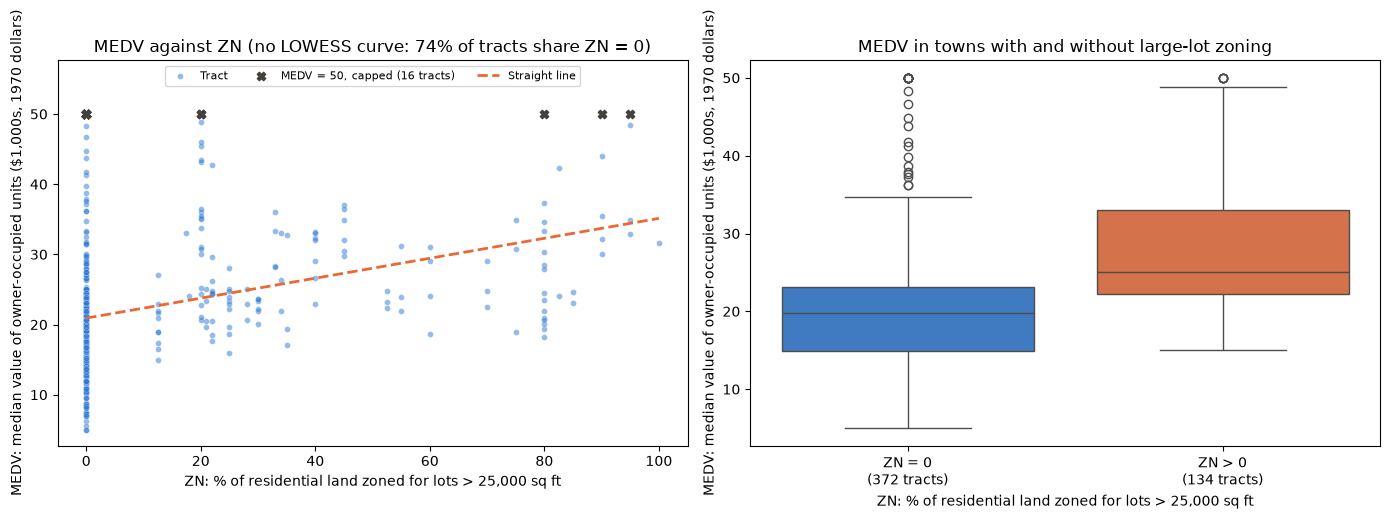

In [74]:
zn_any = two_groups(df["ZN"] > 0, ["ZN = 0", "ZN > 0"])
print(binned_summary(zn_any, df["MEDV"]))
zero, nonzero = df.loc[df["ZN"] == 0, "MEDV"], df.loc[df["ZN"] > 0, "MEDV"]
print(f"\nMann-Whitney U p = {stats.mannwhitneyu(zero, nonzero).pvalue:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["ZN"], df["MEDV"])
axes[0].set_title("MEDV against ZN (no LOWESS curve: 74% of tracts share ZN = 0)")
box_by_group(axes[1], zn_any, df["MEDV"], colours=GROUP_COLOURS)
axes[1].set_title("MEDV in towns with and without large-lot zoning")
axes[1].set_xlabel(LABELS["ZN"])
plt.tight_layout()
plt.show()

In [75]:
# ZN > 0 only: does MEDV keep rising with the amount of large-lot zoning?
nz = df[df["ZN"] > 0]
print(f"ZN > 0 only ({len(nz)} tracts): Pearson r = {nz['ZN'].corr(nz['MEDV']):+.3f}, "
      f"Spearman rho = {nz['ZN'].corr(nz['MEDV'], method='spearman'):+.3f}")

# ZN values held by at least 5 tracts, including the spike at 80 from Observation G
by_value = nz.groupby("ZN")["MEDV"].agg(tracts="size", median="median", min="min", max="max")
print(by_value[by_value["tracts"] >= 5].round(2))

ZN > 0 only (134 tracts): Pearson r = +0.208, Spearman rho = +0.178
      tracts  median   min   max
ZN                              
12.5      10   19.90  15.0  27.1
20.0      21   35.20  20.7  50.0
22.0      10   24.45  17.6  42.8
25.0      10   23.10  16.0  28.0
30.0       6   22.75  20.1  23.7
40.0       7   32.00  22.9  33.2
45.0       6   33.45  29.8  37.0
80.0      15   24.50  18.2  50.0
90.0       5   35.40  30.1  50.0


#### Observations from bivariate analysis of `ZN` vs `MEDV`

- **Direction:** positive (r = 0.360, ρ = 0.438).

- **Shape: a step, not a slope.**
    - Towns with any large-lot zoning have a median `MEDV` of 25.00, against 19.75 for `ZN` = 0 (Mann-Whitney p = 3.1e-22).
    - Among the 134 tracts with `ZN` > 0, the amount of zoning barely matters (r = 0.208, ρ = 0.178). Medians by value go up and down: 19.90 at 12.5, 35.20 at 20, 23.10 at 25, 32.00 at 40, 24.50 at 80 and 35.40 at 90.
    - A squared term adds only 0.009 to R², because the change happens at a single point (zero to non-zero) rather than along a bend.

- **Floor:** no tract with `ZN` > 0 has `MEDV` below 15.0, while tracts with `ZN` = 0 go down to 5.0.

- **The spike at 80 (Observation G):** the 15 tracts at `ZN` = 80 have a median of 24.50, close to the `ZN` > 0 median of 25.00. The spike is unusual in count, not in value.

- **Spread:** no evidence of change (Breusch-Pagan p = 0.83).

- **Censoring:** r rises from 0.360 to 0.405 without the 16 capped tracts.

- **Implication:** a zero / non-zero indicator, as suggested in the univariate analysis, captures most of what `ZN` says about `MEDV`.

### Bivariate - `INDUS` vs `MEDV`
The univariate analysis found two clusters of `INDUS`, split at 16%. This checks whether `MEDV` falls steadily as industry rises or differs mainly between the two clusters.

In [76]:
pair_stats(df["INDUS"], df["MEDV"])

MEDV against INDUS, 506 tracts
Pearson r:     -0.484  (p = 4.9e-31)
Spearman rho:  -0.578  (p = 1.7e-46)   |rho| - |r| = +0.095
R-squared, straight line: 0.234   with a squared term: 0.269   (gain +0.035)
Breusch-Pagan p = 4.5e-01  (below 0.05: the spread around the straight line changes with INDUS)
Pearson r without the 16 capped tracts (MEDV = 50): -0.600


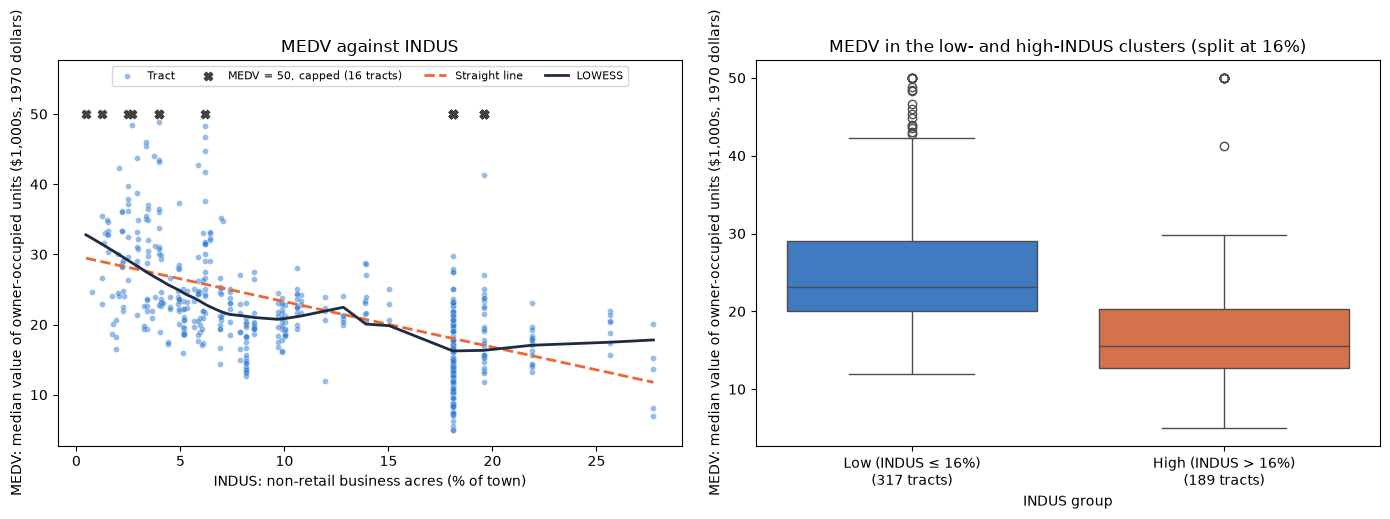

In [77]:
indus_groups = two_groups(df["INDUS_group"] == "high", ["Low (INDUS ≤ 16%)", "High (INDUS > 16%)"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["INDUS"], df["MEDV"])
axes[0].set_title("MEDV against INDUS")
box_by_group(axes[1], indus_groups, df["MEDV"], colours=GROUP_COLOURS)
axes[1].set_title("MEDV in the low- and high-INDUS clusters (split at 16%)")
axes[1].set_xlabel("INDUS group")
plt.tight_layout()
plt.show()

In [78]:
print(binned_summary(indus_groups, df["MEDV"]))
low, high = df.loc[df["INDUS_group"] == "low", "MEDV"], df.loc[df["INDUS_group"] == "high", "MEDV"]
print(f"Mann-Whitney U p = {stats.mannwhitneyu(low, high).pvalue:.1e}\n")

# Inside each cluster: does MEDV still fall as INDUS rises?
for name, part in df.groupby("INDUS_group"):
    print(f"Inside the {name}-INDUS cluster ({len(part)} tracts): r = {part['INDUS'].corr(part['MEDV']):+.3f}, "
          f"rho = {part['INDUS'].corr(part['MEDV'], method='spearman'):+.3f}")

# The vertical stripe at INDUS = 18.10 (one town-level value shared by 132 tracts)
print(f"\nMEDV of the {(df['INDUS'] == 18.10).sum()} tracts at INDUS = 18.10:")
print(df.loc[df["INDUS"] == 18.10, "MEDV"].describe().round(2))

                    tracts  median    mean  iqr   min   max
Low (INDUS ≤ 16%)      317    23.1  25.459  9.0  11.9  50.0
High (INDUS > 16%)     189    15.6  17.625  7.6   5.0  50.0
Mann-Whitney U p = 8.7e-33

Inside the high-INDUS cluster (189 tracts): r = +0.026, rho = +0.244
Inside the low-INDUS cluster (317 tracts): r = -0.440, rho = -0.474

MEDV of the 132 tracts at INDUS = 18.10:
count    132.00
mean      16.40
std        8.54
min        5.00
25%       11.23
50%       14.40
75%       19.90
max       50.00
Name: MEDV, dtype: float64


#### Observations from bivariate analysis of `INDUS` vs `MEDV`

- **Direction:** negative (r = -0.484, ρ = -0.578).

- **Shape: the fall happens inside the low-`INDUS` cluster. The high cluster is flat.**
    - Inside the low cluster (317 tracts): r = -0.440, ρ = -0.474. The LOWESS curve falls from about 33 at `INDUS` 0.5 to about 21 at `INDUS` 10.
    - Inside the high cluster (189 tracts): r = +0.026, ρ = +0.244, so no further fall.
    - Much of the overall -0.484 is therefore the gap between the clusters, with medians of 23.1 and 15.6 (Mann-Whitney p = 8.7e-33).

- **The stripe at 18.10:** the 132 tracts sharing `INDUS` = 18.10 span almost the whole range of `MEDV` (5.0 to 50.0, median 14.4, standard deviation 8.54). One town-level value sits against very different tract values.

- **Spread:** no evidence of change (Breusch-Pagan p = 0.45).

- **Censoring:** r strengthens from -0.484 to -0.600 without the capped tracts, one of the largest changes among the 12 features.

- **Implication:** `INDUS` behaves mostly as a two-level feature. A straight line overstates how smoothly `MEDV` declines with it.

### Bivariate - `CHAS` vs `MEDV`
`CHAS` is a 0/1 flag, so a scatter plot would only show two columns of points. Instead, the 35 tracts that bound the river are compared with the 471 that don't.

In [79]:
river, other = df.loc[df["CHAS"] == 1, "MEDV"], df.loc[df["CHAS"] == 0, "MEDV"]
print(binned_summary(df["OnRiver"], df["MEDV"]))
print(f"\nDifference (river minus other): medians {river.median() - other.median():+.2f}, "
      f"means {river.mean() - other.mean():+.2f}")
print(f"Mann-Whitney U p = {stats.mannwhitneyu(river, other).pvalue:.1e}   "
      f"Welch t-test p = {stats.ttest_ind(river, other, equal_var=False).pvalue:.1e}")
print(f"Point-biserial r (Pearson r with a 0/1 feature) = {df['CHAS'].corr(df['MEDV']):+.3f}")

# The cap at MEDV = 50 is not shared evenly between the two groups
print(f"\nTracts at the MEDV cap: river {(river == 50).sum()} of {len(river)} ({(river == 50).mean():.1%}), "
      f"other {(other == 50).sum()} of {len(other)} ({(other == 50).mean():.1%})")
r_keep, o_keep = river[river < 50], other[other < 50]
print(f"Without the capped tracts: medians river {r_keep.median():.2f}, other {o_keep.median():.2f}   "
      f"Mann-Whitney U p = {stats.mannwhitneyu(r_keep, o_keep).pvalue:.1e}   "
      f"r = {df.loc[~CAPPED, 'CHAS'].corr(df.loc[~CAPPED, 'MEDV']):+.3f}")

              tracts  median    mean    iqr   min   max
OnRiver                                                
Not on River     471    20.9  22.094   8.20   5.0  50.0
On River          35    23.3  28.440  12.05  13.4  50.0

Difference (river minus other): medians +2.40, means +6.35
Mann-Whitney U p = 1.6e-03   Welch t-test p = 3.6e-03
Point-biserial r (Pearson r with a 0/1 feature) = +0.175

Tracts at the MEDV cap: river 6 of 35 (17.1%), other 10 of 471 (2.1%)
Without the capped tracts: medians river 22.40, other 20.60   Mann-Whitney U p = 5.9e-02   r = +0.075


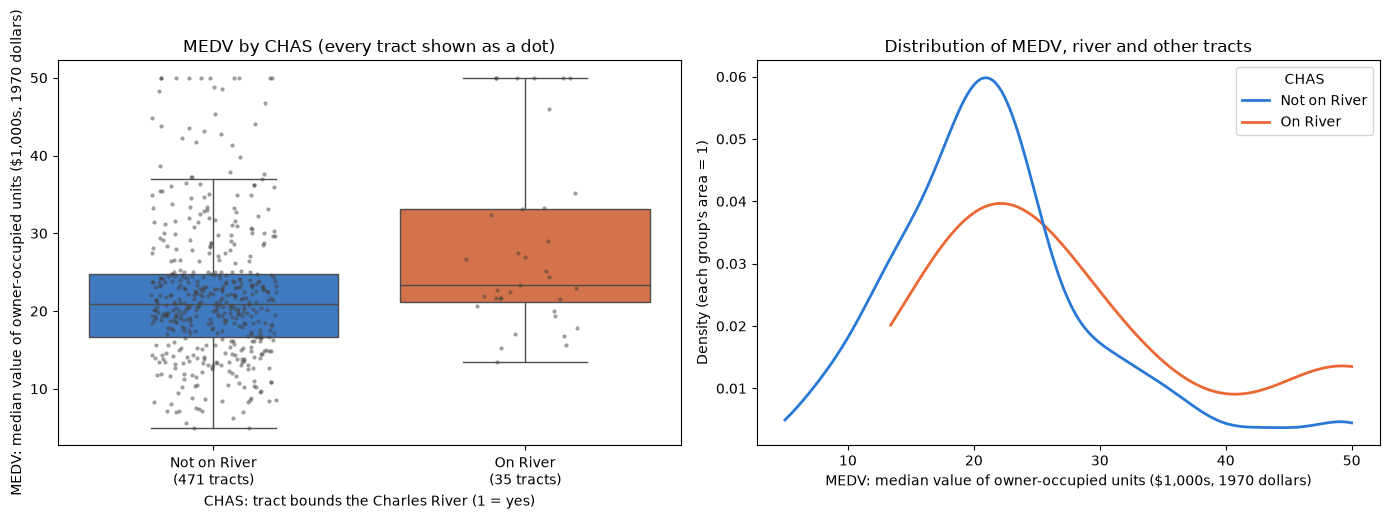

In [80]:
order = ["Not on River", "On River"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
box_by_group(axes[0], df["OnRiver"], df["MEDV"], order=order, colours=GROUP_COLOURS, points=True)
axes[0].set_title("MEDV by CHAS (every tract shown as a dot)")
axes[0].set_xlabel(LABELS["CHAS"])

# Density rather than counts, so the 35 river tracts and the 471 others are on the same footing
sns.kdeplot(data=df, x="MEDV", hue="OnRiver", hue_order=order, palette=GROUP_COLOURS, common_norm=False,
            cut=0, linewidth=2, ax=axes[1])
axes[1].set_title("Distribution of MEDV, river and other tracts")
axes[1].set_xlabel(LABELS["MEDV"])
axes[1].set_ylabel("Density (each group's area = 1)")
axes[1].get_legend().set_title("CHAS")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `CHAS` vs `MEDV`

- **Direction:** river tracts are worth more. Median 23.3 against 20.9 (+2.40), mean 28.44 against 22.09 (+6.35). Mann-Whitney p = 0.0016, Welch t-test p = 0.0036. The point-biserial r of 0.175 is the weakest of the 12 features.

- **The mean gap is more than 2.5 times the median gap.** The density plot shows why: the river group has a second hump near 50.

- **Censoring drives much of the difference:**
    - 6 of the 35 river tracts (17.1%) sit at the cap, against 10 of the 471 others (2.1%).
    - Without the capped tracts, the median gap shrinks to 1.80 (22.40 against 20.60). The Mann-Whitney p rises to 0.059, which is no longer significant at 5%, and r falls to 0.075.

- **Implication:** the river premium is small and fragile. It rests on 35 tracts, 6 of them capped, so its size depends on how the cap is handled.

### Bivariate - `NOX` vs `MEDV`
`NOX` is the pollution measure the original study was built around. This checks whether `MEDV` falls steadily as `NOX` rises or in steps.

In [81]:
pair_stats(df["NOX"], df["MEDV"])

MEDV against NOX, 506 tracts
Pearson r:     -0.427  (p = 7.1e-24)
Spearman rho:  -0.563  (p = 1.4e-43)   |rho| - |r| = +0.135
R-squared, straight line: 0.183   with a squared term: 0.187   (gain +0.005)
Breusch-Pagan p = 3.7e-01  (below 0.05: the spread around the straight line changes with NOX)
Pearson r without the 16 capped tracts (MEDV = 50): -0.524


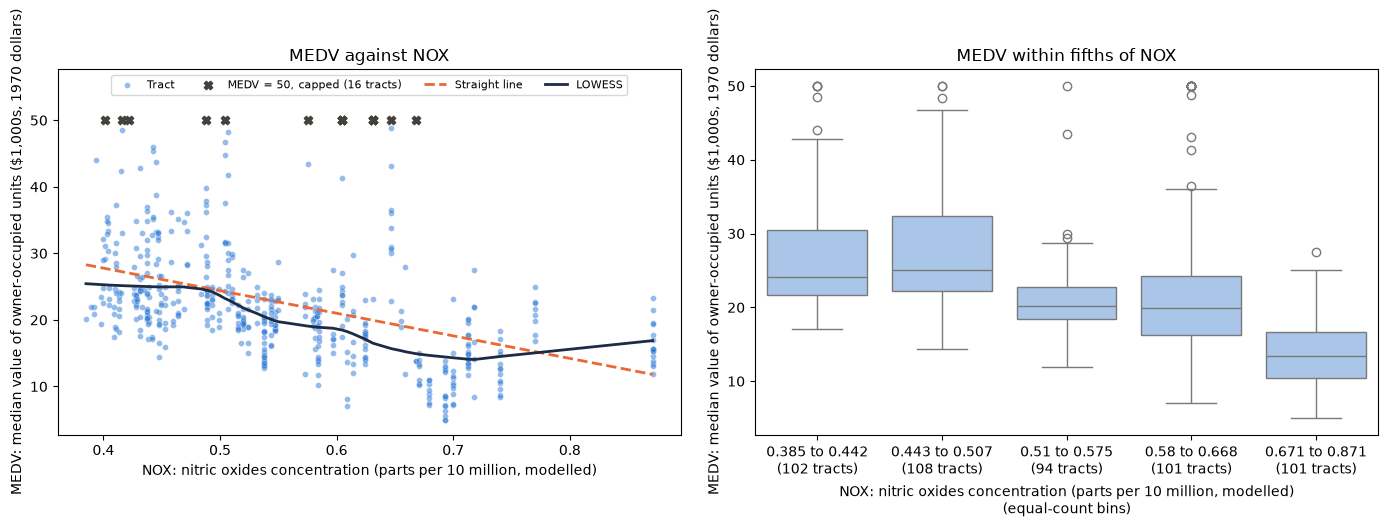

In [82]:
nox_bins = equal_bins(df["NOX"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["NOX"], df["MEDV"])
axes[0].set_title("MEDV against NOX")
box_by_group(axes[1], nox_bins, df["MEDV"])
axes[1].set_title("MEDV within fifths of NOX")
axes[1].set_xlabel(LABELS["NOX"] + "\n(equal-count bins)")
plt.tight_layout()
plt.show()

In [83]:
print(binned_summary(nox_bins, df["MEDV"]))

top = df[df["NOX"] > 0.668]   # the top fifth of NOX in the table above
print(f"\nNOX above 0.668 ({len(top)} tracts): MEDV {top['MEDV'].min()} to {top['MEDV'].max()}; "
      f"tracts with MEDV above 30: {(top['MEDV'] > 30).sum()}")
print(f"NOX at or below 0.668 ({(df['NOX'] <= 0.668).sum()} tracts): "
      f"tracts with MEDV above 30: {((df['NOX'] <= 0.668) & (df['MEDV'] > 30)).sum()}")
iso = df.loc[df["NOX"] == 0.871, "MEDV"]
print(f"NOX = 0.871, the isolated top group ({len(iso)} tracts): MEDV {iso.min()} to {iso.max()}, median {iso.median()}")
print()
log_check(df["NOX"], df["MEDV"])

                tracts  median    mean     iqr   min   max
NOX                                                       
0.385 to 0.442     102   24.15  26.643   8.750  17.1  50.0
0.443 to 0.507     108   25.00  27.749  10.225  14.4  50.0
0.51 to 0.575       94   20.15  20.673   4.375  11.9  50.0
0.58 to 0.668      101   19.90  23.228   8.000   7.0  50.0
0.671 to 0.871     101   13.40  13.840   6.300   5.0  27.5

NOX above 0.668 (101 tracts): MEDV 5.0 to 27.5; tracts with MEDV above 30: 0
NOX at or below 0.668 (405 tracts): tracts with MEDV above 30: 84
NOX = 0.871, the isolated top group (16 tracts): MEDV 11.8 to 23.3, median 15.6

Pearson r, NOX and MEDV               -0.427
Pearson r, log(NOX) and MEDV          -0.431
Pearson r, NOX and log(MEDV)          -0.511
Pearson r, log(NOX) and log(MEDV)     -0.515


#### Observations from bivariate analysis of `NOX` vs `MEDV`

- **Direction:** negative (r = -0.427, ρ = -0.563).

- **Shape: steps rather than a smooth line.** Median `MEDV` by fifth of `NOX` is 24.15, 25.00, 20.15, 19.90 and 13.40.
    - Flat across the lowest two fifths (`NOX` up to 0.507).
    - A step down to about 20 between 0.51 and 0.668.
    - A second, larger step down to 13.40 above 0.668.
    - A squared term adds only 0.005 to R², because these are steps, not a bend.

- **Ceiling:** none of the 101 tracts with `NOX` above 0.668 has `MEDV` above 27.5, against 84 of the 405 tracts below it with `MEDV` above 30. High pollution puts a ceiling on value.

- **The isolated top group:** the 16 tracts at `NOX` = 0.871 range from 11.8 to 23.3, with a median of 15.6. That is above the top fifth's median of 13.40, which is why the LOWESS curve turns up at the right edge.

- **Transformation:** log(`NOX`) barely changes r (-0.431), while log(`MEDV`) strengthens it to -0.511.

- **Censoring:** r strengthens from -0.427 to -0.524 without the capped tracts.

### Bivariate - `RM` vs `MEDV`
`RM` is the most bell-shaped feature (univariate). This checks how strongly value rises with rooms, whether each extra room adds the same amount, and which tracts sit far from the trend.

In [84]:
pair_stats(df["RM"], df["MEDV"])

MEDV against RM, 506 tracts
Pearson r:     +0.695  (p = 2.5e-74)
Spearman rho:  +0.634  (p = 3.8e-58)   |rho| - |r| = -0.062
R-squared, straight line: 0.484   with a squared term: 0.548   (gain +0.065)
Breusch-Pagan p = 9.3e-01  (below 0.05: the spread around the straight line changes with RM)
Pearson r without the 16 capped tracts (MEDV = 50): +0.687


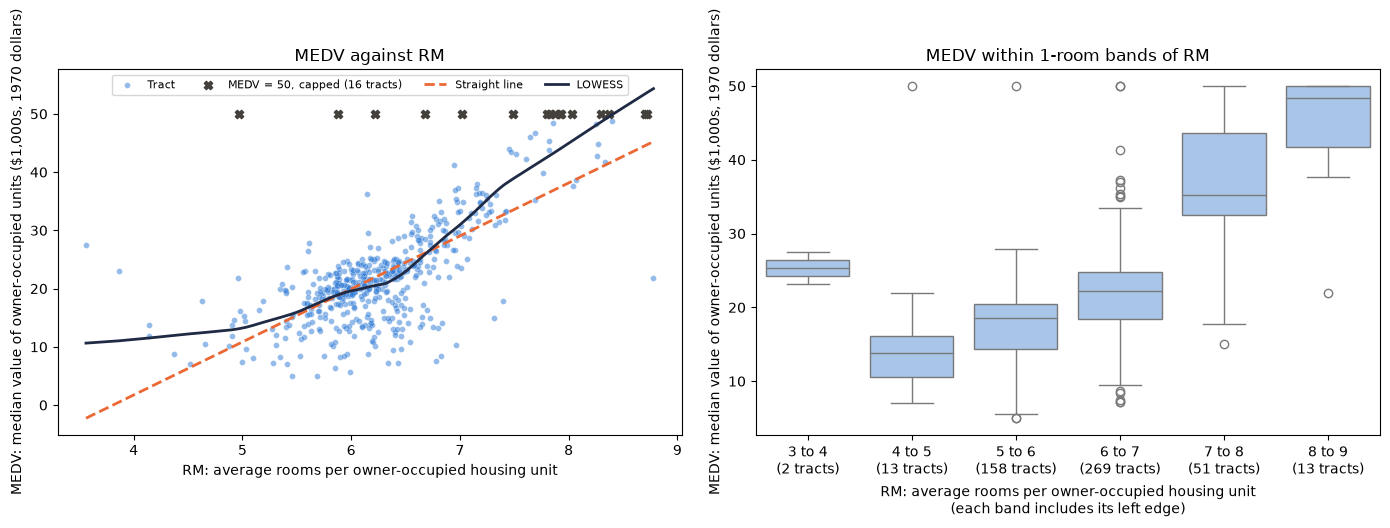

In [85]:
# 1-room bands, the same bands as the univariate histogram of RM (each band includes its left edge)
rm_bands = pd.cut(df["RM"], bins=np.arange(3, 10), right=False)
rm_bands = rm_bands.cat.rename_categories([f"{b.left} to {b.right}" for b in rm_bands.cat.categories])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["RM"], df["MEDV"])
axes[0].set_title("MEDV against RM")
box_by_group(axes[1], rm_bands, df["MEDV"])
axes[1].set_title("MEDV within 1-room bands of RM")
axes[1].set_xlabel(LABELS["RM"] + "\n(each band includes its left edge)")
plt.tight_layout()
plt.show()

In [86]:
print(binned_summary(rm_bands, df["MEDV"]))

# Value added per extra room, fitted separately either side of 6.5 rooms (where the LOWESS curve bends)
print()
for name, part in [("RM < 6.5", df[df["RM"] < 6.5]), ("RM >= 6.5", df[df["RM"] >= 6.5])]:
    slope = np.polyfit(part["RM"], part["MEDV"], 1)[0]
    print(f"{name}: {len(part)} tracts, MEDV rises by {slope:.2f} ($1,000s) per extra room, "
          f"r = {part['RM'].corr(part['MEDV']):+.3f}")

        tracts  median    mean   iqr   min   max
RM                                              
3 to 4       2   25.30  25.300   2.2  23.1  27.5
4 to 5      13   13.80  16.023   5.6   7.0  50.0
5 to 6     158   18.55  17.487   6.0   5.0  50.0
6 to 7     269   22.20  22.016   6.4   7.2  50.0
7 to 8      51   35.20  36.918  11.2  15.0  50.0
8 to 9      13   48.30  44.200   8.3  21.9  50.0

RM < 6.5: 354 tracts, MEDV rises by 3.25 ($1,000s) per extra room, r = +0.250
RM >= 6.5: 152 tracts, MEDV rises by 13.33 ($1,000s) per extra room, r = +0.700


In [87]:
# Tracts far from the trend: the residual is how far MEDV sits above (+) or below (-) the straight line
fit = sm.OLS(df["MEDV"], sm.add_constant(df["RM"])).fit()
cutoff = 2.5 * fit.resid.std()
far = df[["RM", "MEDV"]].assign(residual=fit.resid)[fit.resid.abs() > cutoff]
print(f"Tracts more than {cutoff:.1f} ($1,000s) from the straight line (2.5 standard deviations): {len(far)}")
print(far.sort_values("residual").round(2).to_string())

capped_rm = df.loc[CAPPED, "RM"]
print(f"\nCapped tracts (MEDV = 50): RM from {capped_rm.min():.2f} to {capped_rm.max():.2f}, median {capped_rm.median():.2f}")
print(f"Capped tracts with fewer than 6.5 rooms: {(capped_rm < 6.5).sum()}")

Tracts more than 16.5 ($1,000s) from the straight line (2.5 standard deviations): 13
       RM  MEDV  residual
364  8.78  21.9    -23.35
416  6.78   7.5    -19.56
419  6.82   8.4    -19.04
380  6.97  10.4    -18.35
375  7.31  15.0    -16.89
415  6.43   7.2    -16.69
370  7.02  50.0     20.81
367  3.86  23.1     22.61
369  6.68  50.0     23.84
371  6.22  50.0     28.09
365  3.56  27.5     29.76
372  5.88  50.0     31.20
368  4.97  50.0     39.43

Capped tracts (MEDV = 50): RM from 4.97 to 8.72, median 7.85
Capped tracts with fewer than 6.5 rooms: 3


#### Observations from bivariate analysis of `RM` vs `MEDV`

- **Direction and strength:** strongly positive (r = 0.695), second only to `LSTAT`. Unusually, ρ is lower (0.634), which means a few extreme tracts add to r.

- **Shape: convex, so each extra room adds more at the top end.**
    - Below 6.5 rooms (354 tracts), `MEDV` rises by 3.25 ($1,000s) per room (r = 0.250). At 6.5 rooms and above (152 tracts), it rises by 13.33 per room (r = 0.700), about four times as steep.
    - Adding a squared term lifts R² from 0.484 to 0.548.
    - Band medians: 13.80 (4–5 rooms), 18.55 (5–6), 22.20 (6–7), 35.20 (7–8) and 48.30 (8–9).

- **Spread:** Breusch-Pagan finds no steady change (p = 0.93), but the 7–8 band is much wider (IQR 11.2, against 5.6 to 6.4 for 4 to 7 rooms).

- **Tracts far from the line:** 13 tracts sit more than 16.5 ($1,000s, 2.5 standard deviations) from the straight line.
    - Above it: 5 capped tracts with 4.97 to 7.02 rooms, and the two smallest dwellings (3.56 rooms at 27.5, and 3.86 rooms at 23.1).
    - Below it: 6 tracts with 6.43 to 8.78 rooms worth only 7.2 to 21.9. The furthest is the tract with the largest dwellings in the data (8.78 rooms, `MEDV` 21.9).
    - All 13 fall between rows 364 and 419 of the file, 8 of them in the run 364 to 372. Whether they share a town is worth checking in the multivariate analysis.

- **Censoring:** 13 of the 16 capped tracts have 6.5 rooms or more (median 7.85). The cap cuts off the steep upper part, so the true slope at the top is probably steeper still.

- **Implication:** a squared term, or a separate slope above about 6.5 rooms, fits better than a straight line.

### Bivariate - `AGE` vs `MEDV`
Half the tracts have `AGE` above 75% (univariate). This checks whether older housing goes with lower value, and where along `AGE` the fall happens.

In [88]:
pair_stats(df["AGE"], df["MEDV"])

MEDV against AGE, 506 tracts
Pearson r:     -0.377  (p = 1.6e-18)
Spearman rho:  -0.548  (p = 6.3e-41)   |rho| - |r| = +0.171
R-squared, straight line: 0.142   with a squared term: 0.155   (gain +0.013)
Breusch-Pagan p = 2.9e-02  (below 0.05: the spread around the straight line changes with AGE)
Pearson r without the 16 capped tracts (MEDV = 50): -0.493


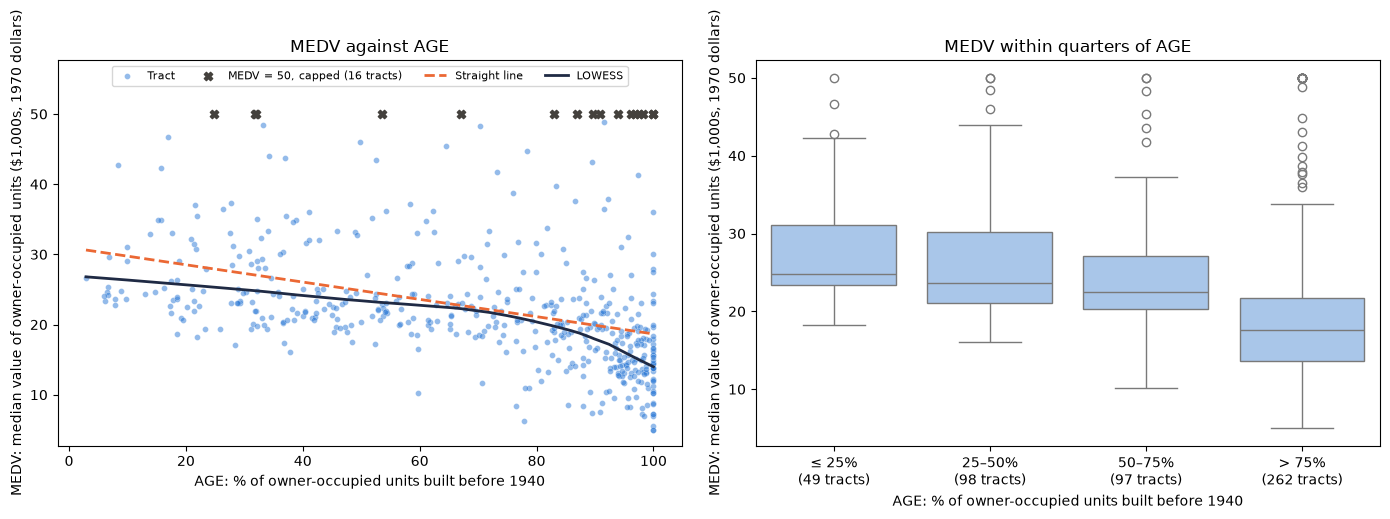

In [89]:
# The same quarters as the univariate countplot of AGE
age_quarters = pd.cut(df["AGE"], bins=[0, 25, 50, 75, 100], labels=["≤ 25%", "25–50%", "50–75%", "> 75%"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["AGE"], df["MEDV"])
axes[0].set_title("MEDV against AGE")
box_by_group(axes[1], age_quarters, df["MEDV"])
axes[1].set_title("MEDV within quarters of AGE")
axes[1].set_xlabel(LABELS["AGE"])
plt.tight_layout()
plt.show()

In [90]:
print("By quarter of the AGE range:")
print(binned_summary(age_quarters, df["MEDV"]))
print("\nBy fifths of tracts (equal-count bins):")
print(binned_summary(equal_bins(df["AGE"]), df["MEDV"]))

print(f"\nCapped tracts (MEDV = 50) with AGE above 75%: {(CAPPED & (df['AGE'] > 75)).sum()} of {CAPPED.sum()}")
age100 = df.loc[df["AGE"] == 100, "MEDV"]
print(f"\nAGE = 100 ({len(age100)} tracts): median MEDV {age100.median()}, IQR {age100.quantile(0.75) - age100.quantile(0.25):.2f}")
print()
log_check(df["AGE"], df["MEDV"])

By quarter of the AGE range:
        tracts  median    mean    iqr   min   max
AGE                                              
≤ 25%       49   24.80  27.647  7.700  18.2  50.0
25–50%      98   23.60  26.216  9.225  16.1  50.0
50–75%      97   22.50  24.713  6.800  10.2  50.0
> 75%      262   17.65  19.391  8.100   5.0  50.0

By fifths of tracts (equal-count bins):
              tracts  median    mean    iqr   min   max
AGE                                                    
2.9 to 37.8      102    24.8  27.555  8.375  16.1  50.0
38.1 to 65.4     101    22.5  24.877  5.900  10.2  50.0
66.1 to 85.9     101    21.2  22.635  6.100   6.3  50.0
86.1 to 95.6     101    18.3  19.907  7.800   7.4  50.0
95.7 to 100      101    15.1  17.641  6.900   5.0  50.0

Capped tracts (MEDV = 50) with AGE above 75%: 11 of 16

AGE = 100 (43 tracts): median MEDV 14.5, IQR 8.10

Pearson r, AGE and MEDV               -0.377
Pearson r, log(AGE) and MEDV          -0.327
Pearson r, AGE and log(MEDV)          -0

#### Observations from bivariate analysis of `AGE` vs `MEDV`

- **Direction:** negative (r = -0.377, ρ = -0.548).

- **Shape: shallow for most of the range, then a fall among the oldest tracts.**
    - Median `MEDV` by fifth of `AGE` is 24.8, 22.5, 21.2, 18.3 and 15.1. It falls 3.6 across the first three fifths (`AGE` up to 85.9) and a further 6.1 across the last two.
    - By quarter of the range, the medians are 24.80, 23.60, 22.50 and 17.65, so most of the fall sits above 75%.
    - The LOWESS curve bends at about `AGE` 80.

- **The ceiling at `AGE` = 100:** the 43 tracts there have a median of 14.5.

- **Spread:** changes with `AGE` (Breusch-Pagan p = 0.029). It is the low end that stretches: the lowest `MEDV` is 16.1 in the youngest fifth and 5.0 in the oldest.

- **Censoring:** 11 of the 16 capped tracts have `AGE` above 75%, against the trend. Removing all 16 strengthens r from -0.377 to -0.493.

- **Transformation:** log(`AGE`) weakens r (-0.327) because `AGE` is left-skewed. log(`MEDV`) strengthens it (-0.453).

### Bivariate - `DIS` vs `MEDV`
Pearson r for this pair (0.25) is the second weakest with `MEDV`, but Spearman ρ (0.45) is much larger. This checks why.

In [91]:
pair_stats(df["DIS"], df["MEDV"])

MEDV against DIS, 506 tracts
Pearson r:     +0.250  (p = 1.2e-08)
Spearman rho:  +0.446  (p = 4.4e-26)   |rho| - |r| = +0.196
R-squared, straight line: 0.062   with a squared term: 0.096   (gain +0.033)
Breusch-Pagan p = 2.3e-03  (below 0.05: the spread around the straight line changes with DIS)
Pearson r without the 16 capped tracts (MEDV = 50): +0.369


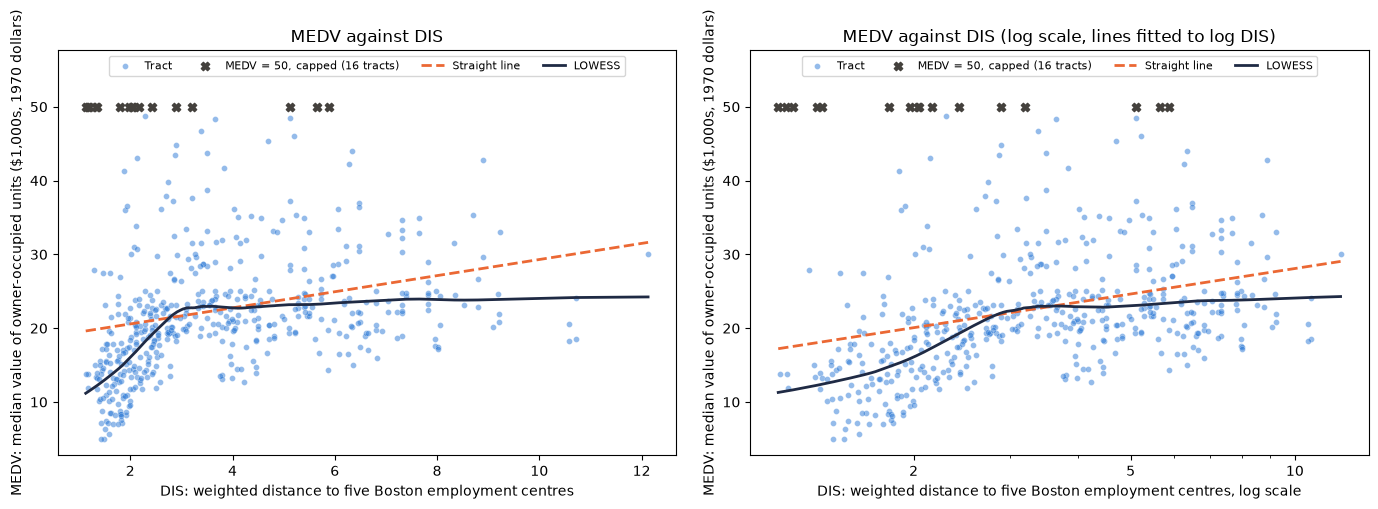

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["DIS"], df["MEDV"])
axes[0].set_title("MEDV against DIS")
scatter_fit(axes[1], df["DIS"], df["MEDV"], logx=True)
axes[1].set_title("MEDV against DIS (log scale, lines fitted to log DIS)")
plt.tight_layout()
plt.show()

              tracts  median    mean    iqr   min   max
DIS                                                    
1.13 to 1.95     103    13.8  16.684  7.350   5.0  50.0
1.97 to 2.64     100    19.1  20.910  7.325   9.5  50.0
2.65 to 3.88     101    23.1  25.642  8.600  13.1  50.0
3.88 to 5.62     101    22.6  24.384  6.600  12.7  50.0
5.65 to 12.1     101    23.5  25.144  8.900  14.4  50.0

DIS <= 2.64 (203 tracts): r = +0.116, rho = +0.343
DIS >  2.64 (303 tracts): r = -0.003, rho = +0.032
Capped tracts (MEDV = 50) at DIS <= 2.64: 11 of 16

Pearson r, DIS and MEDV               +0.250
Pearson r, log(DIS) and MEDV          +0.292
Pearson r, DIS and log(MEDV)          +0.343
Pearson r, log(DIS) and log(MEDV)     +0.406


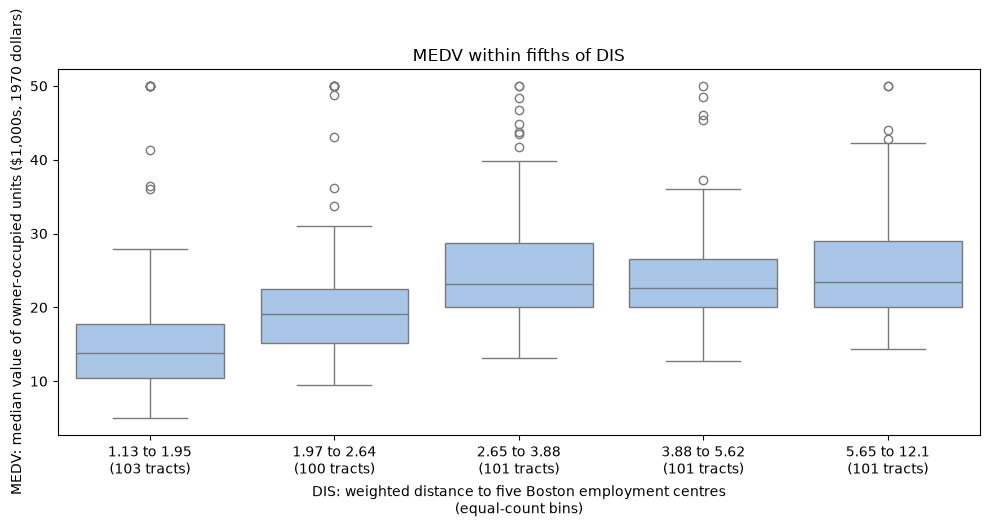

In [93]:
dis_bins = equal_bins(df["DIS"])
print(binned_summary(dis_bins, df["MEDV"]))

# Either side of the third bin's lower edge, where the median stops rising in the table above
split = df["DIS"].quantile(0.4)
near, beyond = df[df["DIS"] <= split], df[df["DIS"] > split]
print(f"\nDIS <= {split:.2f} ({len(near)} tracts): r = {near['DIS'].corr(near['MEDV']):+.3f}, "
      f"rho = {near['DIS'].corr(near['MEDV'], method='spearman'):+.3f}")
print(f"DIS >  {split:.2f} ({len(beyond)} tracts): r = {beyond['DIS'].corr(beyond['MEDV']):+.3f}, "
      f"rho = {beyond['DIS'].corr(beyond['MEDV'], method='spearman'):+.3f}")
print(f"Capped tracts (MEDV = 50) at DIS <= {split:.2f}: {(CAPPED & (df['DIS'] <= split)).sum()} of {CAPPED.sum()}")
print()
log_check(df["DIS"], df["MEDV"])

fig, ax = plt.subplots(figsize=(10, 5))
box_by_group(ax, dis_bins, df["MEDV"])
ax.set_title("MEDV within fifths of DIS")
ax.set_xlabel(LABELS["DIS"] + "\n(equal-count bins)")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `DIS` vs `MEDV`

- **Direction:** positive (r = 0.250, ρ = 0.446).

- **Shape: rises, then levels off.**
    - Median `MEDV` by fifth of `DIS` is 13.8, 19.1, 23.1, 22.6 and 23.5. It climbs by 9.3 up to the third fifth and is flat after that.
    - Beyond `DIS` 2.64 (303 tracts), there is no relationship at all (r = -0.003, ρ = 0.032).
    - The straight line misses both ends. It sits well above the LOWESS curve for the closest tracts and above it again for the most distant.
    - The weak r comes from fitting one line to a relationship that only exists close to the centres.

- **Within the closest 40%:** ρ = 0.343 but r is only 0.116. 11 of the 16 capped tracts are here, at the top of a group that is otherwise low, and they weaken r.

- **Censoring:** without the capped tracts, r rises from 0.250 to 0.369, the largest change of the 12 features.

- **Spread:** changes with `DIS` (Breusch-Pagan p = 0.0023), mostly because the closest tracts include the lowest values. The minimum is 5.0 in the closest fifth, against 12.7 to 14.4 beyond `DIS` 2.65.

- **Transformation:** the log of both gives the strongest r (0.406), but the log-scale plot still bends, so no log fully straightens it.

### Bivariate - `RAD` vs `MEDV`
`RAD` is an ordered index with values 1 to 8 and 24 (univariate), so `MEDV` is compared category by category rather than along a line.

In [94]:
print(binned_summary(df["RAD"], df["MEDV"]))
print(f"\nKruskal-Wallis across all 9 RAD values: p = {stats.kruskal(*[g for _, g in df.groupby('RAD')['MEDV']]).pvalue:.1e}")

rad_1_8 = df[df["RAD"] < 24]
print(f"Kruskal-Wallis across RAD 1-8 only:     p = {stats.kruskal(*[g for _, g in rad_1_8.groupby('RAD')['MEDV']]).pvalue:.1e}")
print(f"\nPearson r, all tracts: {df['RAD'].corr(df['MEDV']):+.3f}   "
      f"RAD 1-8 only: {rad_1_8['RAD'].corr(rad_1_8['MEDV']):+.3f} "
      f"(Spearman {rad_1_8['RAD'].corr(rad_1_8['MEDV'], method='spearman'):+.3f})")

in24, out24 = df.loc[df["RAD"] == 24, "MEDV"], rad_1_8["MEDV"]
print(f"Median MEDV: RAD 24 {in24.median():.2f}, RAD 1-8 {out24.median():.2f}   "
      f"Mann-Whitney U p = {stats.mannwhitneyu(in24, out24).pvalue:.1e}")

     tracts  median    mean     iqr   min   max
RAD                                            
1        20   22.20  24.365   6.750  11.9  50.0
2        24   23.85  26.833  11.825  15.7  43.8
3        38   26.50  27.929  13.400  14.4  50.0
4       110   20.45  21.387   6.075   7.0  50.0
5       115   23.00  25.707  10.500  11.8  50.0
6        26   21.20  20.977   4.125  16.8  24.8
7        17   26.20  27.106   5.300  17.6  42.8
8        24   28.25  30.358   9.350  16.0  50.0
24      132   14.40  16.404   8.675   5.0  50.0

Kruskal-Wallis across all 9 RAD values: p = 1.3e-29
Kruskal-Wallis across RAD 1-8 only:     p = 1.6e-08

Pearson r, all tracts: -0.382   RAD 1-8 only: +0.075 (Spearman +0.059)
Median MEDV: RAD 24 14.40, RAD 1-8 22.65   Mann-Whitney U p = 1.4e-27


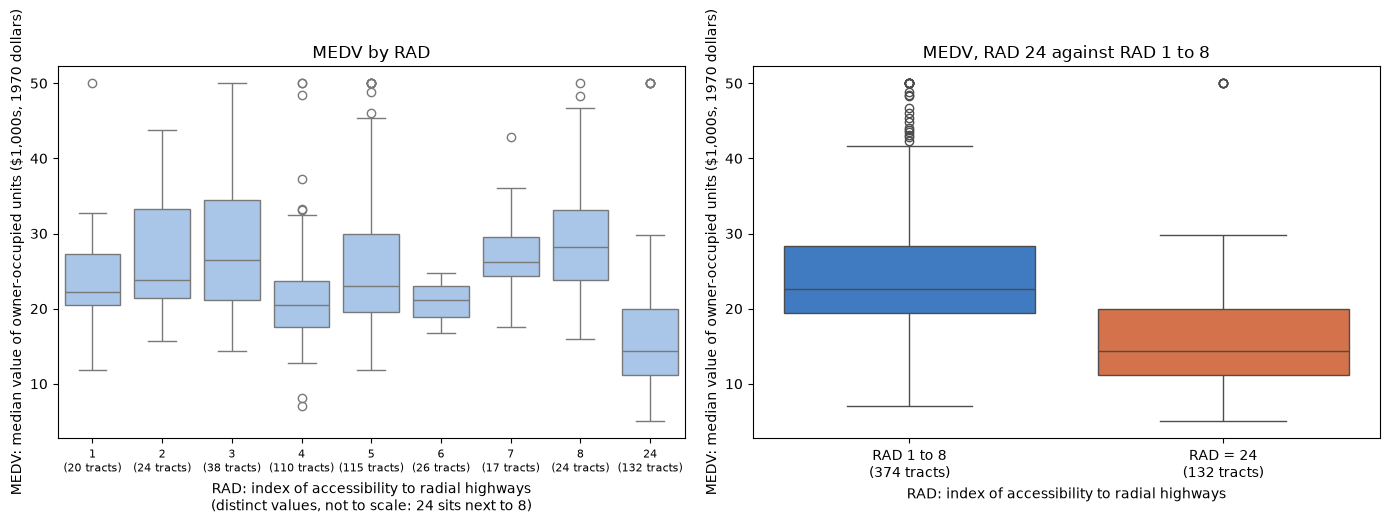

In [95]:
rad24 = two_groups(df["RAD"] == 24, ["RAD 1 to 8", "RAD = 24"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
box_by_group(axes[0], df["RAD"], df["MEDV"], order=sorted(df["RAD"].unique()))
axes[0].set_title("MEDV by RAD")
axes[0].set_xlabel(LABELS["RAD"] + "\n(distinct values, not to scale: 24 sits next to 8)")
axes[0].tick_params(axis="x", labelsize=8)
box_by_group(axes[1], rad24, df["MEDV"], colours=GROUP_COLOURS)
axes[1].set_title("MEDV, RAD 24 against RAD 1 to 8")
axes[1].set_xlabel(LABELS["RAD"])
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `RAD` vs `MEDV`

- **Shape: one group against the rest, not a trend.** Median `MEDV` for `RAD` 1 to 8 moves up and down between 20.45 (`RAD` 4) and 28.25 (`RAD` 8) without following the order of the index. `RAD` 24 sits well below, at 14.40.

- **The negative r comes entirely from `RAD` 24.** r = -0.382 over all tracts, but +0.075 over `RAD` 1 to 8 (ρ = +0.059). `RAD` 24 against `RAD` 1 to 8 gives medians of 14.40 and 22.65 (Mann-Whitney p = 1.4e-27).

- **The categories do differ:** Kruskal-Wallis p = 1.6e-08 even among `RAD` 1 to 8. The levels matter, just not in the order of the index.

- **Implication:** treat `RAD` as categorical, or as `RAD` 24 against the rest, rather than as a number. A linear term would impose a trend the categories don't follow.

### Bivariate - `TAX` vs `MEDV`
`TAX` has two separate clusters, split at 500 (univariate). This checks whether `MEDV` falls as the tax rate rises within each cluster or only differs between them.

In [96]:
pair_stats(df["TAX"], df["MEDV"])

MEDV against TAX, 506 tracts
Pearson r:     -0.469  (p = 5.6e-29)
Spearman rho:  -0.562  (p = 1.5e-43)   |rho| - |r| = +0.094
R-squared, straight line: 0.220   with a squared term: 0.225   (gain +0.005)
Breusch-Pagan p = 9.8e-01  (below 0.05: the spread around the straight line changes with TAX)
Pearson r without the 16 capped tracts (MEDV = 50): -0.572


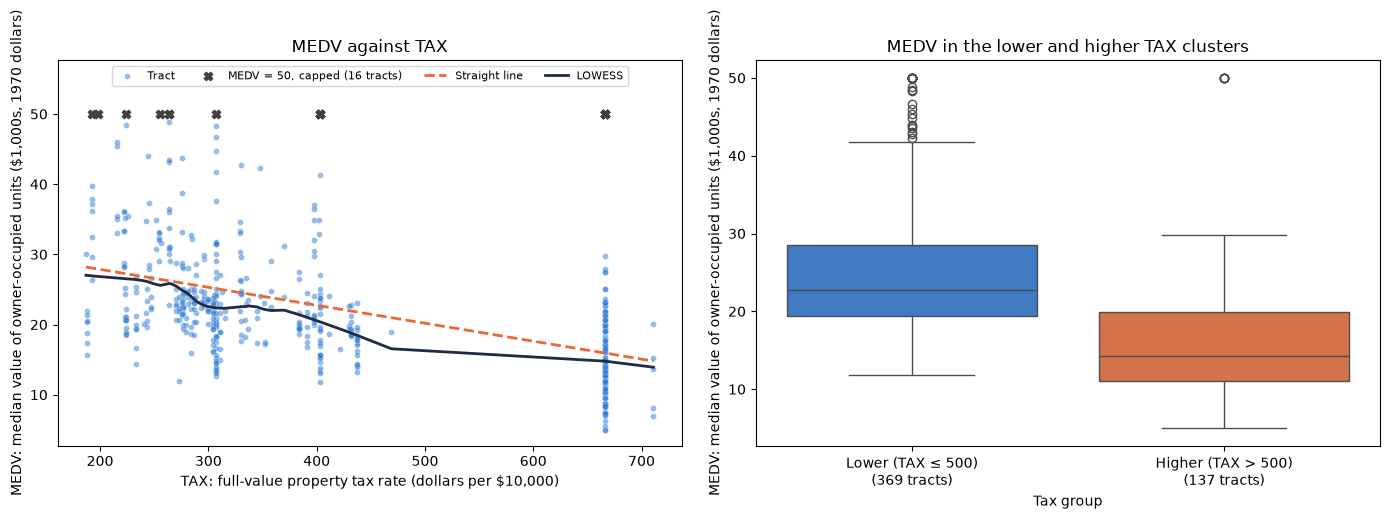

In [97]:
tax_groups = two_groups(df["TAX_group"] == "higher", ["Lower (TAX ≤ 500)", "Higher (TAX > 500)"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["TAX"], df["MEDV"])
axes[0].set_title("MEDV against TAX")
box_by_group(axes[1], tax_groups, df["MEDV"], colours=GROUP_COLOURS)
axes[1].set_title("MEDV in the lower and higher TAX clusters")
axes[1].set_xlabel("Tax group")
plt.tight_layout()
plt.show()

In [98]:
print(binned_summary(tax_groups, df["MEDV"]))
lower, higher = df.loc[df["TAX_group"] == "lower", "MEDV"], df.loc[df["TAX_group"] == "higher", "MEDV"]
print(f"Mann-Whitney U p = {stats.mannwhitneyu(lower, higher).pvalue:.1e}\n")

# Inside each cluster: does MEDV still fall as TAX rises?
for name, part in df.groupby("TAX_group"):
    print(f"Inside the {name} cluster ({len(part)} tracts, TAX {part['TAX'].min()} to {part['TAX'].max()}): "
          f"r = {part['TAX'].corr(part['MEDV']):+.3f}, rho = {part['TAX'].corr(part['MEDV'], method='spearman'):+.3f}")

                    tracts  median    mean  iqr   min   max
Lower (TAX ≤ 500)      369    22.8  24.857  9.1  11.8  50.0
Higher (TAX > 500)     137    14.3  16.272  8.9   5.0  50.0
Mann-Whitney U p = 7.8e-30

Inside the higher cluster (137 tracts, TAX 666 to 711): r = -0.080, rho = -0.082
Inside the lower cluster (369 tracts, TAX 187 to 469): r = -0.292, rho = -0.364


#### Observations from bivariate analysis of `TAX` vs `MEDV`

- **Direction:** negative (r = -0.469, ρ = -0.562).

- **Shape: mostly the gap between the clusters.** The lower cluster has a median `MEDV` of 22.8, against 14.3 in the higher cluster (Mann-Whitney p = 7.8e-30). The straight line runs through the range from about 470 to 666, where no tract has a value.

- **Within clusters:**
    - In the lower cluster (369 tracts, `TAX` 187 to 469), r = -0.292 and ρ = -0.364, a real but weaker decline.
    - In the higher cluster (137 tracts, only 666 and 711), r = -0.080, so nothing.

- **No bend:** a squared term adds only 0.005 to R². The relationship is a step plus a mild slope.

- **Spread:** no evidence of change (Breusch-Pagan p = 0.98).

- **Censoring:** r strengthens from -0.469 to -0.572 without the capped tracts.

### Bivariate - `PTRATIO` vs `MEDV`
140 tracts share `PTRATIO` = 20.2 (univariate). This checks the overall trend and whether that spike drives it.

In [99]:
pair_stats(df["PTRATIO"], df["MEDV"])

MEDV against PTRATIO, 506 tracts
Pearson r:     -0.508  (p = 1.6e-34)
Spearman rho:  -0.556  (p = 2.2e-42)   |rho| - |r| = +0.048
R-squared, straight line: 0.258   with a squared term: 0.262   (gain +0.004)
Breusch-Pagan p = 7.9e-05  (below 0.05: the spread around the straight line changes with PTRATIO)
Pearson r without the 16 capped tracts (MEDV = 50): -0.519


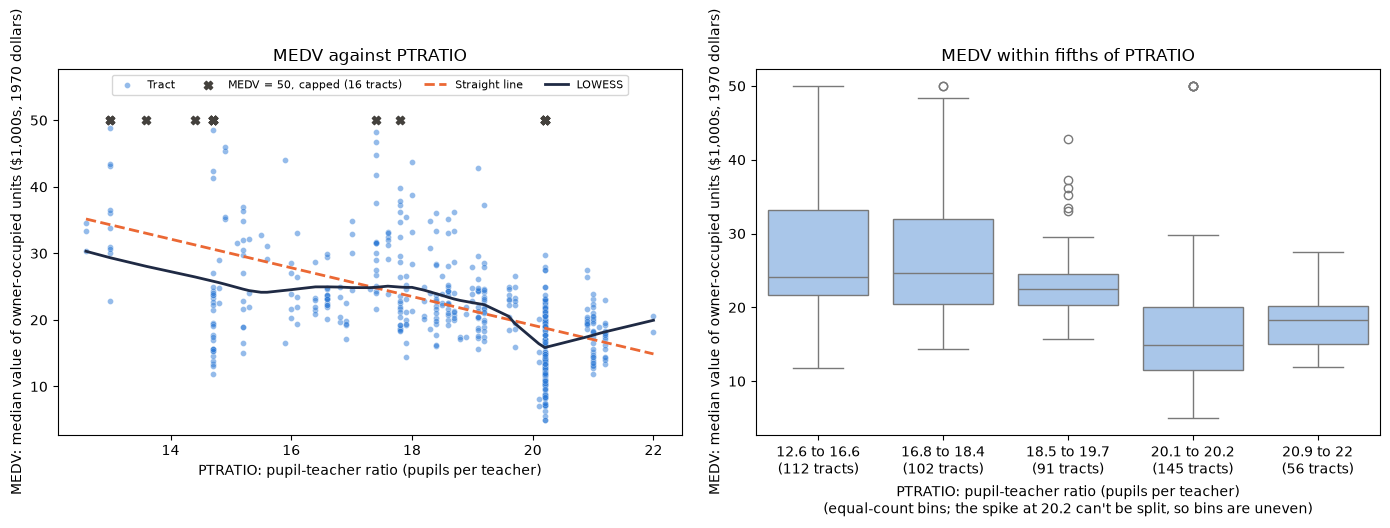

In [100]:
pt_bins = equal_bins(df["PTRATIO"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["PTRATIO"], df["MEDV"])
axes[0].set_title("MEDV against PTRATIO")
box_by_group(axes[1], pt_bins, df["MEDV"])
axes[1].set_title("MEDV within fifths of PTRATIO")
axes[1].set_xlabel(LABELS["PTRATIO"] + "\n(equal-count bins; the spike at 20.2 can't be split, so bins are uneven)")
plt.tight_layout()
plt.show()

In [101]:
print(binned_summary(pt_bins, df["MEDV"]))

spike = two_groups(df["PTRATIO"] == 20.2, ["Any other PTRATIO", "PTRATIO = 20.2"])
print()
print(binned_summary(spike, df["MEDV"]))
at, rest = df.loc[df["PTRATIO"] == 20.2, "MEDV"], df.loc[df["PTRATIO"] != 20.2, "MEDV"]
print(f"Mann-Whitney U p = {stats.mannwhitneyu(at, rest).pvalue:.1e}")

no_spike = df[df["PTRATIO"] != 20.2]
print(f"\nPearson r, all tracts: {df['PTRATIO'].corr(df['MEDV']):+.3f}   "
      f"without the 20.2 spike ({len(no_spike)} tracts): {no_spike['PTRATIO'].corr(no_spike['MEDV']):+.3f}")

              tracts  median    mean     iqr   min   max
PTRATIO                                                 
12.6 to 16.6     112   24.05  28.026  11.450  11.8  50.0
16.8 to 18.4     102   24.60  26.973  11.400  14.4  50.0
18.5 to 19.7      91   22.50  23.154   4.200  15.7  42.8
20.1 to 20.2     145   14.90  16.480   8.500   5.0  50.0
20.9 to 22        56   18.30  18.123   5.025  11.9  27.5

                   tracts  median    mean    iqr  min   max
Any other PTRATIO     366    22.8  24.798  9.175  7.0  50.0
PTRATIO = 20.2        140    14.9  16.611  8.375  5.0  50.0
Mann-Whitney U p = 1.2e-27

Pearson r, all tracts: -0.508   without the 20.2 spike (366 tracts): -0.455


#### Observations from bivariate analysis of `PTRATIO` vs `MEDV`

- **Direction:** negative (r = -0.508, ρ = -0.556), the third strongest with `MEDV`.

- **The spike at 20.2:** the 140 tracts at 20.2 have a median `MEDV` of 14.9, against 22.8 for every other ratio (Mann-Whitney p = 1.2e-27). They pull the LOWESS curve into a dip. They also break the order at the top: the highest fifth (20.9 to 22) has a median of 18.3, above the 14.9 of the bin holding 20.2.

- **Not only the spike:** without the 140 tracts at 20.2, r is still -0.455, so the decline holds across the other ratios.

- **No smooth bend:** a squared term adds only 0.004 to R².

- **Spread: narrows as `PTRATIO` rises** (Breusch-Pagan p = 7.9e-05). The IQR is 11.45 and 11.40 in the lowest two fifths, and 4.20 to 8.50 above them.

### Bivariate - `LSTAT` vs `MEDV`
The strongest pair with the target. This checks the shape of the curve, whether the spread is even along it, and which transformation straightens it.

In [102]:
pair_stats(df["LSTAT"], df["MEDV"])

MEDV against LSTAT, 506 tracts
Pearson r:     -0.738  (p = 5.1e-88)
Spearman rho:  -0.853  (p = 2.2e-144)   |rho| - |r| = +0.115
R-squared, straight line: 0.544   with a squared term: 0.641   (gain +0.097)
Breusch-Pagan p = 8.3e-05  (below 0.05: the spread around the straight line changes with LSTAT)
Pearson r without the 16 capped tracts (MEDV = 50): -0.760


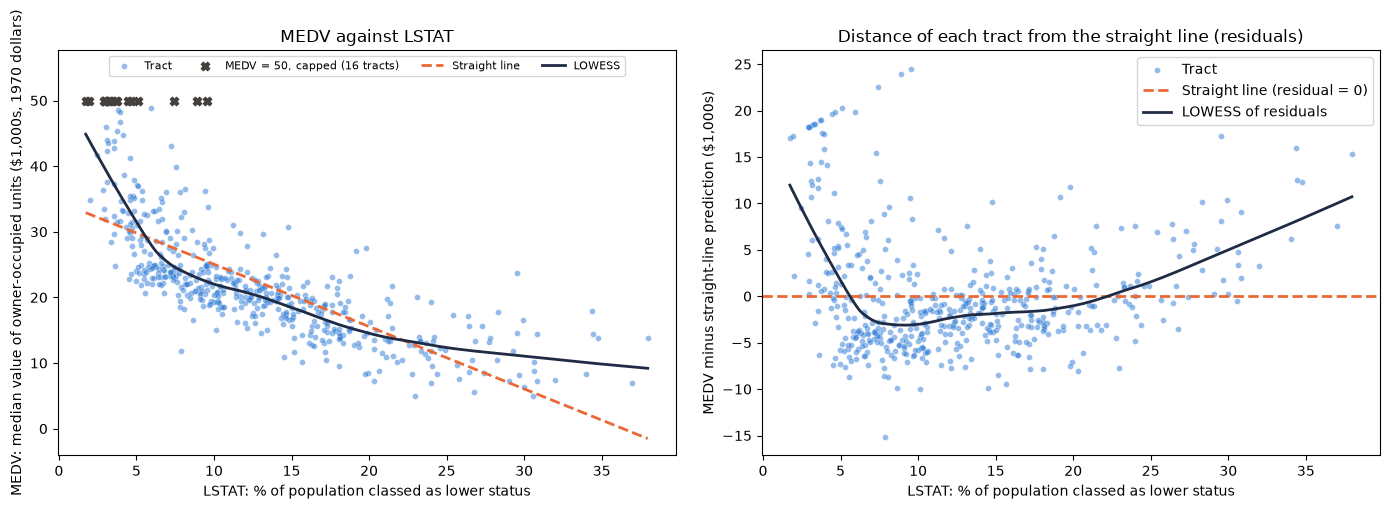

In [103]:
fit = sm.OLS(df["MEDV"], sm.add_constant(df["LSTAT"])).fit()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["LSTAT"], df["MEDV"])
axes[0].set_title("MEDV against LSTAT")

# Residuals: how far each tract sits above (+) or below (-) the straight line. A straight relationship leaves
# no pattern here; a curve leaves a U or an arch
axes[1].scatter(df["LSTAT"], fit.resid, s=18, alpha=0.5, color=POINT_COLOUR, edgecolor="white", linewidth=0.3,
                label="Tract")
axes[1].axhline(0, color=LINE_COLOUR, linestyle="--", linewidth=2, label="Straight line (residual = 0)")
smooth = lowess(fit.resid, df["LSTAT"], frac=LOWESS_FRAC)
axes[1].plot(smooth[:, 0], smooth[:, 1], color=LOWESS_COLOUR, linewidth=2, label="LOWESS of residuals")
axes[1].set_title("Distance of each tract from the straight line (residuals)")
axes[1].set_xlabel(LABELS["LSTAT"])
axes[1].set_ylabel("MEDV minus straight-line prediction ($1,000s)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [104]:
lstat_bins = equal_bins(df["LSTAT"])
print(binned_summary(lstat_bins, df["MEDV"]))

capped_lstat = df.loc[CAPPED, "LSTAT"]
print(f"\nCapped tracts (MEDV = 50): LSTAT from {capped_lstat.min()} to {capped_lstat.max()}; "
      f"{(capped_lstat <= df['LSTAT'].quantile(0.2)).sum()} of {len(capped_lstat)} are in the lowest fifth of LSTAT")
print()
log_check(df["LSTAT"], df["MEDV"])

              tracts  median    mean     iqr   min   max
LSTAT                                                   
1.73 to 6.29     102   32.45  34.089  15.975  20.6  50.0
6.36 to 9.53     101   23.90  25.764   6.100  11.9  50.0
9.54 to 13.3     101   21.20  21.318   3.500  14.5  33.8
13.3 to 18.1     101   18.40  18.023   4.500   9.6  30.7
18.1 to 38       101   13.40  13.355   5.200   5.0  27.5

Capped tracts (MEDV = 50): LSTAT from 1.73 to 9.53; 13 of 16 are in the lowest fifth of LSTAT

Pearson r, LSTAT and MEDV             -0.738
Pearson r, log(LSTAT) and MEDV        -0.815
Pearson r, LSTAT and log(MEDV)        -0.805
Pearson r, log(LSTAT) and log(MEDV)   -0.823


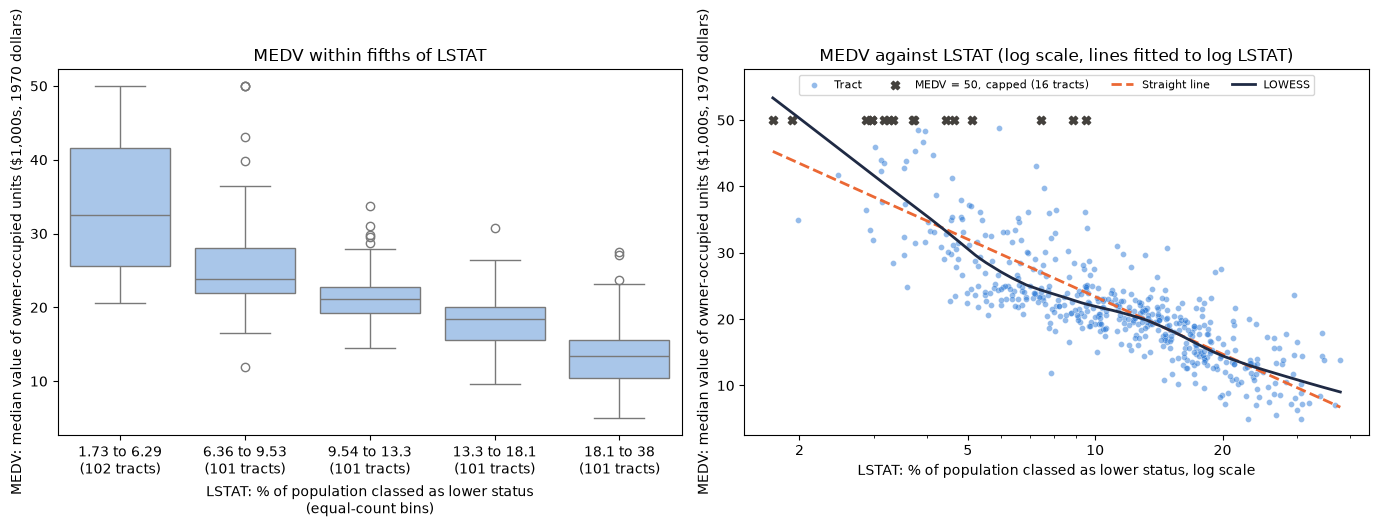

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
box_by_group(axes[0], lstat_bins, df["MEDV"])
axes[0].set_title("MEDV within fifths of LSTAT")
axes[0].set_xlabel(LABELS["LSTAT"] + "\n(equal-count bins)")
scatter_fit(axes[1], df["LSTAT"], df["MEDV"], logx=True)
axes[1].set_title("MEDV against LSTAT (log scale, lines fitted to log LSTAT)")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `LSTAT` vs `MEDV`

- **Direction and strength:** the strongest pair with `MEDV` (r = -0.738, ρ = -0.853).

- **Shape: curved (convex).**
    - |ρ| exceeds |r| by 0.115. Adding a squared term lifts R² from 0.544 to 0.641 (+0.097), the largest gain among the features tested against `MEDV`.
    - The residual plot shows a U shape. The LOWESS curve of the residuals is above zero at both ends (`LSTAT` below about 6 and above about 23) and below zero in between. So the straight line under-predicts both ends and over-predicts the middle.
    - Median `MEDV` by fifth falls by 8.55 between the first two fifths (32.45 to 23.90), then by only 2.70, 2.80 and 5.00 per step.

- **Spread: a fan that narrows as `LSTAT` rises** (Breusch-Pagan p = 8.3e-05). The IQR is 15.98 in the lowest fifth, against 3.50 to 6.10 in the other four.

- **Transformation:** log(`LSTAT`) strengthens r to -0.815, and the log of both to -0.823. On the log scale the LOWESS curve is close to straight, except below `LSTAT` of about 5, where the capped tracts sit.

- **Censoring:** all 16 capped tracts have `LSTAT` at or below 9.53, and 13 of them are in the lowest fifth. They are part of why that fifth is so spread out. r strengthens to -0.760 without them.

- **Implication:** log(`LSTAT`), and possibly log(`MEDV`), suit a linear model better than the raw values.

### Bivariate - feature against feature
Question 4 asks for the pairs with |r| ≥ 0.7. The screening table found eight. One of them, `LSTAT` vs `MEDV`, is covered above. The other seven are examined here. They are followed by the six pairs whose Spearman ρ reaches 0.7 while Pearson r doesn't. All six involve `CRIM`, so they are examined together, with `RAD` and `TAX` looked at more closely.

`RAD`, `TAX` and `INDUS` are town-level, so many tracts share the same value pair. For those pairs a bubble plot is used (one circle per distinct value pair, with area set by the number of tracts), and r is also computed over distinct value pairs, so each combination counts once rather than once per tract.

### Bivariate - `RAD` vs `TAX`
The strongest pair in the dataset (r = 0.91). Both are town-level, and both have a separate top group (`RAD` = 24, `TAX` 666 to 711).

In [106]:
pair_stats(df["RAD"], df["TAX"])

TAX against RAD, 506 tracts
Pearson r:     +0.910  (p = 4.1e-195)
Spearman rho:  +0.705  (p = 3.4e-77)   |rho| - |r| = -0.205
R-squared, straight line: 0.829   with a squared term: 0.832   (gain +0.003)
Breusch-Pagan p = 7.4e-05  (below 0.05: the spread around the straight line changes with RAD)


In [107]:
print(pd.crosstab(df["RAD"], tax_groups))
print(f"\nTracts at RAD = 24 and TAX = 666: {((df['RAD'] == 24) & (df['TAX'] == 666)).sum()}")

distinct = df[["RAD", "TAX"]].drop_duplicates()
print(f"Distinct (RAD, TAX) combinations: {len(distinct)}   r over them = {distinct['RAD'].corr(distinct['TAX']):+.3f}, "
      f"rho = {distinct['RAD'].corr(distinct['TAX'], method='spearman'):+.3f}")
lower_tax = df[df["TAX_group"] == "lower"]
print(f"Lower TAX cluster only ({len(lower_tax)} tracts): r = {lower_tax['RAD'].corr(lower_tax['TAX']):+.3f}, "
      f"rho = {lower_tax['RAD'].corr(lower_tax['TAX'], method='spearman'):+.3f}")

col_0  Lower (TAX ≤ 500)  Higher (TAX > 500)
RAD                                         
1                     20                   0
2                     24                   0
3                     38                   0
4                    105                   5
5                    115                   0
6                     26                   0
7                     17                   0
8                     24                   0
24                     0                 132

Tracts at RAD = 24 and TAX = 666: 132
Distinct (RAD, TAX) combinations: 77   r over them = +0.422, rho = +0.169
Lower TAX cluster only (369 tracts): r = +0.250, rho = +0.333


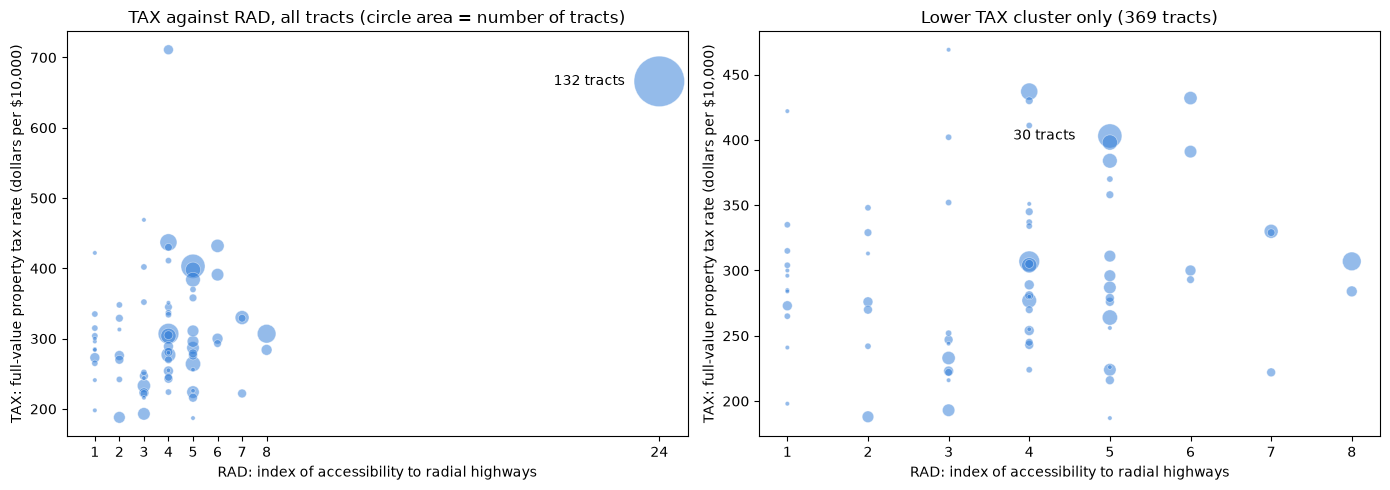

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bubble(axes[0], df["RAD"], df["TAX"])
axes[0].set_title("TAX against RAD, all tracts (circle area = number of tracts)")
bubble(axes[1], lower_tax["RAD"], lower_tax["TAX"])
axes[1].set_title(f"Lower TAX cluster only ({len(lower_tax)} tracts)")
axes[0].set_xticks(sorted(df["RAD"].unique()))
axes[1].set_xticks(sorted(lower_tax["RAD"].unique()))
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `RAD` vs `TAX`

- **Strength:** r = 0.910, the strongest pair in the dataset, but ρ is only 0.705. When r is this much larger than ρ, a few extreme points are doing most of the work.

- **One cluster makes the correlation.** All 132 tracts with `RAD` = 24 have `TAX` = 666. Every tract with `TAX` above 500 has `RAD` 24, except 5 tracts at `RAD` 4 (the 5 at `TAX` 711). In the bubble plot, those 132 tracts are a single circle far from the rest.

- **Without the cluster, the relationship is weak.**
    - Inside the lower `TAX` cluster (369 tracts, `RAD` 1 to 8): r = 0.250, ρ = 0.333.
    - Counting each of the 77 distinct (`RAD`, `TAX`) combinations once: r = 0.422, ρ = 0.169.

- **Within `RAD` 1 to 8,** `TAX` varies widely inside most `RAD` values (bubble plot), so `RAD` says little about `TAX` there.

- **Spread:** changes with `RAD` (Breusch-Pagan p = 7.4e-05), as expected from one cluster at the far end.

- **Implication:** `RAD` and `TAX` carry nearly the same information, namely whether a tract belongs to this one group of 132 tracts. Both in one linear model will be collinear (to check with VIF), and the cause is a shared town rather than a steady relationship.

### Bivariate - `NOX` vs `DIS`
Pollution against distance from the employment centres. Spearman ρ (-0.88) is well above Pearson r (-0.77), which points to a curve.

In [109]:
pair_stats(df["DIS"], df["NOX"])

NOX against DIS, 506 tracts
Pearson r:     -0.769  (p = 4.2e-100)
Spearman rho:  -0.880  (p = 4.3e-165)   |rho| - |r| = +0.111
R-squared, straight line: 0.592   with a squared term: 0.700   (gain +0.108)
Breusch-Pagan p = 1.7e-03  (below 0.05: the spread around the straight line changes with DIS)


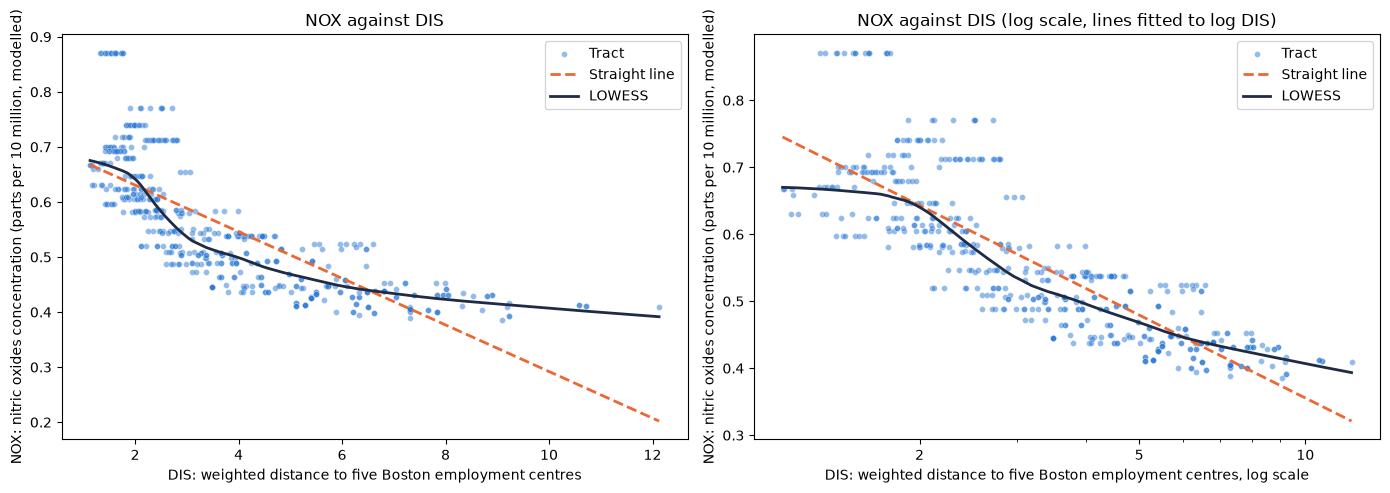

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["DIS"], df["NOX"])
axes[0].set_title("NOX against DIS")
scatter_fit(axes[1], df["DIS"], df["NOX"], logx=True)
axes[1].set_title("NOX against DIS (log scale, lines fitted to log DIS)")
plt.tight_layout()
plt.show()

In [111]:
print(binned_summary(equal_bins(df["DIS"]), df["NOX"]))
print()
log_check(df["DIS"], df["NOX"])

              tracts  median   mean    iqr    min    max
DIS                                                     
1.13 to 1.95     103   0.693  0.698  0.087  0.581  0.871
1.97 to 2.64     100   0.607  0.629  0.132  0.488  0.770
2.65 to 3.88     101   0.510  0.531  0.058  0.437  0.770
3.88 to 5.62     101   0.469  0.478  0.087  0.411  0.583
5.65 to 12.1     101   0.431  0.435  0.039  0.385  0.524

Pearson r, DIS and NOX                -0.769
Pearson r, log(DIS) and NOX           -0.832
Pearson r, DIS and log(NOX)           -0.808
Pearson r, log(DIS) and log(NOX)      -0.860


#### Observations from bivariate analysis of `NOX` vs `DIS`

- **Direction and strength:** strongly negative (r = -0.769, ρ = -0.880). Pollution is highest close to the employment centres.

- **Shape: falls fast near the centres, then levels off.**
    - Median `NOX` by fifth of `DIS` is 0.693, 0.607, 0.510, 0.469 and 0.431. It drops by 0.183 across the first three fifths (`DIS` 1.13 to 3.88) and by only 0.079 across the last two (3.88 to 12.1).
    - Adding a squared term lifts R² from 0.592 to 0.700 (+0.108), the largest gain of any pair in this analysis.
    - The straight line predicts `NOX` of about 0.2 at `DIS` 12, well below the lowest value observed (0.385).

- **Transformation:** log(`DIS`) strengthens r to -0.832, and the log of both to -0.860.

- **Spread:** narrower far from the centres (Breusch-Pagan p = 0.0017). The IQR is 0.087 and 0.132 in the closest two fifths, against 0.039 in the farthest.

- **Implication:** the two are strongly linked, and more so once `DIS` is logged. They will be collinear in a linear model.

### Bivariate - `INDUS` vs `NOX`
Industry against pollution. `INDUS` is town-level and `NOX` is modelled per zone, so both repeat across tracts.

In [112]:
pair_stats(df["INDUS"], df["NOX"])

NOX against INDUS, 506 tracts
Pearson r:     +0.764  (p = 7.9e-98)
Spearman rho:  +0.791  (p = 1.0e-109)   |rho| - |r| = +0.028
R-squared, straight line: 0.583   with a squared term: 0.593   (gain +0.009)
Breusch-Pagan p = 1.8e-15  (below 0.05: the spread around the straight line changes with INDUS)


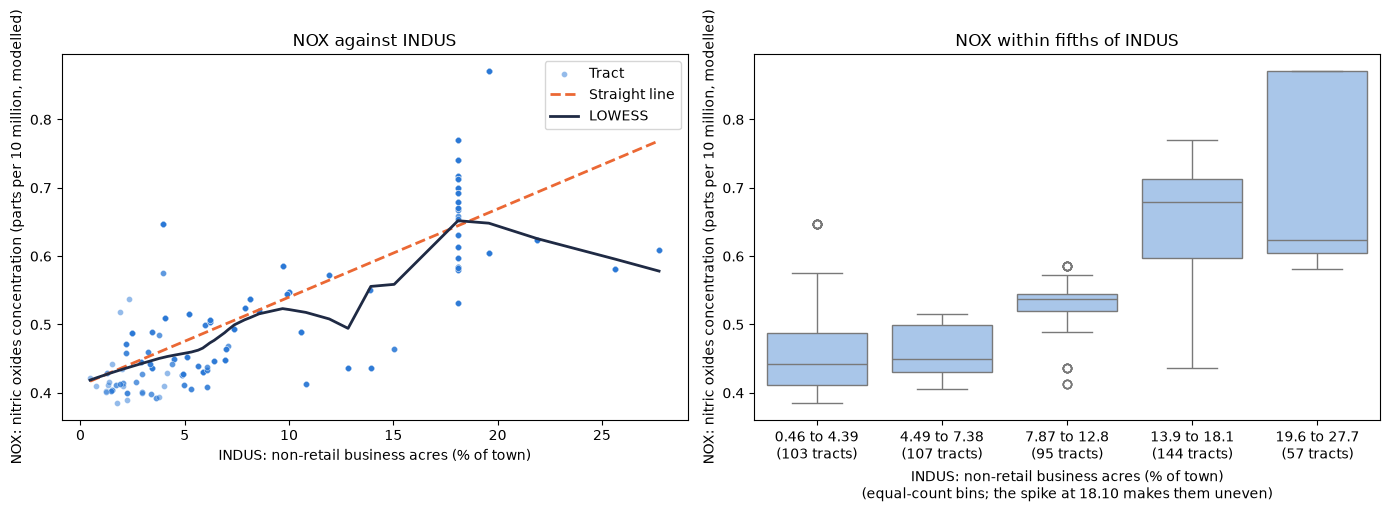

In [113]:
indus_bins = equal_bins(df["INDUS"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["INDUS"], df["NOX"])
axes[0].set_title("NOX against INDUS")
box_by_group(axes[1], indus_bins, df["NOX"])
axes[1].set_title("NOX within fifths of INDUS")
axes[1].set_xlabel(LABELS["INDUS"] + "\n(equal-count bins; the spike at 18.10 makes them uneven)")
plt.tight_layout()
plt.show()

In [114]:
print(binned_summary(indus_bins, df["NOX"]))

distinct = df[["INDUS", "NOX"]].drop_duplicates()
print(f"\nDistinct (INDUS, NOX) combinations: {len(distinct)}   r over them = {distinct['INDUS'].corr(distinct['NOX']):+.3f}")
for name, part in df.groupby("INDUS_group"):
    print(f"Inside the {name}-INDUS cluster ({len(part)} tracts): r = {part['INDUS'].corr(part['NOX']):+.3f}, "
          f"NOX IQR = {part['NOX'].quantile(0.75) - part['NOX'].quantile(0.25):.3f}")

              tracts  median   mean    iqr    min    max
INDUS                                                   
0.46 to 4.39     103   0.443  0.466  0.076  0.385  0.647
4.49 to 7.38     107   0.449  0.462  0.068  0.405  0.515
7.87 to 12.8      95   0.538  0.525  0.024  0.413  0.585
13.9 to 18.1     144   0.679  0.656  0.116  0.437  0.770
19.6 to 27.7      57   0.624  0.682  0.266  0.581  0.871

Distinct (INDUS, NOX) combinations: 98   r over them = +0.797
Inside the high-INDUS cluster (189 tracts): r = -0.229, NOX IQR = 0.108
Inside the low-INDUS cluster (317 tracts): r = +0.364, NOX IQR = 0.087


#### Observations from bivariate analysis of `INDUS` vs `NOX`

- **Direction and strength:** r = 0.764 and ρ = 0.791 are close, and a squared term adds only 0.009 to R². The overall trend is close to a straight line.

- **Not created by repeated values:** counting each of the 98 distinct (`INDUS`, `NOX`) combinations once gives r = 0.797, as strong as across tracts. This is unlike `RAD`–`TAX`.

- **Spread: widens sharply at high `INDUS`** (Breusch-Pagan p = 1.8e-15). The `NOX` IQR by fifth of `INDUS` is 0.076, 0.068, 0.024, 0.116 and 0.266.

- **Inside the clusters:**
    - In the low-`INDUS` cluster, `NOX` still rises with `INDUS` (r = 0.364).
    - In the high-`INDUS` cluster it doesn't (r = -0.229). In the top fifth of `INDUS` (19.6 to 27.7), `NOX` ranges from 0.581 to 0.871. The LOWESS curve turns down after `INDUS` of about 19.

- **Implication:** much of the link is the difference between the industrial cluster and the rest, with a modest rise inside the low cluster.

### Bivariate - `AGE` vs `DIS`
The share of housing built before 1940 against distance from the employment centres.

In [115]:
pair_stats(df["AGE"], df["DIS"])

DIS against AGE, 506 tracts
Pearson r:     -0.748  (p = 9.9e-92)
Spearman rho:  -0.802  (p = 1.1e-114)   |rho| - |r| = +0.054
R-squared, straight line: 0.559   with a squared term: 0.565   (gain +0.005)
Breusch-Pagan p = 3.8e-08  (below 0.05: the spread around the straight line changes with AGE)


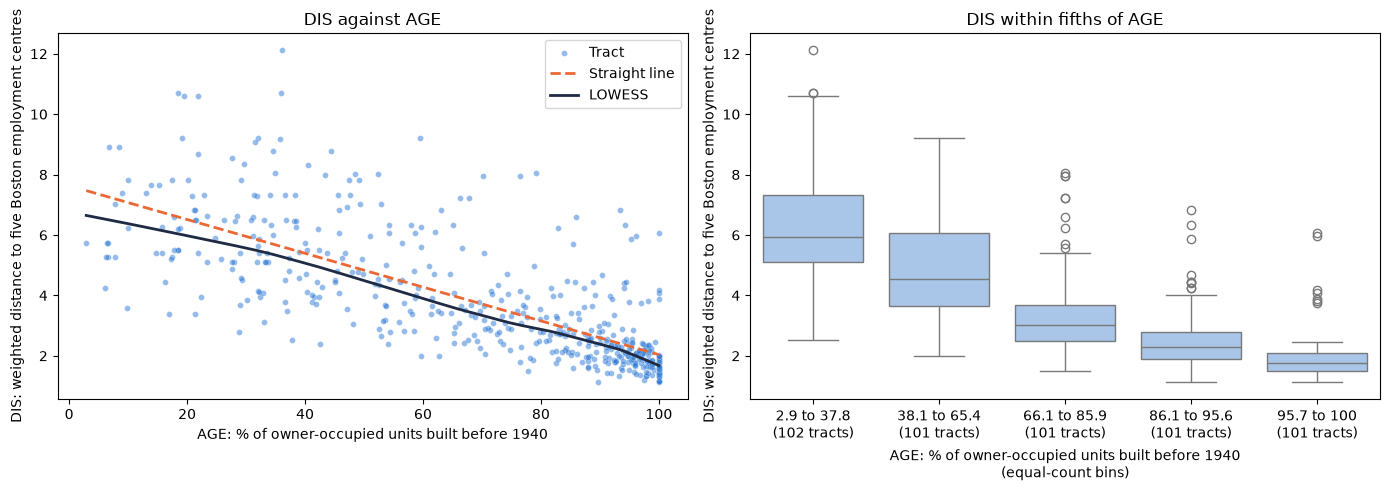

In [116]:
age_bins = equal_bins(df["AGE"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["AGE"], df["DIS"])
axes[0].set_title("DIS against AGE")
box_by_group(axes[1], age_bins, df["DIS"])
axes[1].set_title("DIS within fifths of AGE")
axes[1].set_xlabel(LABELS["AGE"] + "\n(equal-count bins)")
plt.tight_layout()
plt.show()

In [117]:
print(binned_summary(age_bins, df["DIS"]))
print()
log_check(df["AGE"], df["DIS"])

              tracts  median   mean    iqr    min     max
AGE                                                      
2.9 to 37.8      102   5.923  6.221  2.198  2.519  12.126
38.1 to 65.4     101   4.540  4.869  2.410  1.986   9.223
66.1 to 85.9     101   3.033  3.370  1.166  1.500   8.056
86.1 to 95.6     101   2.305  2.551  0.892  1.130   6.818
95.7 to 100      101   1.757  1.941  0.589  1.137   6.082

Pearson r, AGE and DIS                -0.748
Pearson r, log(AGE) and DIS           -0.677
Pearson r, AGE and log(DIS)           -0.778
Pearson r, log(AGE) and log(DIS)      -0.687


#### Observations from bivariate analysis of `AGE` vs `DIS`

- **Direction and strength:** r = -0.748, ρ = -0.802. Tracts with older housing are closer to the employment centres.

- **Shape: close to a straight line in level.** A squared term adds only 0.005, and the LOWESS curve follows the straight line. Median `DIS` falls at every step: 5.923, 4.540, 3.033, 2.305 and 1.757 by fifth of `AGE`.

- **Spread: a fan that narrows as `AGE` rises** (Breusch-Pagan p = 3.8e-08).
    - The IQR of `DIS` by fifth is 2.198, 2.410, 1.166, 0.892 and 0.589.
    - Tracts with mostly newer housing sit at every distance (2.52 to 12.13 in the youngest fifth).
    - Tracts with mostly old housing are nearly all close in (median 1.757, maximum 6.08 in the oldest fifth).

- **Transformation:** log(`DIS`) strengthens r to -0.778. log(`AGE`) weakens it (-0.677), because `AGE` is left-skewed.

### Bivariate - `NOX` vs `AGE`
Pollution against the share of housing built before 1940.

In [118]:
pair_stats(df["AGE"], df["NOX"])

NOX against AGE, 506 tracts
Pearson r:     +0.731  (p = 7.5e-86)
Spearman rho:  +0.795  (p = 1.5e-111)   |rho| - |r| = +0.064
R-squared, straight line: 0.535   with a squared term: 0.572   (gain +0.037)
Breusch-Pagan p = 6.0e-10  (below 0.05: the spread around the straight line changes with AGE)


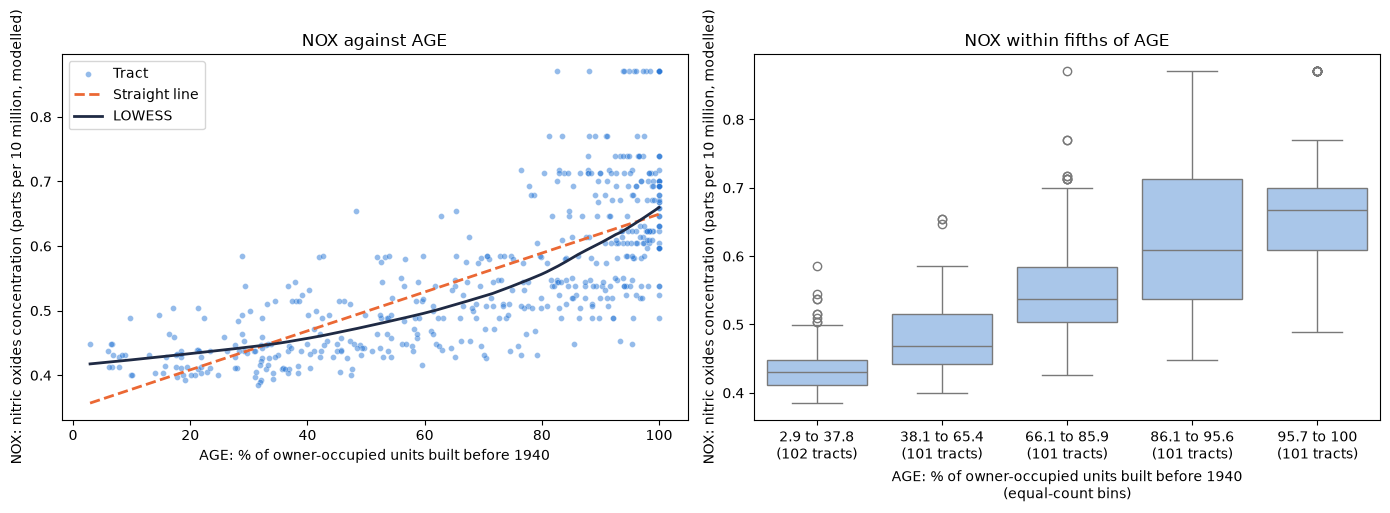

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["AGE"], df["NOX"])
axes[0].set_title("NOX against AGE")
box_by_group(axes[1], age_bins, df["NOX"])
axes[1].set_title("NOX within fifths of AGE")
axes[1].set_xlabel(LABELS["AGE"] + "\n(equal-count bins)")
plt.tight_layout()
plt.show()

In [120]:
print(binned_summary(age_bins, df["NOX"]))
print()
log_check(df["AGE"], df["NOX"])

              tracts  median   mean    iqr    min    max
AGE                                                     
2.9 to 37.8      102   0.431  0.438  0.037  0.385  0.585
38.1 to 65.4     101   0.469  0.485  0.073  0.400  0.655
66.1 to 85.9     101   0.538  0.556  0.080  0.426  0.871
86.1 to 95.6     101   0.609  0.625  0.175  0.448  0.871
95.7 to 100      101   0.668  0.672  0.091  0.489  0.871

Pearson r, AGE and NOX                +0.731
Pearson r, log(AGE) and NOX           +0.640
Pearson r, AGE and log(NOX)           +0.766
Pearson r, log(AGE) and log(NOX)      +0.677


#### Observations from bivariate analysis of `NOX` vs `AGE`

- **Direction and strength:** r = 0.731, ρ = 0.795.

- **Shape: gentle at first, then steeper (convex).**
    - Median `NOX` by fifth of `AGE` is 0.431, 0.469, 0.538, 0.609 and 0.668. It rises by 0.038 between the first two fifths, then by 0.069, 0.071 and 0.059.
    - The LOWESS curve is nearly flat up to `AGE` of about 40 and climbs after about 60.
    - A squared term adds 0.037 to R².

- **Spread: a fan that widens as `AGE` rises** (Breusch-Pagan p = 6.0e-10).
    - The `NOX` IQR is 0.037 in the youngest fifth, against 0.175 in the 86.1 to 95.6 fifth.
    - The isolated `NOX` = 0.871 group only appears in the fifths above `AGE` 66. The maximum `NOX` is 0.585 and 0.655 in the youngest two fifths.

- **Transformation:** log(`NOX`) strengthens r to 0.766, while log(`AGE`) weakens it (0.640).

### Bivariate - `INDUS` vs `TAX`
Both are town-level, and each has a large spike (`INDUS` = 18.10 and `TAX` = 666, both 132 tracts).

In [121]:
pair_stats(df["INDUS"], df["TAX"])

TAX against INDUS, 506 tracts
Pearson r:     +0.721  (p = 3.0e-82)
Spearman rho:  +0.664  (p = 1.0e-65)   |rho| - |r| = -0.056
R-squared, straight line: 0.519   with a squared term: 0.530   (gain +0.010)
Breusch-Pagan p = 2.5e-26  (below 0.05: the spread around the straight line changes with INDUS)


In [122]:
print(pd.crosstab(indus_groups, tax_groups))
print(f"\nTracts at INDUS = 18.10 and TAX = 666: {((df['INDUS'] == 18.10) & (df['TAX'] == 666)).sum()}")

distinct = df[["INDUS", "TAX"]].drop_duplicates()
print(f"Distinct (INDUS, TAX) combinations: {len(distinct)}   r over them = {distinct['INDUS'].corr(distinct['TAX']):+.3f}, "
      f"rho = {distinct['INDUS'].corr(distinct['TAX'], method='spearman'):+.3f}")
print(f"Lower TAX cluster only ({len(lower_tax)} tracts): r = {lower_tax['INDUS'].corr(lower_tax['TAX']):+.3f}, "
      f"rho = {lower_tax['INDUS'].corr(lower_tax['TAX'], method='spearman'):+.3f}")

col_0               Lower (TAX ≤ 500)  Higher (TAX > 500)
row_0                                                    
Low (INDUS ≤ 16%)                 317                   0
High (INDUS > 16%)                 52                 137

Tracts at INDUS = 18.10 and TAX = 666: 132
Distinct (INDUS, TAX) combinations: 77   r over them = +0.426, rho = +0.192
Lower TAX cluster only (369 tracts): r = +0.416, rho = +0.386


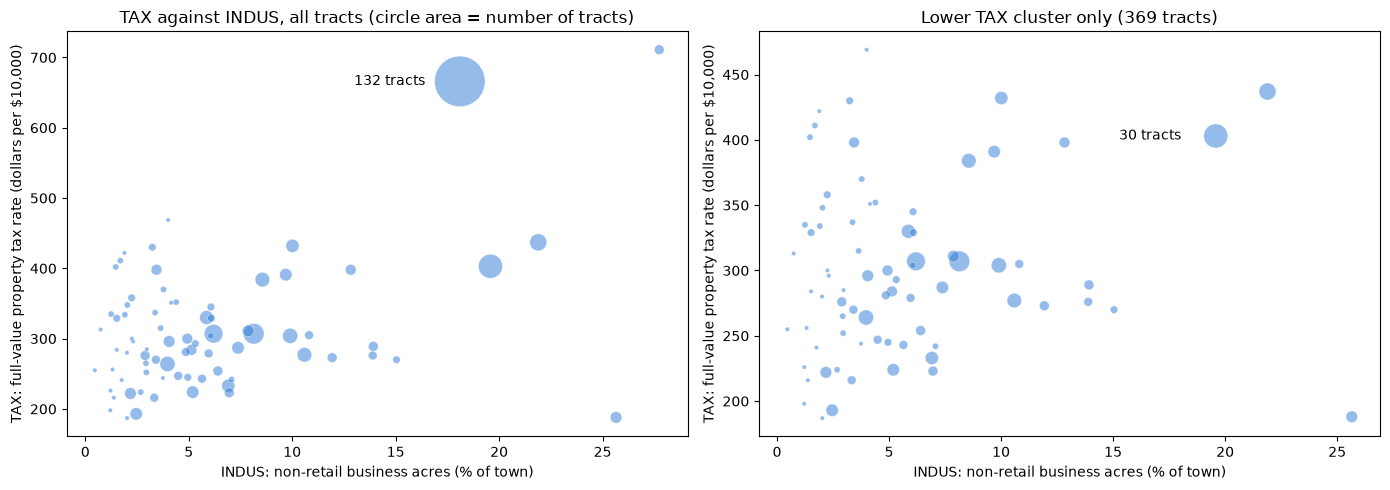

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bubble(axes[0], df["INDUS"], df["TAX"])
axes[0].set_title("TAX against INDUS, all tracts (circle area = number of tracts)")
bubble(axes[1], lower_tax["INDUS"], lower_tax["TAX"])
axes[1].set_title(f"Lower TAX cluster only ({len(lower_tax)} tracts)")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `INDUS` vs `TAX`

- **Strength:** r = 0.721, but ρ is lower (0.664), the same warning sign as `RAD`–`TAX`.

- **One cluster again.** 132 tracts sit at `INDUS` = 18.10 and `TAX` = 666, the large circle in the bubble plot. All 317 low-`INDUS` tracts are in the lower `TAX` cluster. The high-`INDUS` tracts split between both clusters (52 lower, 137 higher).

- **The same 132 tracts:** `TAX` = 666 holds exactly 132 tracts (univariate). The `RAD`–`TAX` crosstab showed all of them at `RAD` 24, and the count above shows all of them at `INDUS` 18.10. So `RAD` 24, `TAX` 666 and `INDUS` 18.10 mark the same 132 tracts.

- **Without the cluster, the relationship is moderate.**
    - Counting each of the 77 distinct (`INDUS`, `TAX`) combinations once: r = 0.426, ρ = 0.192.
    - Inside the lower `TAX` cluster: r = 0.416, ρ = 0.386.

- **Spread:** changes strongly with `INDUS` (Breusch-Pagan p = 2.5e-26), because high-`INDUS` towns sit in both `TAX` clusters.

- **Implication:** most of the 0.721 comes from the 132-tract cluster. The underlying relationship between towns is about 0.42.

### Bivariate - `INDUS` vs `DIS`
Industry against distance from the employment centres.

In [124]:
pair_stats(df["INDUS"], df["DIS"])

DIS against INDUS, 506 tracts
Pearson r:     -0.708  (p = 3.6e-78)
Spearman rho:  -0.757  (p = 3.1e-95)   |rho| - |r| = +0.049
R-squared, straight line: 0.501   with a squared term: 0.521   (gain +0.020)
Breusch-Pagan p = 4.8e-21  (below 0.05: the spread around the straight line changes with INDUS)


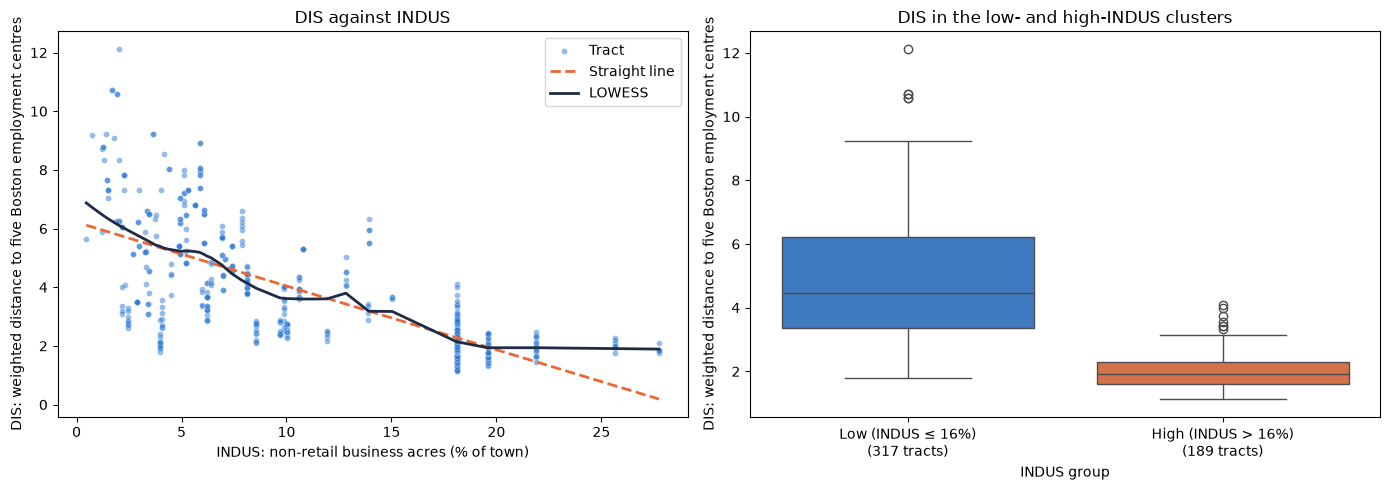

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["INDUS"], df["DIS"])
axes[0].set_title("DIS against INDUS")
box_by_group(axes[1], indus_groups, df["DIS"], colours=GROUP_COLOURS)
axes[1].set_title("DIS in the low- and high-INDUS clusters")
axes[1].set_xlabel("INDUS group")
plt.tight_layout()
plt.show()

In [126]:
print(binned_summary(indus_bins, df["DIS"]))
print()
print(binned_summary(indus_groups, df["DIS"]))
print()
log_check(df["INDUS"], df["DIS"])

              tracts  median   mean    iqr    min     max
INDUS                                                    
0.46 to 4.39     103   5.245  5.413  4.152  1.801  12.126
4.49 to 7.38     107   5.401  5.422  2.362  2.862   8.907
7.87 to 12.8      95   3.796  3.680  1.659  2.107   6.592
13.9 to 18.1     144   2.000  2.257  0.959  1.130   6.320
19.6 to 27.7      57   1.850  1.894  0.442  1.322   2.470

                    tracts  median   mean    iqr    min     max
Low (INDUS ≤ 16%)      317   4.455  4.859  2.859  1.801  12.126
High (INDUS > 16%)     189   1.914  2.011  0.671  1.130   4.098

Pearson r, INDUS and DIS              -0.708
Pearson r, log(INDUS) and DIS         -0.717
Pearson r, INDUS and log(DIS)         -0.761
Pearson r, log(INDUS) and log(DIS)    -0.730


#### Observations from bivariate analysis of `INDUS` vs `DIS`

- **Direction and strength:** r = -0.708, ρ = -0.757. Industrial towns are close to the employment centres.

- **Shape: falls, then levels off.**
    - Median `DIS` by fifth of `INDUS` is 5.245, 5.401, 3.796, 2.000 and 1.850.
    - The LOWESS curve falls from about 7 to about 2 by `INDUS` 18 and is flat after that. A squared term adds 0.020 to R².
    - The straight line predicts `DIS` of about 0.2 at `INDUS` 27.7, below the lowest distance observed (1.13).

- **Spread: narrows sharply** (Breusch-Pagan p = 4.8e-21).
    - The IQR of `DIS` by fifth is 4.152, 2.362, 1.659, 0.959 and 0.442.
    - Every high-`INDUS` tract lies within `DIS` 4.10 (median 1.914), while low-`INDUS` tracts span 1.80 to 12.13 (median 4.455).

- **Transformation:** log(`DIS`) gives the strongest r (-0.761). Logging `INDUS` as well weakens it (-0.730).

### Bivariate - `CRIM` against the other features
Six pairs reach |ρ| ≥ 0.7 while |r| stays below 0.7, and all six involve `CRIM` (with `NOX`, `DIS`, `INDUS`, `TAX`, `RAD` and `AGE`). `CRIM` is extremely right-skewed (univariate). This checks whether that skew is hiding stronger relationships from Pearson r.

In [127]:
# Pearson r against CRIM, against log(CRIM), and Spearman rho (which only uses ranks, so the skew can't affect it)
others = [c for c in FEATURES if c != "CRIM"]
crim_table = pd.DataFrame({
    "pearson r": [df["CRIM"].corr(df[c]) for c in others],
    "pearson r, log(CRIM)": [np.log(df["CRIM"]).corr(df[c]) for c in others],
    "spearman rho": [df["CRIM"].corr(df[c], method="spearman") for c in others],
}, index=others)
crim_table["gain from log"] = crim_table["pearson r, log(CRIM)"].abs() - crim_table["pearson r"].abs()
crim_table.sort_values("spearman rho", key=abs, ascending=False).round(3)

,pearson r,"pearson r, log(CRIM)",spearman rho,gain from log
NOX,0.421,0.789,0.821,0.368
DIS,-0.380,-0.682,-0.745,0.302
INDUS,0.407,0.731,0.736,0.324
TAX,0.583,0.828,0.729,0.245
RAD,0.626,0.853,0.728,0.228
AGE,0.353,0.658,0.704,0.306
LSTAT,0.456,0.627,0.635,0.171
ZN,-0.200,-0.517,-0.572,0.317
MEDV,-0.388,-0.454,-0.559,0.066
PTRATIO,0.290,0.390,0.465,0.100


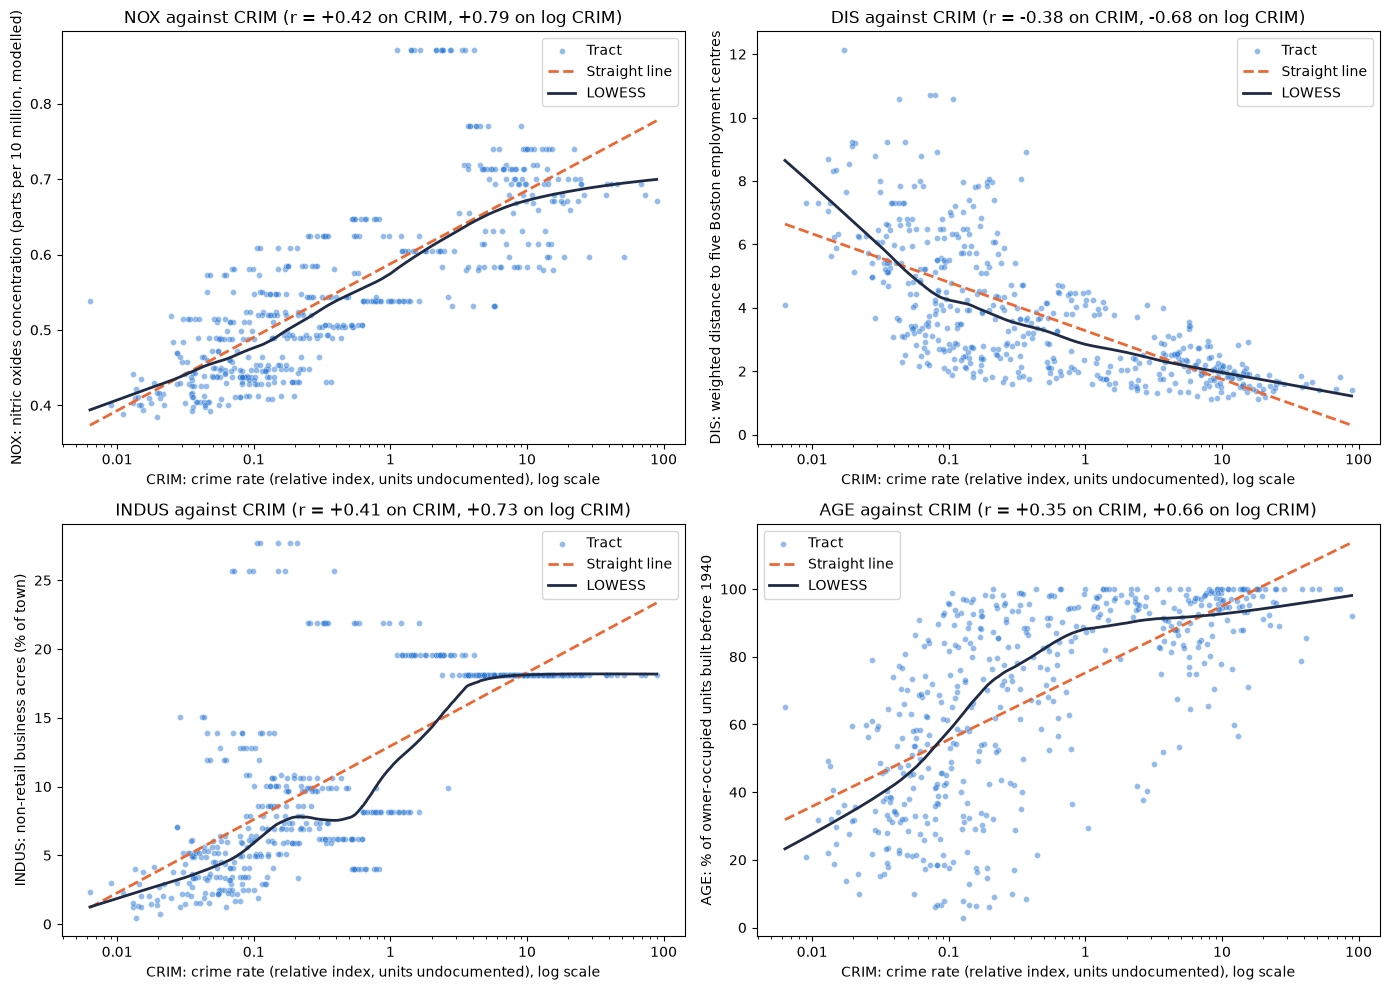

In [128]:
# The four continuous features among the six, each against CRIM on a log scale
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, ["NOX", "DIS", "INDUS", "AGE"]):
    scatter_fit(ax, df["CRIM"], df[col], logx=True)
    ax.set_title(f"{col} against CRIM (r = {df['CRIM'].corr(df[col]):+.2f} on CRIM, "
                 f"{np.log(df['CRIM']).corr(df[col]):+.2f} on log CRIM)")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `CRIM` against the other features

- **The skew hides the relationships.** Taking the log of `CRIM` strengthens |r| with 11 of the other 12 features. The largest gains are `NOX` (+0.368, from 0.421 to 0.789), `INDUS` (+0.324), `ZN` (+0.317), `AGE` (+0.306), `DIS` (+0.302), `TAX` (+0.245) and `RAD` (+0.228). Only `CHAS` doesn't strengthen (-0.027), and it is close to zero either way.

- **On log(`CRIM`), four pairs pass |r| ≥ 0.7:** `RAD` (0.853), `TAX` (0.828), `NOX` (0.789) and `INDUS` (0.731). `DIS` (-0.682) and `AGE` (0.658) come close.
    - For `NOX` and `INDUS`, r on log(`CRIM`) almost matches Spearman ρ (0.789 against 0.821, and 0.731 against 0.736). So the low Pearson r was caused by the skew.
    - For `RAD` and `TAX`, it goes beyond ρ (0.853 against 0.728, and 0.828 against 0.729). On the log scale, the 132-tract cluster sits far from everything else (next two sections).

- **Shapes on the log scale:**
    - `NOX` rises steadily and stays close to the straight line.
    - `DIS` falls, more steeply at the low-crime end.
    - `INDUS` rises in steps and flattens at 18.10 for `CRIM` above about 4 (the 132-tract cluster).
    - `AGE` rises and then flattens near 100 for `CRIM` above about 1.

- **Implication:** if `CRIM` is logged for modelling, as the univariate analysis suggests, it becomes strongly collinear with `RAD`, `TAX`, `NOX` and `INDUS`. This needs checking in the multivariate analysis.

### Bivariate - `CRIM` vs `RAD`
`RAD` is an ordered index rather than a measurement, so `CRIM` is compared category by category.

In [129]:
print(f"Pearson r = {df['RAD'].corr(df['CRIM']):+.3f}   Spearman rho = {df['RAD'].corr(df['CRIM'], method='spearman'):+.3f}   "
      f"Pearson r with log(CRIM) = {df['RAD'].corr(np.log(df['CRIM'])):+.3f}\n")
print(binned_summary(df["RAD"], df["CRIM"]))
print()
print(pd.crosstab(crim_groups, df["RAD"]))

Pearson r = +0.626   Spearman rho = +0.728   Pearson r with log(CRIM) = +0.853

     tracts  median    mean    iqr    min     max
RAD                                              
1        20   0.032   0.036  0.034  0.006   0.110
2        24   0.063   0.083  0.064  0.021   0.387
3        38   0.069   0.097  0.100  0.014   0.299
4       110   0.212   0.394  0.544  0.014   2.635
5       115   0.170   0.688  1.088  0.013   4.097
6        26   0.137   0.150  0.075  0.039   0.290
7        17   0.140   0.150  0.122  0.035   0.369
8        24   0.395   0.371  0.247  0.103   0.624
24      132   9.085  12.759  8.647  2.379  88.976

RAD              1   2   3   4   5   6   7   8    24
row_0                                               
Low (CRIM ≤ 1)   20  24  38  98  85  26  17  24    0
High (CRIM > 1)   0   0   0  12  30   0   0   0  132


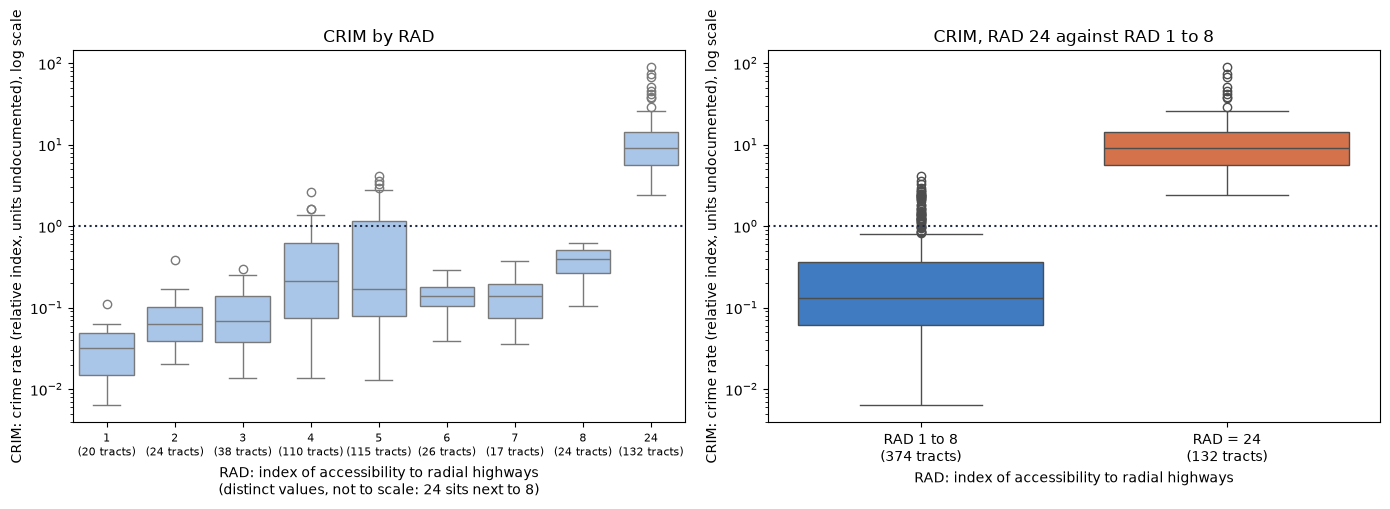

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
box_by_group(axes[0], df["RAD"], df["CRIM"], order=sorted(df["RAD"].unique()))
axes[0].set_title("CRIM by RAD")
axes[0].set_xlabel(LABELS["RAD"] + "\n(distinct values, not to scale: 24 sits next to 8)")
axes[0].tick_params(axis="x", labelsize=8)
box_by_group(axes[1], rad24, df["CRIM"], colours=GROUP_COLOURS)
axes[1].set_title("CRIM, RAD 24 against RAD 1 to 8")
axes[1].set_xlabel(LABELS["RAD"])
for ax in axes:
    ax.set_yscale("log")
    ax.axhline(1, color=LOWESS_COLOUR, linestyle=":", linewidth=1.5)   # the univariate split between low and high crime
    ax.set_ylabel(LABELS["CRIM"] + ", log scale")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `CRIM` vs `RAD`

- **Every `RAD` 24 tract is high-crime.** All 132 have `CRIM` above 1 (minimum 2.379, median 9.085). For `RAD` 1 to 8, median `CRIM` is between 0.032 and 0.395, and the highest single value is 4.097.

- **The other high-crime tracts:** 42 high-crime tracts lie outside `RAD` 24, all of them at `RAD` 4 (12) or `RAD` 5 (30).

- **Within `RAD` 1 to 8:** median `CRIM` tends to rise from `RAD` 1 (0.032) to `RAD` 8 (0.395), but not in order (`RAD` 4 0.212, `RAD` 6 0.137, `RAD` 7 0.140).

- **Strength:** r = 0.626 on `CRIM`, 0.853 on log(`CRIM`), and ρ = 0.728. Most of it is the step between `RAD` 24 and the rest. On the log scale, the boxes for `RAD` 24 and for `RAD` 1 to 8 don't overlap.

### Bivariate - `CRIM` vs `TAX`
`TAX` has two separate clusters (univariate), so `CRIM` is compared between and within them.

In [131]:
print(f"Pearson r = {df['TAX'].corr(df['CRIM']):+.3f}   Spearman rho = {df['TAX'].corr(df['CRIM'], method='spearman'):+.3f}   "
      f"Pearson r with log(CRIM) = {df['TAX'].corr(np.log(df['CRIM'])):+.3f}\n")
print(binned_summary(tax_groups, df["CRIM"]))
print()
print(pd.crosstab(crim_groups, tax_groups))
print(f"\nLower TAX cluster only ({len(lower_tax)} tracts): r with log(CRIM) = "
      f"{lower_tax['TAX'].corr(np.log(lower_tax['CRIM'])):+.3f}, rho = {lower_tax['TAX'].corr(lower_tax['CRIM'], method='spearman'):+.3f}")

Pearson r = +0.583   Spearman rho = +0.729   Pearson r with log(CRIM) = +0.828

                    tracts  median    mean    iqr    min     max
Lower (TAX ≤ 500)      369   0.132   0.389  0.311  0.006   4.097
Higher (TAX > 500)     137   8.717  12.299  8.795  0.106  88.976

col_0            Lower (TAX ≤ 500)  Higher (TAX > 500)
row_0                                                 
Low (CRIM ≤ 1)                 327                   5
High (CRIM > 1)                 42                 132

Lower TAX cluster only (369 tracts): r with log(CRIM) = +0.384, rho = +0.400


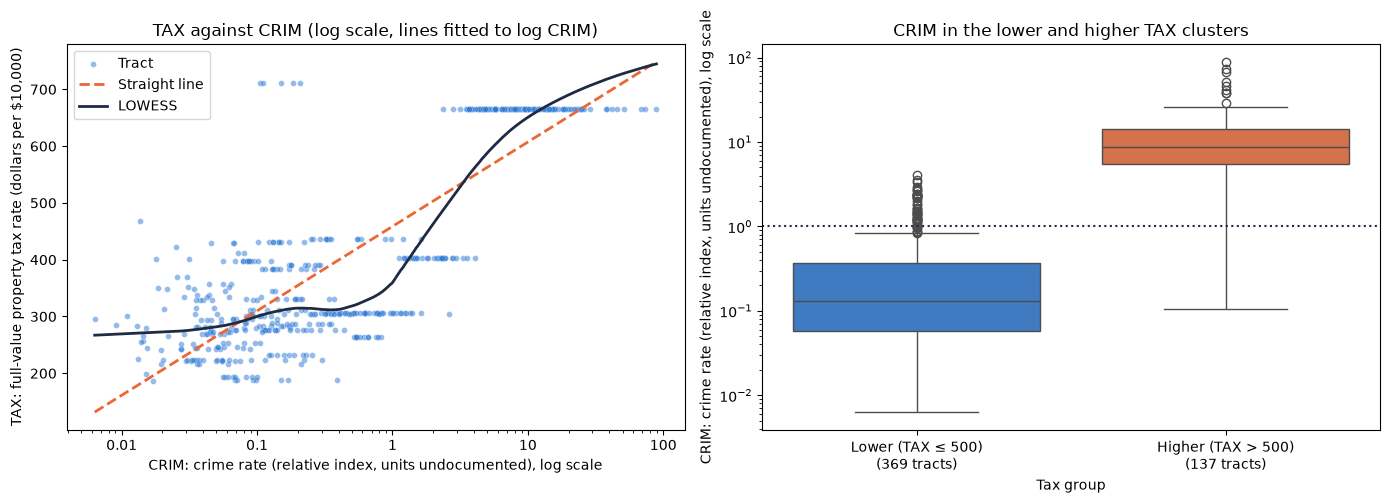

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_fit(axes[0], df["CRIM"], df["TAX"], logx=True)
axes[0].set_title("TAX against CRIM (log scale, lines fitted to log CRIM)")
box_by_group(axes[1], tax_groups, df["CRIM"], colours=GROUP_COLOURS)
axes[1].set_yscale("log")
axes[1].axhline(1, color=LOWESS_COLOUR, linestyle=":", linewidth=1.5)   # the univariate split between low and high crime
axes[1].set_ylabel(LABELS["CRIM"] + ", log scale")
axes[1].set_title("CRIM in the lower and higher TAX clusters")
axes[1].set_xlabel("Tax group")
plt.tight_layout()
plt.show()

#### Observations from bivariate analysis of `CRIM` vs `TAX`

- **The higher `TAX` cluster is high-crime.** Its median `CRIM` is 8.717, against 0.132 in the lower cluster. 132 of its 137 tracts have `CRIM` above 1. The 5 that don't are the 5 tracts at `TAX` 711, because all 132 at `TAX` 666 are the `RAD` 24 tracts, which are all high-crime.

- **Shape: a step.** On the log scale, the LOWESS curve is flat at a `TAX` of about 270 to 310 for `CRIM` below 1, then climbs to 666 above about 3. That is a jump between the clusters rather than a steady rise.

- **Within the lower cluster:** a moderate relationship remains (r with log(`CRIM`) = 0.384, ρ = 0.400).

- **Strength:** r = 0.583 on `CRIM`, 0.828 on log(`CRIM`), and ρ = 0.729.

### Summary of bivariate analysis

| Pair | r | ρ | Shape | Evidence |
|---|---|---|---|---|
| `LSTAT` vs `MEDV` | -0.738 | -0.853 | Convex curve; spread narrows as `LSTAT` rises | Squared term +0.097 R²; log(`LSTAT`) r = -0.815; IQR 15.98 in the lowest fifth against 3.50 to 6.10 |
| `RM` vs `MEDV` | +0.695 | +0.634 | Convex: 3.25 per room below 6.5 rooms, 13.33 above | Squared term +0.065 R²; separate slopes |
| `PTRATIO` vs `MEDV` | -0.508 | -0.556 | Decline, with a low dip at 20.2 | Median 14.9 at 20.2 against 22.8; r = -0.455 without the spike |
| `INDUS` vs `MEDV` | -0.484 | -0.578 | Falls inside the low cluster, flat inside the high one | r inside clusters: -0.440 and +0.026 |
| `TAX` vs `MEDV` | -0.469 | -0.562 | Mostly the gap between two clusters | Medians 22.8 and 14.3; r = -0.292 inside the lower cluster |
| `NOX` vs `MEDV` | -0.427 | -0.563 | Steps, with a ceiling above 0.668 | Medians by fifth; no tract above 27.5 |
| `CRIM` vs `MEDV` | -0.388 | -0.559 | Curved on the raw scale, close to straight on a log scale | r = -0.454 on log(`CRIM`), -0.567 log-log |
| `RAD` vs `MEDV` | -0.382 | -0.347 | `RAD` 24 against the rest; no trend within 1 to 8 | r = +0.075 within `RAD` 1 to 8 |
| `AGE` vs `MEDV` | -0.377 | -0.548 | Shallow, then a fall above about 86% | Medians by fifth |
| `ZN` vs `MEDV` | +0.360 | +0.438 | A step between zero and non-zero | Medians 19.75 and 25.00; r = 0.208 within `ZN` > 0 |
| `DIS` vs `MEDV` | +0.250 | +0.446 | Rises up to `DIS` of about 2.6, then flat | r = -0.003 beyond 2.64 |
| `CHAS` vs `MEDV` | +0.175 | +0.141 | A small premium, largely from capped tracts | Mann-Whitney p = 0.059 without the cap |
| `RAD` vs `TAX` | +0.910 | +0.705 | One 132-tract cluster | r = 0.250 inside the lower `TAX` cluster |
| `NOX` vs `DIS` | -0.769 | -0.880 | Convex decay | Squared term +0.108 R²; log-log r = -0.860 |
| `INDUS` vs `NOX` | +0.764 | +0.791 | Close to straight; spread widens | r = 0.797 on distinct pairs; IQR from 0.024 to 0.266 |
| `AGE` vs `DIS` | -0.748 | -0.802 | Close to straight; spread narrows | IQR from 2.410 to 0.589 |
| `NOX` vs `AGE` | +0.731 | +0.795 | Convex; spread widens | IQR from 0.037 to 0.175 |
| `INDUS` vs `TAX` | +0.721 | +0.664 | One 132-tract cluster | r = 0.426 on distinct pairs |
| `INDUS` vs `DIS` | -0.708 | -0.757 | Falls, then levels off; spread narrows | IQR from 4.152 to 0.442 |
| `CRIM` vs `NOX`, `DIS`, `INDUS`, `AGE`, `TAX`, `RAD` | 0.42, -0.38, 0.41, 0.35, 0.58, 0.63 | 0.82, -0.75, 0.74, 0.70, 0.73, 0.73 | Hidden by the skew in `CRIM` | r on log(`CRIM`): 0.79, -0.68, 0.73, 0.66, 0.83, 0.85 |

**Patterns across the pairs**
- **Most relationships are not straight lines.** For 9 of the 12 features, |ρ| with `MEDV` is larger than |r|. Of the eight pairs with |r| ≥ 0.7, only `INDUS`–`NOX` and `AGE`–`DIS` are close to straight lines without being driven by a cluster, and both have spread that changes along the line.
- **The `MEDV` cap weakens most relationships.** Removing the 16 capped tracts strengthens |r| for 10 of the 12 features, most for `DIS` (+0.119), `INDUS` (+0.116) and `AGE` (+0.116). It weakens `RM` slightly (0.695 to 0.687) and `CHAS` sharply (0.175 to 0.075).
- **One town-level cluster inflates several correlations.** `RAD` 24, `TAX` 666 and `INDUS` 18.10 mark the same 132 tracts. That cluster produces most of `RAD`–`TAX` (0.910, falling to 0.250 without it) and `INDUS`–`TAX` (0.721, falling to 0.416). Its `MEDV` is low: median 14.4 at `RAD` 24 and at `INDUS` 18.10, and 14.3 in the higher `TAX` cluster. Every one of its tracts has `CRIM` above 1.
- **Spread changes along many relationships.** Breusch-Pagan p is below 0.05 for 4 of the 10 `MEDV` pairs tested (`AGE`, `DIS`, `PTRATIO`, `LSTAT`) and for all 7 feature pairs with |r| ≥ 0.7.
- **Transformations suggested by the pairs:**
    - log(`LSTAT`), log(`CRIM`) and log(`DIS`) each straighten their relationships.
    - log(`MEDV`) strengthens r for `CRIM`, `NOX`, `AGE`, `DIS` and `LSTAT`.
    - `RM`'s convex shape suits a squared term.
    - `ZN` and `RAD` work better as groups (`ZN` > 0, `RAD` 24) than as numbers.

**To carry into the multivariate analysis**
- Whether the 132-tract cluster also accounts for the low `MEDV` at `PTRATIO` = 20.2 (140 tracts).
- `NOX`, `DIS`, `AGE` and `INDUS` form a connected group: all six pairs among them have |r| between 0.645 and 0.769. They need to be looked at together (VIF).
- `RM` and `LSTAT`, the two strongest single predictors of `MEDV`, are themselves correlated (r = -0.614).
- Whether the 13 tracts far from the `RM` line (rows 364 to 419) share a town.

#### **Question 4: Do bivariate analysis to visualize the relationship between the features having significant correlations (>= 0.7 or <= -0.7)**

#### **Answer 4:**
Eight pairs have |r| ≥ 0.7. Each is plotted and examined above:

- **`RAD` vs `TAX` (+0.910):** created by one cluster. All 132 tracts at `RAD` 24 have `TAX` 666. Inside the lower `TAX` cluster, r is only 0.250.
- **`NOX` vs `DIS` (-0.769):** convex decay. Pollution falls quickly away from the employment centres and then levels off. A squared term adds 0.108 to R², and log-log r = -0.860.
- **`INDUS` vs `NOX` (+0.764):** close to a straight line overall, and holds on distinct value pairs (0.797). The spread widens at high `INDUS`, and the rise stops inside the industrial cluster.
- **`AGE` vs `DIS` (-0.748):** close to a straight line. The spread narrows as `AGE` rises, because tracts with mostly old housing are almost all close to the centres.
- **`LSTAT` vs `MEDV` (-0.738):** convex, with spread that narrows as `LSTAT` rises. log(`LSTAT`) strengthens r to -0.815.
- **`NOX` vs `AGE` (+0.731):** convex, with spread that widens as `AGE` rises.
- **`INDUS` vs `TAX` (+0.721):** mostly the same 132-tract cluster. r = 0.426 on distinct value pairs.
- **`INDUS` vs `DIS` (-0.708):** falls, then levels off, with spread that narrows as `INDUS` rises.

`RM` vs `MEDV` (+0.695) falls just short and is examined above. It is convex, with a slope of 13.33 per room above 6.5 rooms against 3.25 below.

Of the eight, two are produced mainly by one town-level cluster (`RAD`–`TAX`, `INDUS`–`TAX`) and four are curved (`NOX`–`DIS`, `LSTAT`–`MEDV`, `NOX`–`AGE`, `INDUS`–`DIS`). The other two are close to straight lines but have uneven spread (`INDUS`–`NOX`, `AGE`–`DIS`). A correlation coefficient alone would describe none of them fully.

## Multivariate analysis

#### **Q3: Univariate analysis - outliers**

#### **Question 2: What can we infer from the correlation heatmap? Is there correlation between the dependent and independent variables?**

The multivariate analysis looks at three or more features at a time. It asks what the bivariate analysis couldn't: whether a relationship with `MEDV` survives once other features are held fixed, which features move together as a group, and whether one feature changes how another relates to `MEDV`. It also answers the four questions the bivariate analysis passed on:

- Whether the 132-tract cluster (`RAD` 24, `TAX` 666, `INDUS` 18.10) also accounts for the low `MEDV` at `PTRATIO` = 20.2.
- How `NOX`, `DIS`, `AGE` and `INDUS` behave as a group.
- How `RM` and `LSTAT`, the two strongest predictors, overlap.
- Whether the 13 tracts far from the `RM` line share a town.

**How each kind of claim is demonstrated**

| Claim | Evidence used |
|---|---|
| Which features move together | Heatmaps with the features ordered by hierarchical clustering, so related features form blocks. Principal component loadings |
| A relationship with `MEDV` survives, vanishes or flips when other features are held fixed | Partial correlation: the correlation between what is left of a feature and of `MEDV` after the straight-line effect of the other features is removed from both. Added-variable plots show the same thing as a scatter |
| Features carry overlapping information (multicollinearity) | Variance inflation factor, VIF = 1 / (1 − R²), where R² is how well the other features predict the one in question |
| One feature changes how another relates to `MEDV` (interaction) | Slopes and medians of `MEDV` within bands of a third feature, and R² with and without an interaction term |
| A cluster drives a pattern | Correlations inside and outside the cluster, and at town level (one row per town) |
| A tract is unusual in combination | Mahalanobis distance (distance from the centre of all features, allowing for their correlations) against a chi-square cut-off |

The straight-line fits in this section describe the data. They are not the model, which is built later.

In [230]:
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import LinearSegmentedColormap

PREDICTORS = FEATURES[:-1]   # the 12 features other than MEDV
TOWN_LEVEL = ["ZN", "INDUS", "RAD", "TAX", "PTRATIO"]

# The 132 tracts that the bivariate analysis found share RAD = 24, TAX = 666 and INDUS = 18.10
BIG_TOWN = df["RAD"] == 24
town_groups = two_groups(BIG_TOWN, ["Rest of the data", "132-tract town"])

# Diverging scale for correlations: blue for negative, neutral grey at zero, red for positive
CORR_CMAP = LinearSegmentedColormap.from_list("corr", ["#1c5cab", "#f0efec", "#b8302f"])
# Sequential scale (one hue, light to dark) for magnitudes such as median MEDV
VALUE_CMAP = LinearSegmentedColormap.from_list("value", ["#cde2fb", "#104281"])


def corr_heatmap(ax, corr, title):
    """Lower triangle of a correlation matrix, each cell labelled with its value. The diagonal (always 1) is left out."""
    upper = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr.iloc[1:, :-1], mask=upper[1:, :-1], cmap=CORR_CMAP, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
                linewidths=2, linecolor="white", square=True, cbar_kws={"label": "Correlation", "shrink": 0.7}, ax=ax)
    ax.set_title(title)


def residuals(y, controls, data=None):
    """What is left of y after removing the straight-line effect of the control features."""
    data = df if data is None else data
    return sm.OLS(y, sm.add_constant(data[controls])).fit().resid


def partial_corr(a, b, controls, data=None):
    """Correlation between features a and b with the control features held fixed: the correlation of their residuals."""
    data = df if data is None else data
    if not controls:
        return data[a].corr(data[b])
    return residuals(data[a], controls, data).corr(residuals(data[b], controls, data))


def vif_table(cols, data=None):
    """VIF of each feature: 1 / (1 - R²) from predicting it with the other listed features."""
    data = df if data is None else data
    X = sm.add_constant(data[cols])
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=cols)


def r_squared(cols, data=None):
    """R² of a straight-line fit of MEDV on the listed columns."""
    data = df if data is None else data
    return sm.OLS(data["MEDV"], sm.add_constant(data[cols])).fit().rsquared


def group_scatter(ax, x, y, groups):
    """Scatter of y against x coloured by group, with a separate straight line for each group."""
    for name, colour in zip(groups.cat.categories, GROUP_COLOURS):
        part = groups == name
        ax.scatter(x[part], y[part], s=18, alpha=0.4, color=colour, edgecolor="white", linewidth=0.3,
                   label=f"{name} ({part.sum()} tracts)")
        slope, intercept = np.polyfit(x[part], y[part], 1)
        grid = np.linspace(x[part].min(), x[part].max(), 100)
        ax.plot(grid, intercept + slope * grid, color=colour, linewidth=2.5,
                label=f"{name}: slope {slope:+.2f}, r = {x[part].corr(y[part]):+.2f}")
    ax.set_xlabel(LABELS.get(x.name, x.name))
    ax.set_ylabel(LABELS.get(y.name, y.name))
    ax.legend(fontsize=8)


def added_variable(ax, feature, controls):
    """Added-variable plot: MEDV and the feature, each with the controls' straight-line effect removed.
    The slope of this cloud is the feature's coefficient when all are fitted together."""
    rx, ry = residuals(df[feature], controls), residuals(df["MEDV"], controls)
    ax.scatter(rx, ry, s=14, alpha=0.4, color=POINT_COLOUR, edgecolor="white", linewidth=0.3)
    slope, intercept = np.polyfit(rx, ry, 1)
    grid = np.linspace(rx.min(), rx.max(), 100)
    ax.plot(grid, intercept + slope * grid, color=LINE_COLOUR, linestyle="--", linewidth=2)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(f"{feature}: partial r = {rx.corr(ry):+.3f}, slope = {slope:+.3f}\n(simple r = {df[feature].corr(df['MEDV']):+.3f})")
    ax.set_xlabel(f"{feature}, other features removed")
    ax.set_ylabel("MEDV, other features removed")

### Multivariate - correlation heatmaps
Every pairwise correlation at once. The features are ordered by hierarchical clustering on 1 − |r|, so features that move together (in either direction) sit next to each other and form blocks. The Spearman heatmap uses the same order, so the two can be compared cell by cell.

Order: CHAS, CRIM, RAD, TAX, ZN, INDUS, AGE, NOX, DIS, PTRATIO, RM, LSTAT, MEDV
Group 1: CRIM, RAD, TAX   (average |r| inside = 0.706)
Group 2: ZN, INDUS, NOX, AGE, DIS   (average |r| inside = 0.665)
Group 3: RM, LSTAT, MEDV   (average |r| inside = 0.682)
Group 4: PTRATIO
Group 5: CHAS


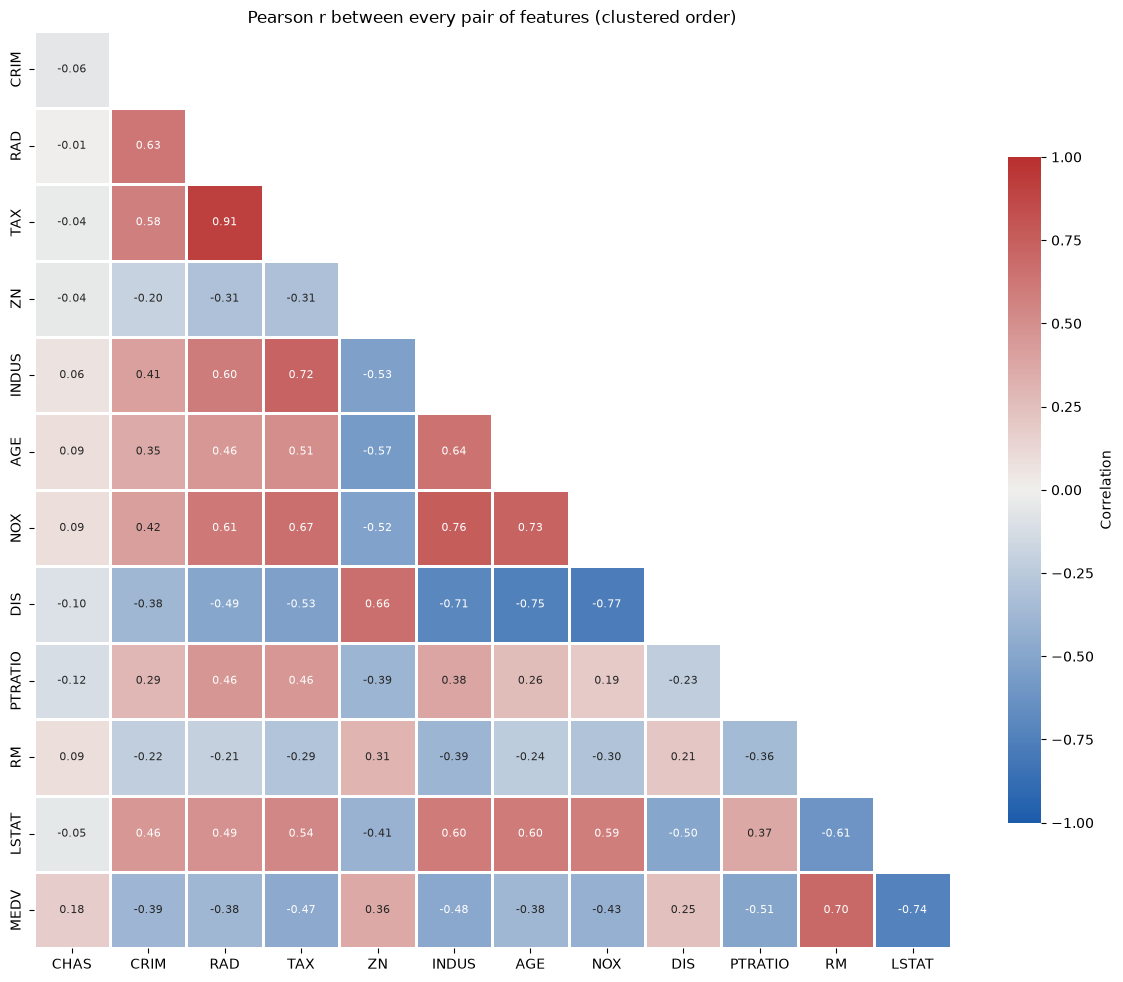

In [231]:
pearson = df[FEATURES].corr()
spearman = df[FEATURES].corr(method="spearman")

# Average-linkage clustering on 1 - |r|: features with strong correlations of either sign are joined first
tree = linkage(squareform(1 - pearson.abs().values, checks=False), method="average")
heat_order = [FEATURES[i] for i in leaves_list(tree)]
print("Order:", ", ".join(heat_order))

# Cutting the tree where the average |r| inside a group falls below 0.5 gives the blocks visible in the heatmap
groups = pd.Series(fcluster(tree, t=0.5, criterion="distance"), index=FEATURES)
for g, members in groups.groupby(groups):
    cols = list(members.index)
    inside = pearson.loc[cols, cols].abs().values[np.triu_indices(len(cols), k=1)]
    print(f"Group {g}: {', '.join(cols)}" + (f"   (average |r| inside = {inside.mean():.3f})" if len(cols) > 1 else ""))

fig, ax = plt.subplots(figsize=(12, 10))
corr_heatmap(ax, pearson.loc[heat_order, heat_order], "Pearson r between every pair of features (clustered order)")
plt.tight_layout()
plt.show()

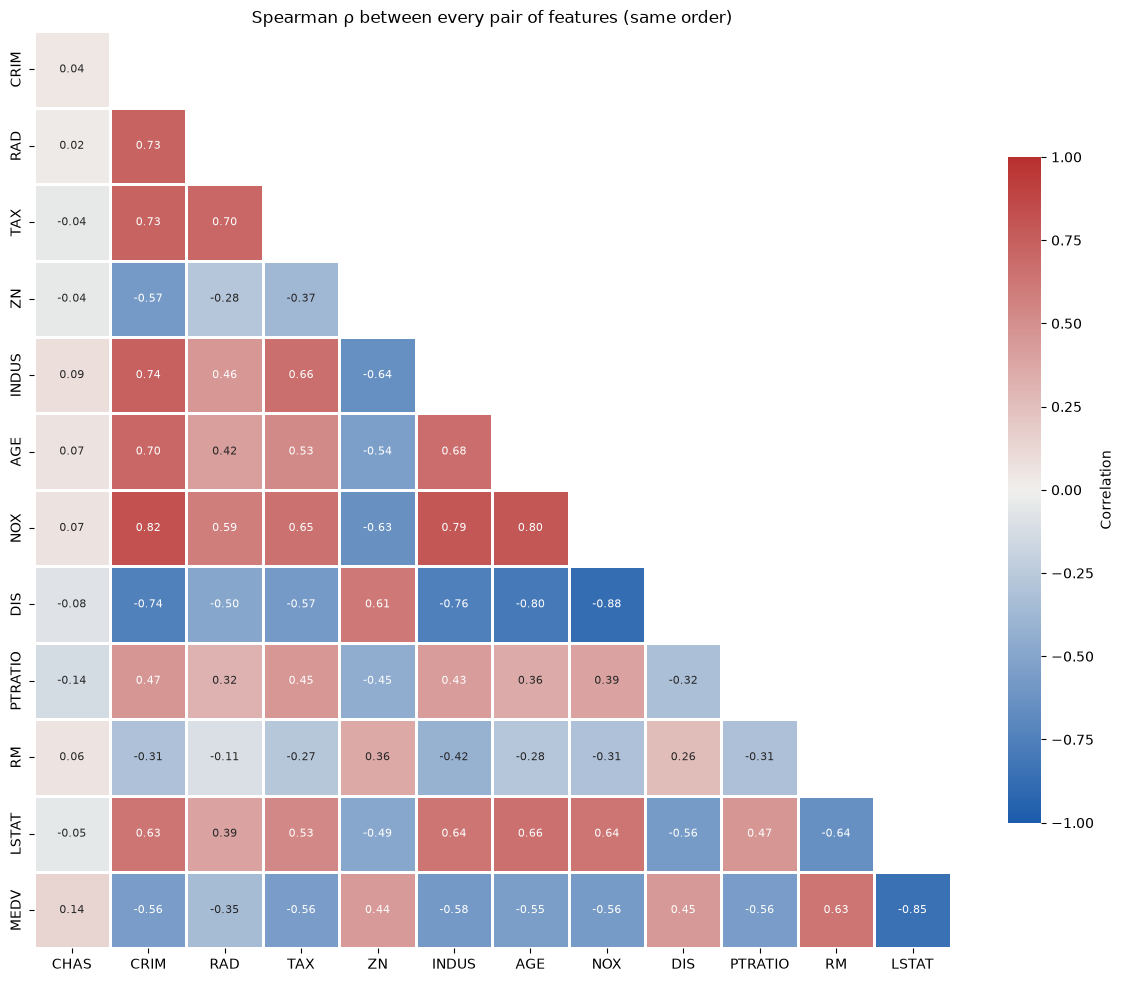

Largest |rho| - |r|:
 CRIM  NOX        0.400
      ZN         0.371
      DIS        0.365
      AGE        0.351
      INDUS      0.329
NOX   PTRATIO    0.202


In [135]:
fig, ax = plt.subplots(figsize=(12, 10))
corr_heatmap(ax, spearman.loc[heat_order, heat_order], "Spearman ρ between every pair of features (same order)")
plt.tight_layout()
plt.show()

# Where rank and straight-line correlation disagree most (the bivariate analysis traced most of this to CRIM's skew)
gap = (spearman.abs() - pearson.abs()).where(np.triu(np.ones_like(pearson, dtype=bool), k=1)).stack()
print("Largest |rho| - |r|:\n", gap.sort_values(ascending=False).head(6).round(3).to_string())

In [136]:
# The MEDV row of the Pearson heatmap, strongest first
medv_row = pearson["MEDV"].drop("MEDV").sort_values(key=abs, ascending=False)
print(medv_row.round(3).to_string())
print(f"\n|r| >= 0.5: {(medv_row.abs() >= 0.5).sum()} features   0.3 to 0.5: {medv_row.abs().between(0.3, 0.5).sum()}   "
      f"below 0.3: {(medv_row.abs() < 0.3).sum()}")
print(f"Negative: {(medv_row < 0).sum()}   positive: {(medv_row > 0).sum()}")

LSTAT     -0.738
RM         0.695
PTRATIO   -0.508
INDUS     -0.484
TAX       -0.469
NOX       -0.427
CRIM      -0.388
RAD       -0.382
AGE       -0.377
ZN         0.360
DIS        0.250
CHAS       0.175

|r| >= 0.5: 3 features   0.3 to 0.5: 7   below 0.3: 2
Negative: 8   positive: 4


#### **Observation J:**
- **Three blocks of related features,** found by the clustering and visible in the heatmap:
    - `CRIM`, `RAD` and `TAX` (average |r| = 0.706). These are the markers of the 132-tract town: `RAD`–`TAX` 0.91, `CRIM`–`RAD` 0.63, `CRIM`–`TAX` 0.58.
    - `ZN`, `INDUS`, `NOX`, `AGE` and `DIS` (average |r| = 0.665), a gradient from urban to suburban. `INDUS`, `NOX` and `AGE` rise together, while `DIS` and `ZN` fall. Every pair among `INDUS`, `NOX`, `AGE` and `DIS` has |r| between 0.64 and 0.77.
    - `RM`, `LSTAT` and `MEDV` (average |r| = 0.682).
    - `PTRATIO` and `CHAS` stand alone. `PTRATIO`'s largest |r| with anything is 0.51 (with `MEDV`), and `CHAS`'s is 0.18 (also with `MEDV`).

- **The first two blocks are tied to each other and to `LSTAT`.** For example, `TAX`–`INDUS` is 0.72, `TAX`–`NOX` 0.67 and `RAD`–`NOX` 0.61. `LSTAT` correlates between 0.41 and 0.60 in size with every member of both blocks.

- **Spearman shows the same blocks, but `CRIM` joins the urban block** once ranks are used. Its ρ is 0.82 with `NOX`, -0.74 with `DIS`, 0.74 with `INDUS` and 0.70 with `AGE`, against Pearson r of 0.42, -0.38, 0.41 and 0.35. The five largest gaps between ρ and r are all `CRIM` pairs.

- **The `MEDV` row:** 8 features correlate negatively and 4 positively. Three have |r| ≥ 0.5 (`LSTAT`, `RM`, `PTRATIO`), seven fall between 0.3 and 0.5, and two are below 0.3 (`DIS` 0.25, `CHAS` 0.18).

### Multivariate - correlation with `MEDV` once other features are held fixed
A feature can correlate with `MEDV` only because it moves with another feature that drives `MEDV`. Partial correlation removes that overlap. It correlates what is left of the feature and of `MEDV` after both have had the straight-line effect of the other features taken out. Three levels of control are shown: none, `LSTAT` and `RM` (the two strongest single predictors), and all 11 other features.

In [137]:
rows = []
for col in PREDICTORS:
    others = [c for c in PREDICTORS if c != col]
    top_two = [c for c in ["LSTAT", "RM"] if c != col]   # for LSTAT and RM themselves, only the other one is held
    rows.append({"feature": col,
                 "r (nothing held)": df[col].corr(df["MEDV"]),
                 "LSTAT and RM held": partial_corr(col, "MEDV", top_two),
                 "all other 11 held": partial_corr(col, "MEDV", others)})
partial_table = pd.DataFrame(rows).set_index("feature")
partial_table["shrinks to |r| < 0.05"] = partial_table["all other 11 held"].abs() < 0.05
partial_table["sign flips"] = ((np.sign(partial_table["r (nothing held)"]) != np.sign(partial_table["all other 11 held"]))
                               & ~partial_table["shrinks to |r| < 0.05"])
partial_table.sort_values("all other 11 held", key=abs, ascending=False).round(3)

,r (nothing held),LSTAT and RM held,all other 11 held,shrinks to |r| < 0.05,sign flips
feature,,,,,
LSTAT,-0.738,-0.548,-0.441,False,False
RM,0.695,0.455,0.365,False,False
DIS,0.250,-0.151,-0.316,False,True
PTRATIO,-0.508,-0.333,-0.304,False,False
NOX,-0.427,-0.031,-0.214,False,False
RAD,-0.382,-0.108,0.191,False,True
CRIM,-0.388,-0.142,-0.163,False,False
ZN,0.360,0.061,0.151,False,False
TAX,-0.469,-0.166,-0.149,False,False


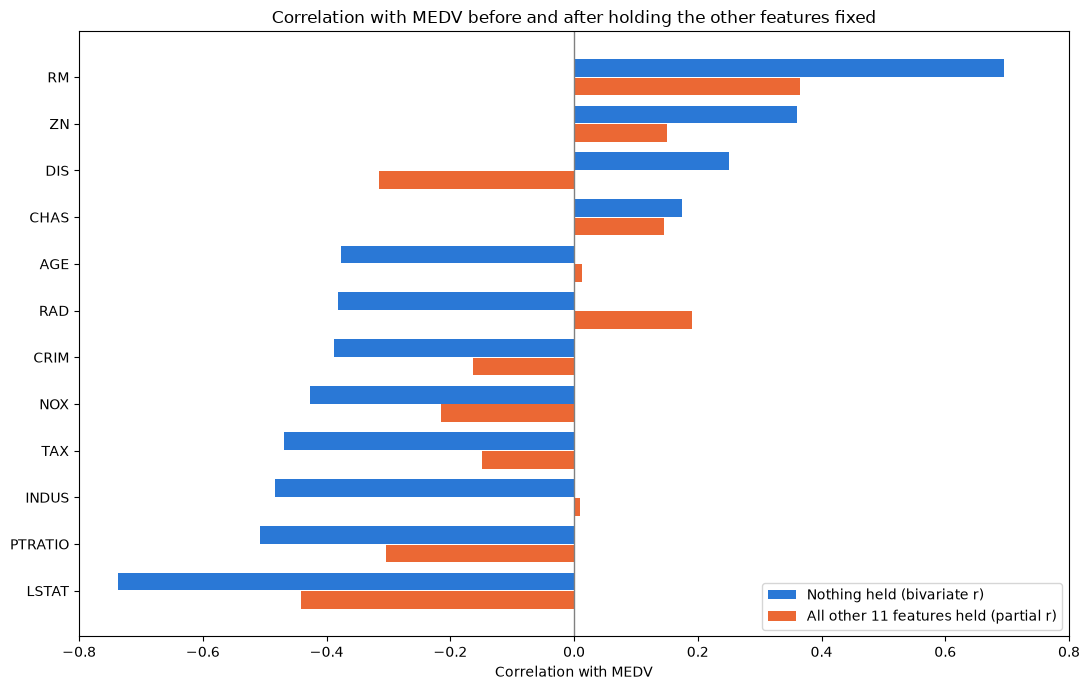

In [138]:
plot = partial_table.sort_values("r (nothing held)")
y = np.arange(len(plot))

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(y + 0.2, plot["r (nothing held)"], height=0.38, color=POINT_COLOUR, label="Nothing held (bivariate r)")
ax.barh(y - 0.2, plot["all other 11 held"], height=0.38, color=LINE_COLOUR, label="All other 11 features held (partial r)")
ax.set_yticks(y, plot.index)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlim(-0.8, 0.8)
ax.set_xlabel("Correlation with MEDV")
ax.set_title("Correlation with MEDV before and after holding the other features fixed")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### **Observation K:**
- **Remain the strongest:** `LSTAT` (-0.738 to -0.441), `RM` (0.695 to 0.365) and `PTRATIO` (-0.508 to -0.304) stay clearly related to `MEDV` with everything else held. `CHAS` barely changes (0.175 to 0.145), and rises to 0.188 when only `LSTAT` and `RM` are held.

- **Vanish:** `INDUS` (-0.484 to +0.010) and `AGE` (-0.377 to +0.012). Holding only `LSTAT` and `RM` already brings them to -0.063 and +0.036. Their simple correlations with `MEDV` are carried by other features.

- **Flip:** `DIS` goes from +0.250 to -0.316, and `RAD` from -0.382 to +0.191. Both are examined in the added-variable section below.

- **Shrink by about half or more:** `NOX` (-0.427 to -0.214), `TAX` (-0.469 to -0.149), `CRIM` (-0.388 to -0.163) and `ZN` (0.360 to 0.151). `NOX` drops to -0.031 when only `LSTAT` and `RM` are held, then returns when everything is held.

- **Implication:** ranking features by their simple correlation overstates `INDUS`, `AGE` and `TAX`, and gets the direction of `DIS` wrong.

#### **Answer 2:**

- **What the heatmap shows:** the features fall into three related blocks:
    - the 132-tract town's markers (`CRIM`, `RAD`, `TAX`)
    - an urban-to-suburban gradient (`ZN`, `INDUS`, `NOX`, `AGE`, `DIS`)
    - housing and status (`RM`, `LSTAT`, `MEDV`)

  `PTRATIO` and `CHAS` sit largely on their own. The first two blocks are tied to each other and to `LSTAT`, so many features carry overlapping information. Eight pairs reach |r| ≥ 0.7, and the multicollinearity section below measures the overlap.

- **Is there correlation between the dependent and independent variables?** Yes. Every one of the 12 features correlates with `MEDV` at the 5% level, since the smallest |r| (`CHAS`, 0.175) is well above the 0.087 needed. The strongest are `LSTAT` (-0.738), `RM` (0.695) and `PTRATIO` (-0.508). Eight of the twelve are negative.

- **But the heatmap overstates several of them.** With the other features held fixed:
    - `INDUS` and `AGE` drop to about zero.
    - `DIS` and `RAD` change sign.
    - `NOX`, `TAX`, `CRIM` and `ZN` shrink by about half or more.
    - Only `LSTAT`, `RM` and `PTRATIO` remain clearly related, with `CHAS` close to its original small value.

  The heatmap also measures straight-line association only, and the bivariate analysis showed that several of these relationships are curved.

### Multivariate - groups of related features and multicollinearity
The heatmap shows one large block of related features. This measures how much information the features share: VIF for each feature against all the others, and principal components for the structure as a whole.

In [139]:
vif = pd.DataFrame({"VIF, all 12": vif_table(PREDICTORS),
                    "VIF without RAD": vif_table([c for c in PREDICTORS if c != "RAD"]),
                    "VIF without TAX": vif_table([c for c in PREDICTORS if c != "TAX"])})
vif["share explained by the others (R²)"] = 1 - 1 / vif["VIF, all 12"]
vif.sort_values("VIF, all 12", ascending=False).round(3)

,"VIF, all 12",VIF without RAD,VIF without TAX,share explained by the others (R²)
TAX,9.002,3.352,NaN,0.889
RAD,7.445,NaN,2.772,0.866
NOX,4.369,4.273,4.343,0.771
INDUS,3.987,3.682,3.218,0.749
DIS,3.954,3.953,3.952,0.747
AGE,3.088,3.068,3.086,0.676
LSTAT,2.871,2.864,2.870,0.652
ZN,2.298,2.272,2.184,0.565
RM,1.913,1.859,1.903,0.477
PTRATIO,1.797,1.734,1.787,0.444


In [140]:
# Principal components of the 12 standardised features (MEDV left out)
scaled = StandardScaler().fit_transform(df[PREDICTORS])
pca = PCA().fit(scaled)
scores = pca.transform(scaled)
# A component's sign is arbitrary. PC1 is flipped if needed so that INDUS loads positively, so higher PC1 means more urban-industrial
flip = -1 if pca.components_[0, PREDICTORS.index("INDUS")] < 0 else 1
pc1 = pd.Series(scores[:, 0] * flip, index=df.index, name="PC1")

explained = pd.DataFrame({
    "share of variance": pca.explained_variance_ratio_,
    "cumulative": pca.explained_variance_ratio_.cumsum(),
    "r with MEDV": [np.corrcoef(scores[:, i], df["MEDV"])[0, 1] * (flip if i == 0 else 1) for i in range(len(PREDICTORS))],
}, index=[f"PC{i + 1}" for i in range(len(PREDICTORS))])
print(explained.round(3).to_string())

loadings = pd.Series(pca.components_[0] * flip, index=PREDICTORS).sort_values()
print("\nPC1 loadings:\n", loadings.round(3).to_string())

      share of variance  cumulative  r with MEDV
PC1               0.492       0.492       -0.608
PC2               0.117       0.609        0.368
PC3               0.098       0.707        0.369
PC4               0.071       0.779       -0.178
PC5               0.067       0.845        0.131
PC6               0.045       0.890       -0.015
PC7               0.033       0.923       -0.072
PC8               0.023       0.946        0.019
PC9               0.019       0.965       -0.075
PC10              0.016       0.981       -0.060
PC11              0.014       0.995       -0.144
PC12              0.005       1.000       -0.092

PC1 loadings:
 DIS       -0.331
ZN        -0.266
RM        -0.196
CHAS       0.008
PTRATIO    0.211
CRIM       0.251
LSTAT      0.315
RAD        0.322
AGE        0.323
TAX        0.342
NOX        0.350
INDUS      0.355


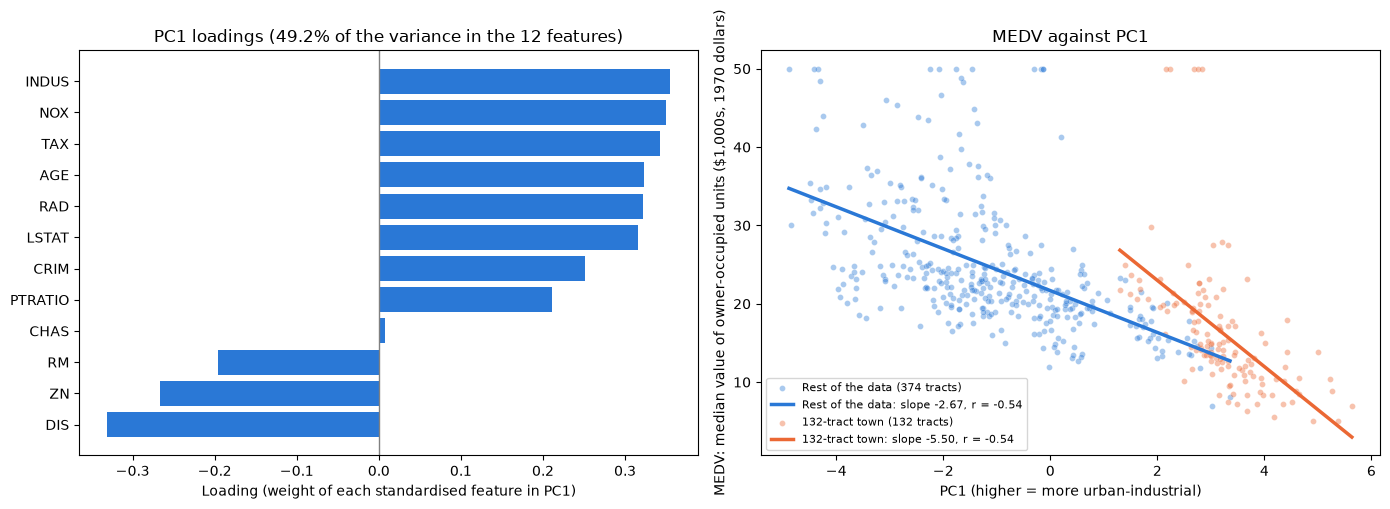

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(loadings.index, loadings.values, color=POINT_COLOUR)
axes[0].axvline(0, color="grey", linewidth=1)
axes[0].set_title(f"PC1 loadings ({explained.loc['PC1', 'share of variance']:.1%} of the variance in the 12 features)")
axes[0].set_xlabel("Loading (weight of each standardised feature in PC1)")

group_scatter(axes[1], pc1, df["MEDV"], town_groups)
axes[1].set_title("MEDV against PC1")
axes[1].set_xlabel("PC1 (higher = more urban-industrial)")
plt.tight_layout()
plt.show()

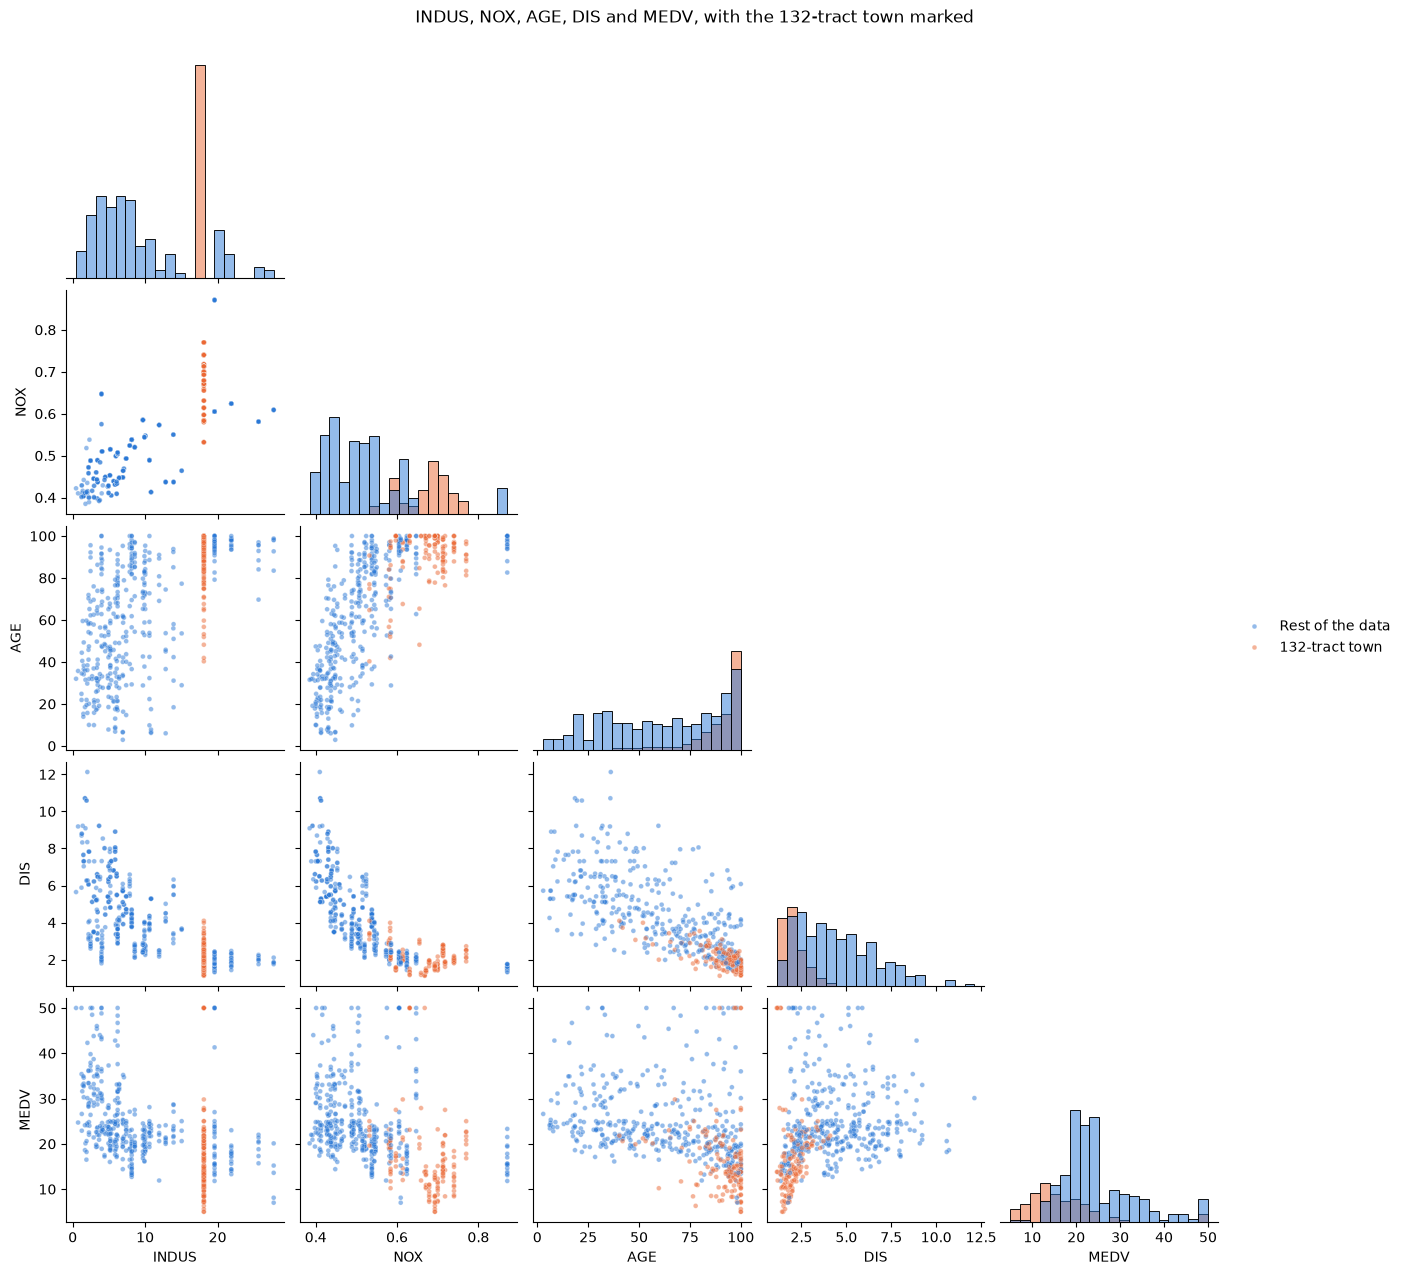

In [142]:
# The connected group named by the bivariate analysis, plus MEDV, with the 132-tract town marked
grid = sns.pairplot(df.assign(town=town_groups), vars=["INDUS", "NOX", "AGE", "DIS", "MEDV"], hue="town",
                    palette=GROUP_COLOURS, corner=True, diag_kind="hist", plot_kws={"s": 12, "alpha": 0.5},
                    diag_kws={"bins": 20})
grid.figure.suptitle("INDUS, NOX, AGE, DIS and MEDV, with the 132-tract town marked", y=1.02)
grid.legend.set_title("")
plt.show()

#### Observations from multivariate analysis of feature groups and multicollinearity

- **`TAX` and `RAD` largely duplicate each other.** They have the highest VIFs, 9.00 and 7.45: the other features predict 89% of `TAX` and 87% of `RAD`. With `RAD` removed, `TAX`'s VIF falls to 3.35, and with `TAX` removed, `RAD`'s falls to 2.77.

- **The urban block comes next:** `NOX` 4.37, `INDUS` 3.99, `DIS` 3.95 and `AGE` 3.09, meaning 68% to 77% of each is predicted by the others. None reaches 5. `CHAS` (1.07) is almost independent of everything else.

- **One main dimension:** the first principal component (PC1) holds 49.2% of the variance in the 12 features.
    - It loads positively on `INDUS`, `NOX`, `TAX`, `AGE`, `RAD` and `LSTAT` (0.315 to 0.355), and less on `CRIM` (0.251) and `PTRATIO` (0.211).
    - It loads negatively on `DIS` (-0.331), `ZN` (-0.266) and `RM` (-0.196), and close to zero on `CHAS` (0.008).
    - It is an urban-industrial against suburban axis that combines both blocks and `LSTAT`. Three components together hold 70.7% of the variance.

- **PC1 and `MEDV`:** r = -0.608, the strongest of any component (the next two are 0.368 and 0.369). The 132-tract town sits at the urban end of PC1. Within each group, `MEDV` falls with PC1 at the same r (-0.54), but the town's line is steeper (slope -5.50 against -2.67).

- **The pairplot:** the town occupies one corner of every panel. It has a single `INDUS` value (18.10), `NOX` between about 0.53 and 0.77, `AGE` mostly near 100, and `DIS` below about 4. In the `NOX`–`DIS` panel, the town continues the same curve as the rest rather than forming a separate one.

### Multivariate - the 132-tract town
The bivariate analysis showed that `RAD` = 24, `TAX` = 666 and `INDUS` = 18.10 mark the same 132 tracts. This checks whether they are a single town, how they differ on every feature, and whether relationships with `MEDV` hold inside and outside them.

In [143]:
# Which town-level markers pick out the same tracts?
markers = {"RAD = 24": df["RAD"] == 24, "TAX = 666": df["TAX"] == 666, "INDUS = 18.10": df["INDUS"] == 18.10,
           "PTRATIO = 20.2": df["PTRATIO"] == 20.2, "ZN = 0": df["ZN"] == 0}
print(pd.DataFrame({name: {"tracts": m.sum(), "inside the 132": (m & BIG_TOWN).sum(), "outside": (m & ~BIG_TOWN).sum()}
                    for name, m in markers.items()}).T.to_string())

# The blocks from the data overview: a run of identical INDUS values down the file, one block per inferred town
town = (df["INDUS"] != df["INDUS"].shift()).cumsum()
print(f"\nBlocks holding the 132 tracts: {town[BIG_TOWN].nunique()} "
      f"(that block has {(town == town[BIG_TOWN].iloc[0]).sum()} tracts, rows {df.index[BIG_TOWN].min()} to {df.index[BIG_TOWN].max()})")

print("\nThe PTRATIO = 20.2 tracts outside it:")
print(df.loc[(df["PTRATIO"] == 20.2) & ~BIG_TOWN, ["INDUS", "RAD", "TAX", "PTRATIO", "MEDV"]].to_string())

# The 13 tracts far from the RM line in the bivariate analysis
rm_fit = sm.OLS(df["MEDV"], sm.add_constant(df["RM"])).fit()
rm_far = rm_fit.resid.abs() > 2.5 * rm_fit.resid.std()
print(f"\nTracts far from the RM line: {rm_far.sum()}, of which inside the 132-tract town: {(rm_far & BIG_TOWN).sum()}")
print(f"Capped tracts (MEDV = 50) inside the town: {(CAPPED & BIG_TOWN).sum()} (rows {list(df.index[CAPPED & BIG_TOWN])})")

                tracts  inside the 132  outside
RAD = 24           132             132        0
TAX = 666          132             132        0
INDUS = 18.10      132             132        0
PTRATIO = 20.2     140             132        8
ZN = 0             372             132      240

Blocks holding the 132 tracts: 1 (that block has 132 tracts, rows 356 to 487)

The PTRATIO = 20.2 tracts outside it:
     INDUS  RAD  TAX  PTRATIO  MEDV
333   5.19    5  224     20.2  22.2
334   5.19    5  224     20.2  20.7
335   5.19    5  224     20.2  21.1
336   5.19    5  224     20.2  19.5
337   5.19    5  224     20.2  18.5
338   5.19    5  224     20.2  20.6
339   5.19    5  224     20.2  19.0
340   5.19    5  224     20.2  18.7

Tracts far from the RM line: 13, of which inside the 132-tract town: 13
Capped tracts (MEDV = 50) inside the town: 5 (rows [368, 369, 370, 371, 372])


         median inside (132)  median outside (374)  difference (SDs)
DIS                    1.943                 4.017            -0.985
MEDV                  14.400                22.650            -0.897
RM                     6.176                 6.231            -0.078
ZN                     0.000                 0.000             0.000
CHAS                   0.000                 0.000             0.000
PTRATIO               20.200                18.000             1.016
CRIM                   9.085                 0.132             1.041
AGE                   94.400                62.900             1.119
LSTAT                 17.910                 9.440             1.186
INDUS                 18.100                 6.910             1.631
NOX                    0.693                 0.493             1.726
TAX                  666.000               305.000             2.142
RAD                   24.000                 4.000             2.297


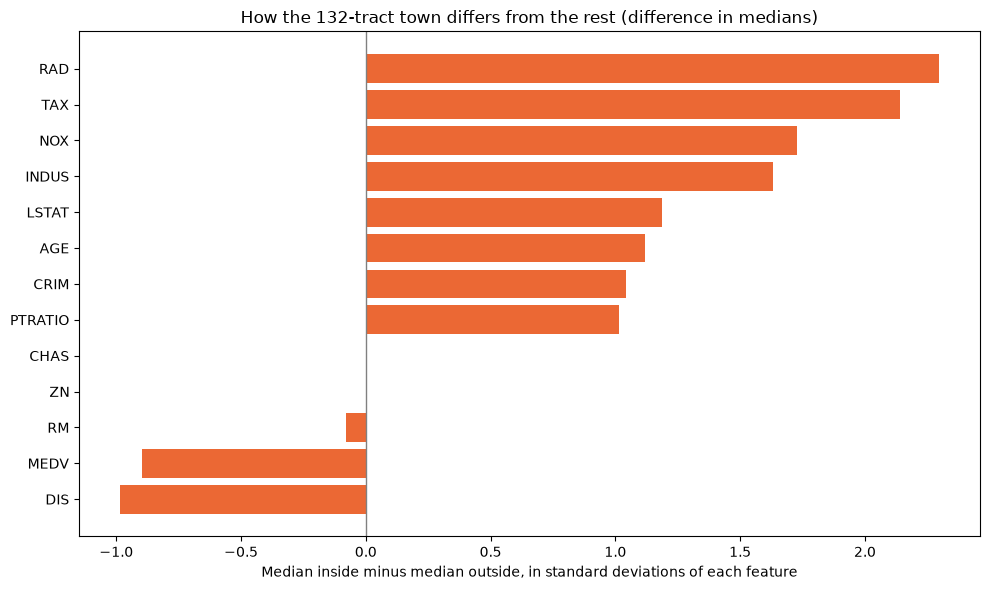

In [144]:
profile = pd.DataFrame({"median inside (132)": df.loc[BIG_TOWN, FEATURES].median(),
                        "median outside (374)": df.loc[~BIG_TOWN, FEATURES].median()})
# Difference in medians in units of each feature's overall standard deviation, so features on different scales compare
profile["difference (SDs)"] = (profile["median inside (132)"] - profile["median outside (374)"]) / df[FEATURES].std()
profile = profile.sort_values("difference (SDs)")
print(profile.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(profile.index, profile["difference (SDs)"], color=LINE_COLOUR)
ax.axvline(0, color="grey", linewidth=1)
ax.set_title("How the 132-tract town differs from the rest (difference in medians)")
ax.set_xlabel("Median inside minus median outside, in standard deviations of each feature")
plt.tight_layout()
plt.show()

In [145]:
# Tract-level features only: town-level features take one value inside the town, so they have no correlation there
tract_level = ["CRIM", "NOX", "RM", "AGE", "DIS", "LSTAT", "CHAS"]
inside, outside = df[BIG_TOWN], df[~BIG_TOWN]
within = pd.DataFrame({
    "r, all tracts": [df[c].corr(df["MEDV"]) for c in tract_level],
    "r, inside (132)": [inside[c].corr(inside["MEDV"]) for c in tract_level],
    "r, outside (374)": [outside[c].corr(outside["MEDV"]) for c in tract_level],
    "rho, inside": [inside[c].corr(inside["MEDV"], method="spearman") for c in tract_level],
    "rho, outside": [outside[c].corr(outside["MEDV"], method="spearman") for c in tract_level],
}, index=tract_level)
print(within.round(3).to_string())

usual = inside[~rm_far[BIG_TOWN] & (inside["MEDV"] < 50)]
print(f"\nRM vs MEDV inside the town without its far-from-line and capped tracts ({len(usual)} tracts): "
      f"r = {usual['RM'].corr(usual['MEDV']):+.3f}")
print(f"RM vs LSTAT: inside r = {inside['RM'].corr(inside['LSTAT']):+.3f}, outside r = {outside['RM'].corr(outside['LSTAT']):+.3f}")
for name, part in [("RM < 6.5", outside[outside["RM"] < 6.5]), ("RM >= 6.5", outside[outside["RM"] >= 6.5])]:
    print(f"Outside, {name}: {len(part)} tracts, MEDV rises by {np.polyfit(part['RM'], part['MEDV'], 1)[0]:.2f} per extra room")

       r, all tracts  r, inside (132)  r, outside (374)  rho, inside  rho, outside
CRIM          -0.388           -0.354            -0.172       -0.642        -0.321
NOX           -0.427           -0.257            -0.263       -0.211        -0.383
RM             0.695            0.120             0.891        0.199         0.825
AGE           -0.377           -0.156            -0.268       -0.307        -0.426
DIS            0.250            0.106             0.072        0.374         0.192
LSTAT         -0.738           -0.698            -0.673       -0.788        -0.809
CHAS           0.175            0.447             0.095        0.308         0.077

RM vs MEDV inside the town without its far-from-line and capped tracts (119 tracts): r = +0.327
RM vs LSTAT: inside r = -0.387, outside r = -0.686
Outside, RM < 6.5: 246 tracts, MEDV rises by 6.24 per extra room
Outside, RM >= 6.5: 128 tracts, MEDV rises by 13.35 per extra room


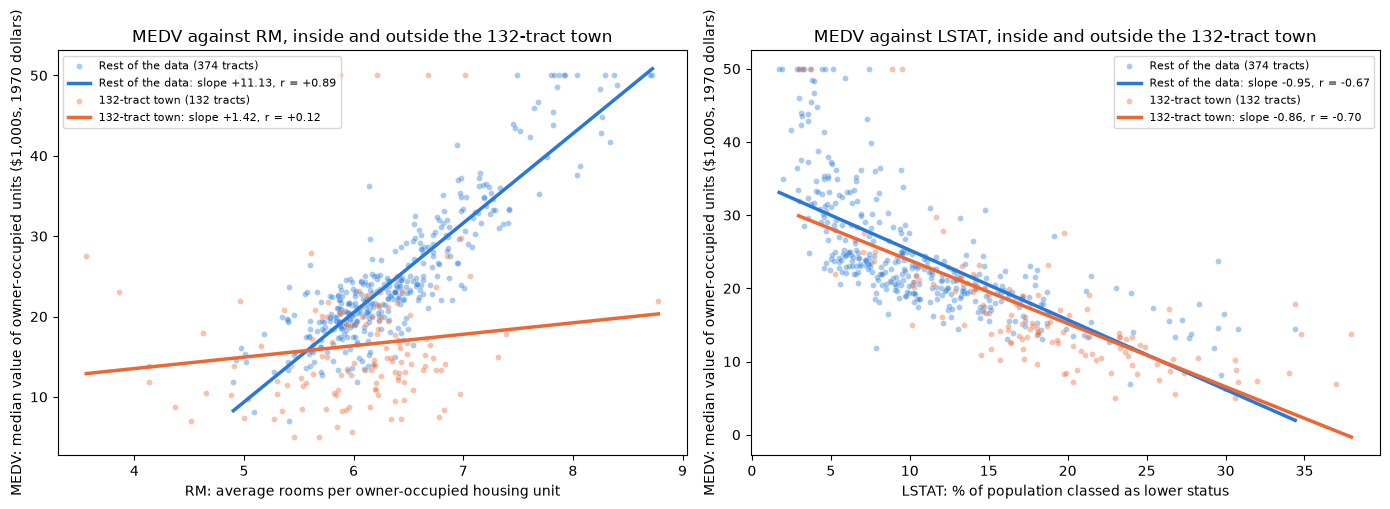

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
group_scatter(axes[0], df["RM"], df["MEDV"], town_groups)
axes[0].set_title("MEDV against RM, inside and outside the 132-tract town")
group_scatter(axes[1], df["LSTAT"], df["MEDV"], town_groups)
axes[1].set_title("MEDV against LSTAT, inside and outside the 132-tract town")
plt.tight_layout()
plt.show()

In [147]:
# One row per inferred town, with the town's median MEDV, so the 132-tract town counts once instead of 132 times
towns = df.groupby(town).agg(tracts=("MEDV", "size"), MEDV=("MEDV", "median"), ZN=("ZN", "first"), INDUS=("INDUS", "first"),
                             RAD=("RAD", "first"), TAX=("TAX", "first"), PTRATIO=("PTRATIO", "first"))
small_towns = towns[towns["tracts"] < 132]
print(f"{len(towns)} towns; tracts per town: median {towns['tracts'].median():.0f}, largest {towns['tracts'].max()}")
print(pd.DataFrame({
    "r over tracts (506)": [df[c].corr(df["MEDV"]) for c in TOWN_LEVEL],
    f"r over towns ({len(towns)})": [towns[c].corr(towns["MEDV"]) for c in TOWN_LEVEL],
    f"r over towns without the big one ({len(small_towns)})": [small_towns[c].corr(small_towns["MEDV"]) for c in TOWN_LEVEL],
}, index=TOWN_LEVEL).round(3).to_string())

78 towns; tracts per town: median 3, largest 132
         r over tracts (506)  r over towns (78)  r over towns without the big one (77)
ZN                     0.360              0.480                                  0.471
INDUS                 -0.484             -0.480                                 -0.458
RAD                   -0.382             -0.181                                 -0.077
TAX                   -0.469             -0.496                                 -0.477
PTRATIO               -0.508             -0.551                                 -0.540


#### Observations from multivariate analysis of the 132-tract town

- **It is one town.** `RAD` = 24, `TAX` = 666 and `INDUS` = 18.10 each pick out exactly the same 132 tracts. They form a single block of consecutive rows (356 to 487), the largest of the 78 inferred towns, and all have `ZN` = 0.

- **`PTRATIO` = 20.2 (carried from the bivariate analysis):** 132 of the 140 tracts at 20.2 are this town. The other 8 (rows 333 to 340, a town with `INDUS` 5.19) have `MEDV` between 18.5 and 22.2, close to the overall median of 21.2. The low `MEDV` at 20.2 belongs to the town, not to the ratio.

- **The `RM` outliers (carried from the bivariate analysis):** all 13 tracts far from the `RM` line are inside this town, and so are 5 of the 16 capped tracts (rows 368 to 372).

- **How it differs:**
    - The largest differences are in `RAD` (+2.30 standard deviations), `TAX` (+2.14), `NOX` (+1.73), `INDUS` (+1.63), `LSTAT` (+1.19), `AGE` (+1.12), `CRIM` (+1.04) and `PTRATIO` (+1.02).
    - It is closer to the employment centres (`DIS` -0.99).
    - Its median `MEDV` is 14.4 against 22.65 (-0.90).
    - `RM` hardly differs (6.176 against 6.231, -0.08).

- **`RM` barely matters inside the town.**
    - r = 0.120 inside, against 0.891 outside. Without the town's far-from-line and capped tracts, r inside is still only 0.327.
    - Outside, the convex shape remains: 6.24 per room below 6.5 rooms, 13.35 above.
    - The bivariate r of 0.695 is therefore a blend of a strong relationship in 374 tracts and a weak one in 132.

- **`LSTAT` works the same in both:** r = -0.698 inside and -0.673 outside, with slopes of -0.86 and -0.95.

- **Other features inside the town:** crime matters more inside (ρ = -0.642, against -0.321 outside), and so does `CHAS` (r = 0.447, against 0.095).

- **Counting each town once:**
    - `RAD`'s correlation with `MEDV` falls from -0.382 to -0.181, and to -0.077 without the big town.
    - The other town-level features hold or strengthen: `ZN` 0.360 to 0.480, `PTRATIO` -0.508 to -0.551, `TAX` -0.469 to -0.496, `INDUS` -0.484 to -0.480.
    - `RAD`'s correlation over tracts is the big town counted 132 times. The others reflect a pattern across towns.

### Multivariate - `RM` and `LSTAT` together
The two strongest single predictors of `MEDV` are correlated with each other (r = -0.614). This checks how much of `MEDV` they explain together and separately, and whether the value of an extra room depends on `LSTAT`.

In [148]:
both = df.assign(**{"RM x LSTAT": df["RM"] * df["LSTAT"]})
fits = {"RM alone": ["RM"], "LSTAT alone": ["LSTAT"], "RM and LSTAT": ["RM", "LSTAT"],
        "RM, LSTAT and RM x LSTAT": ["RM", "LSTAT", "RM x LSTAT"]}
r2 = {name: r_squared(cols, both) for name, cols in fits.items()}
for name, value in r2.items():
    print(f"R², {name:<26} {value:.3f}")

shared = r2["RM alone"] + r2["LSTAT alone"] - r2["RM and LSTAT"]
print(f"\nShared by both (counted in each alone): {shared:.3f}")
print(f"Added by RM once LSTAT is in:  {r2['RM and LSTAT'] - r2['LSTAT alone']:.3f}")
print(f"Added by LSTAT once RM is in:  {r2['RM and LSTAT'] - r2['RM alone']:.3f}")
print(f"Added by the interaction term: {r2['RM, LSTAT and RM x LSTAT'] - r2['RM and LSTAT']:.3f}")

R², RM alone                   0.484
R², LSTAT alone                0.544
R², RM and LSTAT               0.639
R², RM, LSTAT and RM x LSTAT   0.740

Shared by both (counted in each alone): 0.389
Added by RM once LSTAT is in:  0.094
Added by LSTAT once RM is in:  0.155
Added by the interaction term: 0.102


Tracts in each cell:
 LSTAT       1.73 to 8.26  8.43 to 14.7  14.7 to 38
RM                                                
below 5.5              2             7          33
5.5 to 6               6            60          65
6 to 6.5              47            80          54
6.5 to 7              56            17          15
7 and over            58             4           2


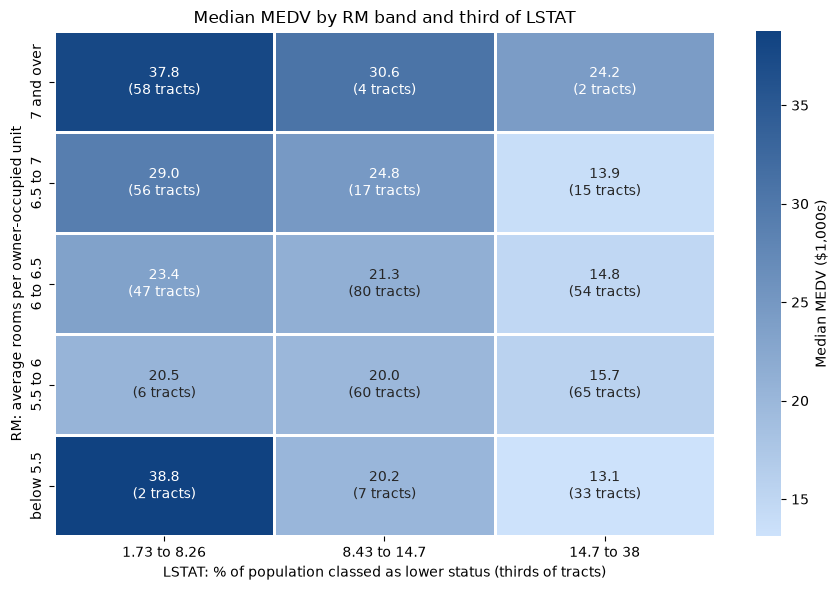

In [149]:
lstat_thirds = equal_bins(df["LSTAT"], 3)
rm_bands = pd.cut(df["RM"], bins=[0, 5.5, 6, 6.5, 7, 10], right=False,
                  labels=["below 5.5", "5.5 to 6", "6 to 6.5", "6.5 to 7", "7 and over"])
medians = df.pivot_table(index=rm_bands, columns=lstat_thirds, values="MEDV", aggfunc="median", observed=False)
counts = pd.crosstab(rm_bands, lstat_thirds)
print("Tracts in each cell:\n", counts.to_string())

fig, ax = plt.subplots(figsize=(9, 6))
labels = medians.round(1).astype(str) + "\n(" + counts.astype(str) + " tracts)"
sns.heatmap(medians, annot=labels, fmt="", cmap=VALUE_CMAP, linewidths=2, linecolor="white",
            cbar_kws={"label": "Median MEDV ($1,000s)"}, ax=ax)
ax.invert_yaxis()   # more rooms higher up
ax.set_title("Median MEDV by RM band and third of LSTAT")
ax.set_xlabel("LSTAT: % of population classed as lower status (thirds of tracts)")
ax.set_ylabel("RM: average rooms per owner-occupied unit")
plt.tight_layout()
plt.show()

              tracts  RM >= 6.5  slope per room      r  slope below 6.5  slope at 6.5 and over
LSTAT third                                                                                   
1.73 to 8.26     169        114           9.203  0.727           -2.863                 10.944
8.43 to 14.7     168         21           2.925  0.263            1.452                  6.453
14.7 to 38       169         17           1.427  0.172            1.712                  9.259

Lowest third, RM < 6.5: 55 tracts, 2 of them far from the RM line; slope without those: 7.52


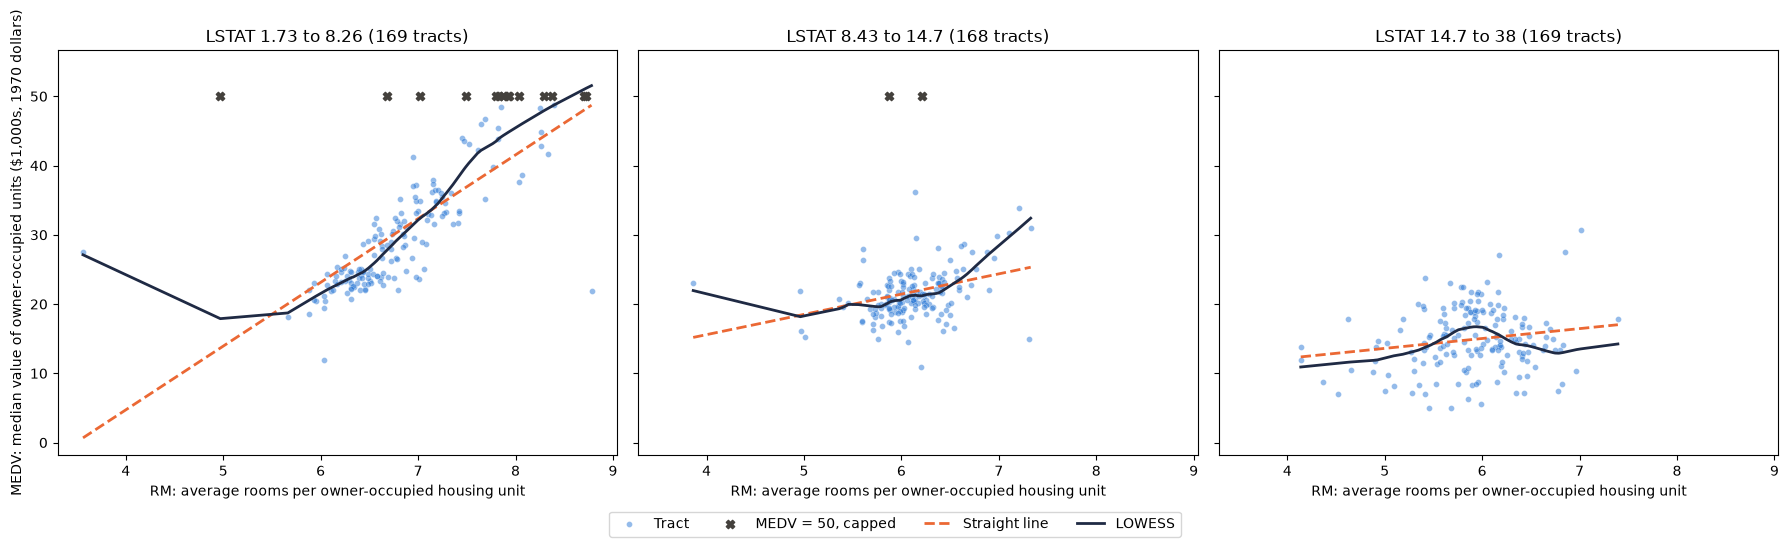

In [150]:
rows = []
for name in lstat_thirds.cat.categories:
    part = df[lstat_thirds == name]
    row = {"LSTAT third": name, "tracts": len(part), "RM >= 6.5": (part["RM"] >= 6.5).sum(),
           "slope per room": np.polyfit(part["RM"], part["MEDV"], 1)[0], "r": part["RM"].corr(part["MEDV"])}
    for label, piece in [("slope below 6.5", part[part["RM"] < 6.5]), ("slope at 6.5 and over", part[part["RM"] >= 6.5])]:
        row[label] = np.polyfit(piece["RM"], piece["MEDV"], 1)[0] if len(piece) >= 10 else np.nan
    rows.append(row)
print(pd.DataFrame(rows).set_index("LSTAT third").round(3).to_string())

first = lstat_thirds.cat.categories[0]
below = df[(lstat_thirds == first) & (df["RM"] < 6.5)]
print(f"\nLowest third, RM < 6.5: {len(below)} tracts, {(rm_far & (lstat_thirds == first) & (df['RM'] < 6.5)).sum()} of them far "
      f"from the RM line; slope without those: {np.polyfit(below.loc[~rm_far, 'RM'], below.loc[~rm_far, 'MEDV'], 1)[0]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, name in zip(axes, lstat_thirds.cat.categories):
    part = lstat_thirds == name
    scatter_fit(ax, df.loc[part, "RM"], df.loc[part, "MEDV"])
    ax.set_title(f"LSTAT {name} ({part.sum()} tracts)")
for ax in axes:
    ax.get_legend().remove()
for ax in axes[1:]:
    ax.set_ylabel("")
handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles, ["Tract", "MEDV = 50, capped", "Straight line", "LOWESS"], loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

#### Observations from multivariate analysis of `RM` and `LSTAT`

- **Overlap:** `RM` alone gives R² = 0.484, `LSTAT` alone 0.544, and both together 0.639. 0.389 is shared between them. `RM` adds 0.094 once `LSTAT` is in, and `LSTAT` adds 0.155 once `RM` is in.

- **Interaction:** an `RM` × `LSTAT` term adds 0.102 to R² (0.639 to 0.740), more than `RM` adds on top of `LSTAT`. The value of an extra room depends on `LSTAT`.

- **Shown directly:**
    - `MEDV` rises by 9.20 per room in the lowest `LSTAT` third (r = 0.727), by 2.93 in the middle third (r = 0.263) and by 1.43 in the highest (r = 0.172).
    - In the heatmap, the highest `LSTAT` third stays between 13.1 and 15.7 from below 5.5 rooms up to 7 rooms. The lowest third climbs from 20.5 (5.5 to 6 rooms) to 37.8 (7 and over).

- **Many rooms and low `LSTAT` go together.**
    - 58 of the 64 tracts with 7 rooms or more, and 114 of the 152 with 6.5 or more, are in the lowest `LSTAT` third. So the steep upper part of `RM` is mostly observed in low-`LSTAT` tracts (slope 10.94 above 6.5 rooms there).
    - Where the middle and highest thirds do have 6.5 rooms or more (21 and 17 tracts), the slope also steepens (6.45 and 9.26, against 1.45 and 1.71 below 6.5). The convex shape is not only a product of `LSTAT`.

- **The negative slope below 6.5 rooms in the lowest third (-2.86)** comes from 2 of its 55 tracts, both far from the `RM` line. Without them, the slope is +7.52.

- **Implication:** `RM` and `LSTAT` aren't independent effects. An `RM` × `LSTAT` interaction is worth testing in model building, alongside the bivariate suggestions (log `LSTAT`, a squared `RM`).

### Multivariate - relationships that change once other features are held fixed
The partial correlations showed `DIS` and `RAD` changing sign, `NOX` vanishing when only `LSTAT` is held and returning when all features are held, and `INDUS` and `AGE` vanishing. This traces each change to the features responsible, then shows the result as added-variable plots. Each plot shows what is left of `MEDV` after removing the other 11 features, against what is left of the feature after removing the same 11. The slope of that cloud is the feature's coefficient when all 12 are fitted together, and its correlation is the partial correlation.

In [151]:
# The partial correlation with MEDV as more features are held fixed
urban = ["INDUS", "NOX", "AGE", "DIS"]
steps = {"nothing": lambda c: [],
         "LSTAT": lambda c: ["LSTAT"],
         "LSTAT, RM": lambda c: ["LSTAT", "RM"],
         "the urban group": lambda c: [u for u in urban if u != c],
         "urban group, LSTAT, RM": lambda c: [u for u in urban if u != c] + ["LSTAT", "RM"],
         "all other 11": lambda c: [o for o in PREDICTORS if o != c]}
changes = pd.DataFrame({step: {c: partial_corr(c, "MEDV", controls(c)) for c in ["DIS", "NOX", "INDUS", "AGE", "RAD", "TAX", "CRIM"]}
                        for step, controls in steps.items()})
print("Partial r with MEDV, holding the listed features fixed (urban group = INDUS, NOX, AGE, DIS, minus the feature itself):")
print(changes.round(3).to_string())

# RAD and TAX are each other's closest partner (VIF), so each is also checked with the other left out of the controls
for c, partner in [("RAD", "TAX"), ("TAX", "RAD")]:
    print(f"\n{c}: all other 11 held = {changes.loc[c, 'all other 11']:+.3f}; "
          f"all except {partner} held = {partial_corr(c, 'MEDV', [o for o in PREDICTORS if o not in (c, partner)]):+.3f}")

# Why DIS flips: distant tracts differ on the features that hold MEDV down
print("\nCorrelation of DIS with:", ", ".join(f"{c} {df['DIS'].corr(df[c]):+.2f}" for c in ["NOX", "INDUS", "AGE", "LSTAT", "CRIM"]))

Partial r with MEDV, holding the listed features fixed (urban group = INDUS, NOX, AGE, DIS, minus the feature itself):
       nothing  LSTAT  LSTAT, RM  the urban group  urban group, LSTAT, RM  all other 11
DIS      0.250 -0.199     -0.151           -0.278                  -0.254        -0.316
NOX     -0.427  0.016     -0.031           -0.155                  -0.107        -0.214
INDUS   -0.484 -0.071     -0.063           -0.318                  -0.135         0.010
AGE     -0.377  0.125      0.036           -0.164                  -0.030         0.012
RAD     -0.382 -0.036     -0.108           -0.110                  -0.090         0.191
TAX     -0.469 -0.119     -0.166           -0.166                  -0.146        -0.149
CRIM    -0.388 -0.087     -0.142           -0.245                  -0.156        -0.163

RAD: all other 11 held = +0.191; all except TAX held = +0.122

TAX: all other 11 held = -0.149; all except RAD held = +0.007

Correlation of DIS with: NOX -0.77, INDUS -0.71, A

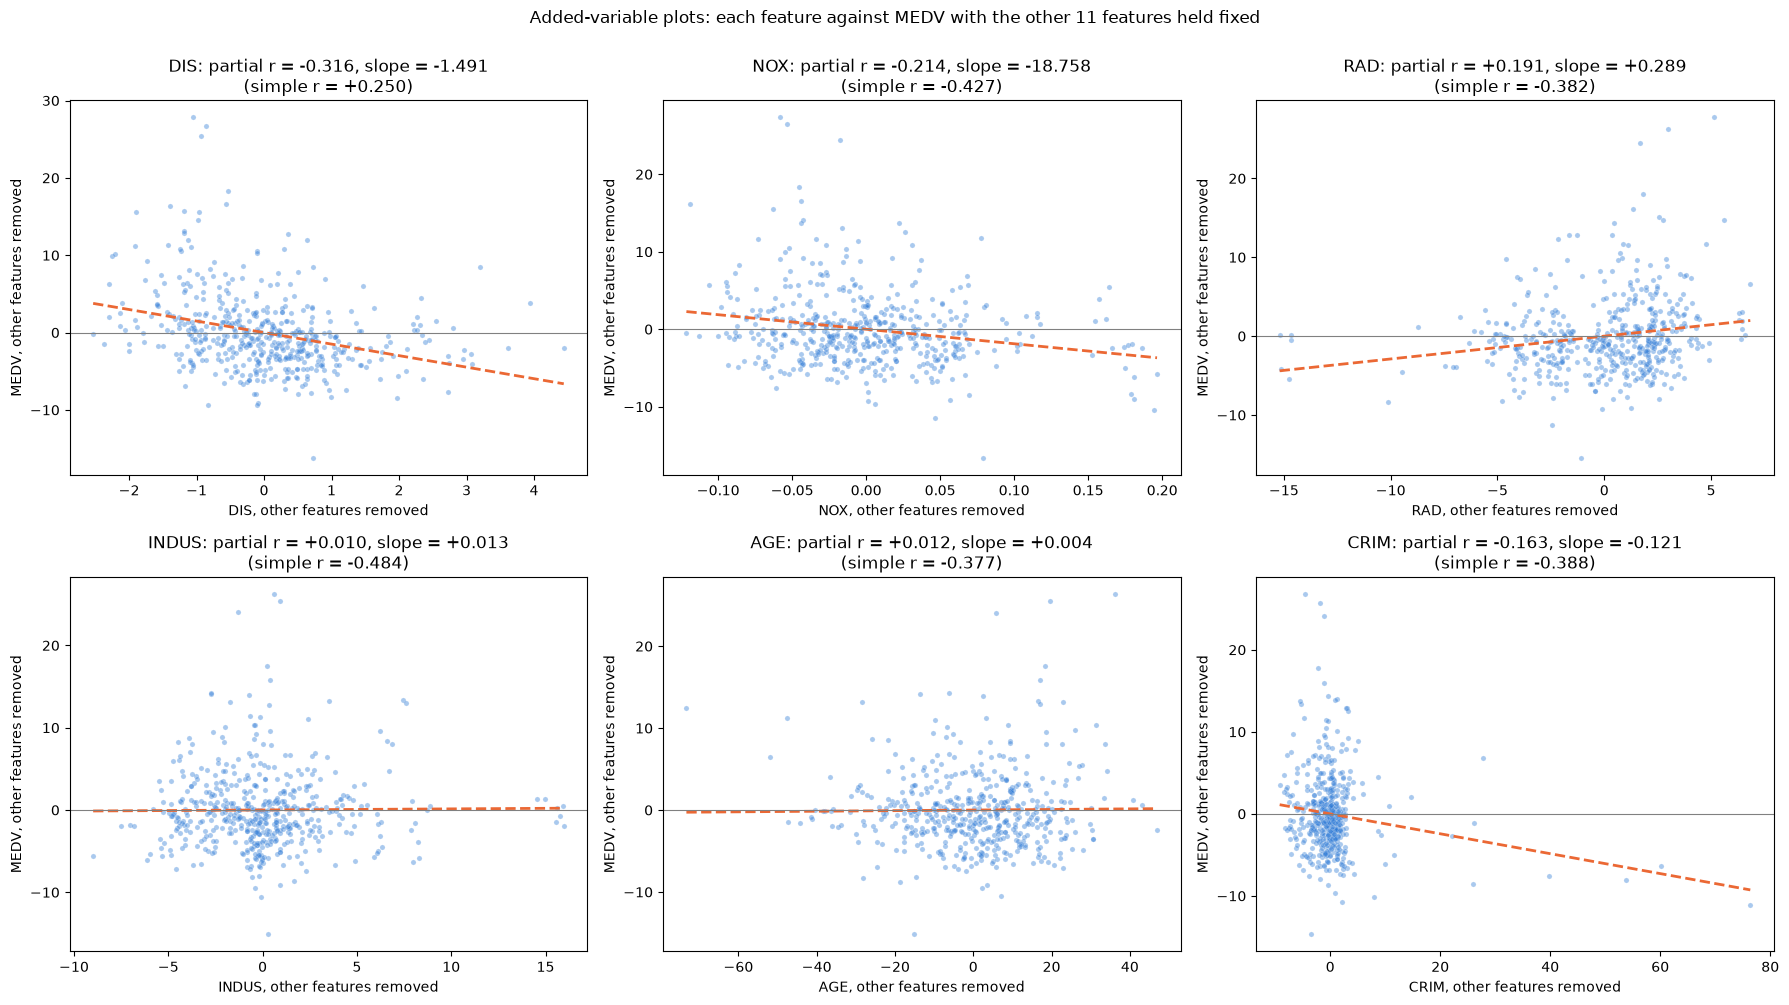

In [152]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, feature in zip(axes.flat, ["DIS", "NOX", "RAD", "INDUS", "AGE", "CRIM"]):
    added_variable(ax, feature, [c for c in PREDICTORS if c != feature])
fig.suptitle("Added-variable plots: each feature against MEDV with the other 11 features held fixed", y=1.0)
plt.tight_layout()
plt.show()

#### Observations from multivariate analysis of relationships that change

- **`DIS` flips because of the urban block.**
    - Its simple r of +0.250 reflects that distant tracts have less pollution, industry, old housing and low-status population. `DIS` correlates -0.77 with `NOX`, -0.71 with `INDUS`, -0.75 with `AGE` and -0.50 with `LSTAT`.
    - Holding only `NOX`, `INDUS` and `AGE` turns it to -0.278, and holding all 11 to -0.316.
    - With those fixed, tracts further from the centres are worth less (slope -1.49 per unit of `DIS`).

- **`RAD` flips, but the result is unstable.**
    - It goes from -0.382 to +0.191 with all 11 held, and to +0.122 when `TAX` is left out of the controls.
    - `TAX` goes from -0.149 to +0.007 when `RAD` is left out.
    - Each one's partial correlation depends on whether the other is held, so the sign of either can't be read on its own. This matches their VIFs (9.00 and 7.45).

- **`NOX` mostly duplicates `LSTAT`, with a smaller link of its own.**
    - Holding `LSTAT` alone removes its correlation (+0.016).
    - Holding the urban group restores part of it (-0.155), and holding all 11 restores more (-0.214).
    - Once distance and the other features are fixed, more pollution still goes with lower value.

- **`INDUS` and `AGE` add nothing once the others are held.**
    - Partial r is +0.010 and +0.012, and both added-variable plots are flat (slopes +0.013 and +0.004).
    - Holding the urban group leaves `INDUS` at -0.318, but holding `LSTAT` and `RM` takes it to -0.063. Its link to `MEDV` runs through `LSTAT` and `RM`, not through the other urban features.
    - `AGE` even turns positive (+0.125) when only `LSTAT` is held.

- **`CRIM`** keeps a negative partial r (-0.163). In its added-variable plot, most tracts sit near zero and a handful far to the right set the slope. That matches its extreme skew, and log(`CRIM`) remains the better form.

### Multivariate - `CHAS` once `LSTAT` and `RM` are held fixed
The bivariate river premium was small, and without the capped tracts it was no longer significant. River tracts also differ on other features, which could hide or exaggerate a premium.

In [153]:
river_profile = pd.DataFrame({"median, river (35)": df.loc[df["CHAS"] == 1, FEATURES].median(),
                              "median, other (471)": df.loc[df["CHAS"] == 0, FEATURES].median()})
river_profile["difference (SDs)"] = (river_profile["median, river (35)"] - river_profile["median, other (471)"]) / df[FEATURES].std()
print(river_profile.drop("CHAS").sort_values("difference (SDs)").round(3).to_string())

         median, river (35)  median, other (471)  difference (SDs)
PTRATIO              17.600               19.100            -0.693
TAX                 307.000              330.000            -0.136
LSTAT                10.500               11.380            -0.123
DIS                   3.048                3.216            -0.080
ZN                    0.000                0.000             0.000
RAD                   5.000                5.000             0.000
CRIM                  0.448                0.245             0.024
RM                    6.250                6.202             0.068
NOX                   0.550                0.538             0.104
MEDV                 23.300               20.900             0.261
AGE                  88.500               76.500             0.426
INDUS                13.890                8.560             0.777


In [154]:
# What is left of MEDV once RM and LSTAT are accounted for, compared between river and other tracts
for name, data in [("all tracts", df), ("without the capped tracts", df[~CAPPED])]:
    left = residuals(data["MEDV"], ["RM", "LSTAT"], data)
    river, other = left[data["CHAS"] == 1], left[data["CHAS"] == 0]
    raw_p = stats.mannwhitneyu(data.loc[data["CHAS"] == 1, "MEDV"], data.loc[data["CHAS"] == 0, "MEDV"]).pvalue
    print(f"{name}: median residual river {river.median():+.2f}, other {other.median():+.2f} "
          f"(gap {river.median() - other.median():+.2f}); Mann-Whitney p = {stats.mannwhitneyu(river, other).pvalue:.1e} "
          f"(raw MEDV p = {raw_p:.1e}); partial r = {partial_corr('CHAS', 'MEDV', ['RM', 'LSTAT'], data):+.3f}")

all tracts: median residual river +1.60, other -1.18 (gap +2.78); Mann-Whitney p = 4.2e-05 (raw MEDV p = 1.6e-03); partial r = +0.188
without the capped tracts: median residual river +2.37, other -0.82 (gap +3.19); Mann-Whitney p = 2.0e-03 (raw MEDV p = 5.9e-02); partial r = +0.094


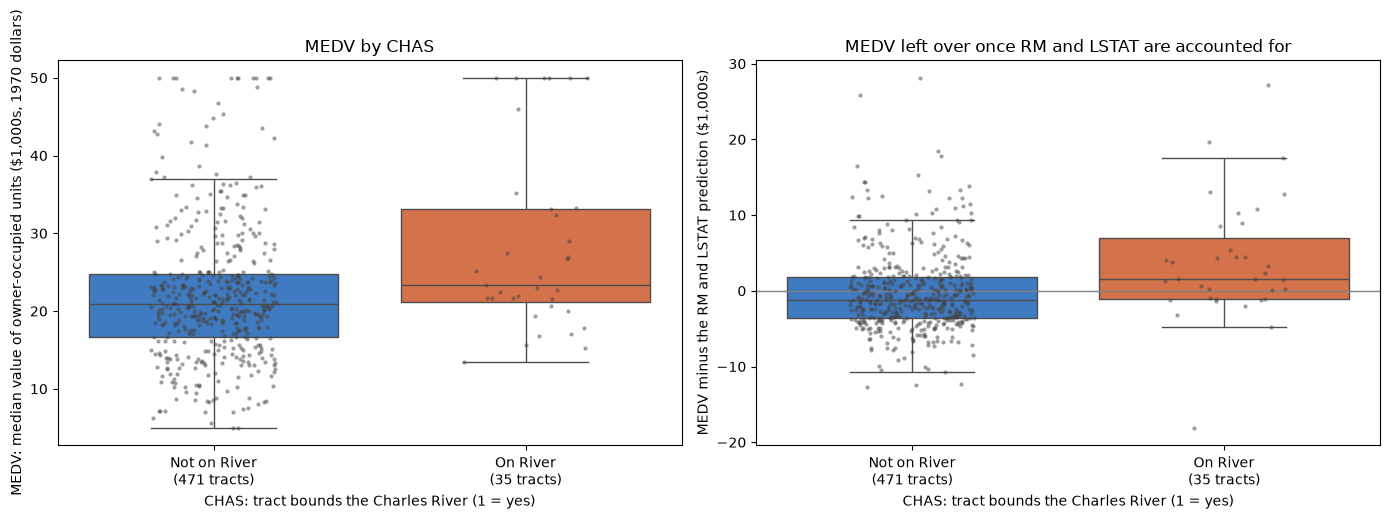

In [155]:
left = residuals(df["MEDV"], ["RM", "LSTAT"]).rename("MEDV")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
box_by_group(axes[0], df["OnRiver"], df["MEDV"], order=["Not on River", "On River"], colours=GROUP_COLOURS, points=True)
axes[0].set_title("MEDV by CHAS")
axes[0].set_xlabel(LABELS["CHAS"])
box_by_group(axes[1], df["OnRiver"], left, order=["Not on River", "On River"], colours=GROUP_COLOURS, points=True)
axes[1].axhline(0, color="grey", linewidth=1)
axes[1].set_title("MEDV left over once RM and LSTAT are accounted for")
axes[1].set_xlabel(LABELS["CHAS"])
axes[1].set_ylabel("MEDV minus the RM and LSTAT prediction ($1,000s)")
plt.tight_layout()
plt.show()

#### Observations from multivariate analysis of `CHAS`

- **River tracts differ on other features.** They are more industrial (`INDUS` 13.89 against 8.56, +0.78 standard deviations) and have older housing (`AGE` 88.5 against 76.5, +0.43). They also have smaller classes (`PTRATIO` 17.6 against 19.1, -0.69). They are similar on `RM` (+0.07) and `LSTAT` (-0.12).

- **The premium holds once `RM` and `LSTAT` are accounted for.** The median residual is +1.60 for river tracts against -1.18 for the others, a gap of +2.78 (Mann-Whitney p = 4.2e-05, against 1.6e-03 for raw `MEDV`). The partial r is 0.188, against a simple r of 0.175.

- **It holds without the capped tracts too.** The gap is +3.19 (p = 0.0020), where the raw comparison without them was not significant (p = 0.059). Accounting for `RM` and `LSTAT` removes much of the variation in `MEDV` that has nothing to do with the river, so the difference becomes visible.

- **But it is small.** Without the capped tracts, the partial r is only 0.094.

- **Implication:** `CHAS` carries a real but modest premium of about $2,800 to $3,200 in median terms, once housing size and status are allowed for.

### Multivariate - the capped tracts in context
A tract at `MEDV` = 50 is worth $50,000 or more. If its other features look like those of a high-value tract, the cap is plausible. This compares each capped tract with what `RM` and `LSTAT` predict, using a straight-line fit to the 490 uncapped tracts.

In [156]:
uncapped = df[~CAPPED]
cap_fit = sm.OLS(uncapped["MEDV"], sm.add_constant(uncapped[["RM", "LSTAT"]])).fit()
predicted = cap_fit.predict(sm.add_constant(df[["RM", "LSTAT"]]))

capped_view = df.loc[CAPPED, ["RM", "LSTAT", "CRIM", "DIS", "NOX"]].assign(
    predicted=predicted[CAPPED], in_132_tract_town=BIG_TOWN[CAPPED])
print(capped_view.sort_values("predicted").round(2).to_string())

# Actual minus predicted for the uncapped tracts, inside and outside the 132-tract town
gap = (df["MEDV"] - predicted)[~CAPPED]
print(f"\nUncapped tracts, actual minus predicted: median inside the town {gap[BIG_TOWN[~CAPPED]].median():+.2f}, "
      f"outside {gap[~BIG_TOWN[~CAPPED]].median():+.2f}; share below the prediction inside "
      f"{(gap[BIG_TOWN[~CAPPED]] < 0).mean():.0%}, outside {(gap[~BIG_TOWN[~CAPPED]] < 0).mean():.0%}")

# How uncapped tracts with similar predictions actually turned out
for lo, hi in [(22, 31), (33, 38)]:
    similar = uncapped[(predicted[~CAPPED] >= lo) & (predicted[~CAPPED] <= hi)]
    print(f"\nUncapped tracts predicted {lo} to {hi}: {len(similar)}; actual MEDV median {similar['MEDV'].median():.1f}, "
          f"above 40: {(similar['MEDV'] > 40).sum()}")
    print(f"  of which inside the 132-tract town: {BIG_TOWN[similar.index].sum()}, "
          f"actual MEDV max {similar.loc[BIG_TOWN[similar.index], 'MEDV'].max()}")

       RM  LSTAT  CRIM   DIS   NOX  predicted  in_132_tract_town
368  4.97   3.26  4.90  1.33  0.63      22.01               True
372  5.88   8.88  8.27  1.13  0.67      22.49               True
371  6.22   9.53  9.23  1.17  0.63      23.56               True
369  6.68   3.73  5.67  1.36  0.63      29.05               True
370  7.02   2.96  6.54  1.20  0.63      30.94               True
186  7.83   4.45  0.06  3.20  0.49      33.53              False
161  7.49   1.73  1.46  1.97  0.60      33.70              False
267  8.30   7.44  0.58  2.42  0.57      33.72              False
166  7.93   3.70  2.01  2.05  0.60      34.40              False
195  7.88   2.97  0.01  5.65  0.42      34.61              False
283  7.92   3.16  0.02  5.88  0.40      34.70              False
162  7.80   1.92  1.83  2.04  0.60      34.93              False
204  8.03   2.88  0.02  5.12  0.42      35.34              False
163  8.38   3.32  1.52  2.16  0.60      36.54              False
257  8.70   5.12  0.61  1

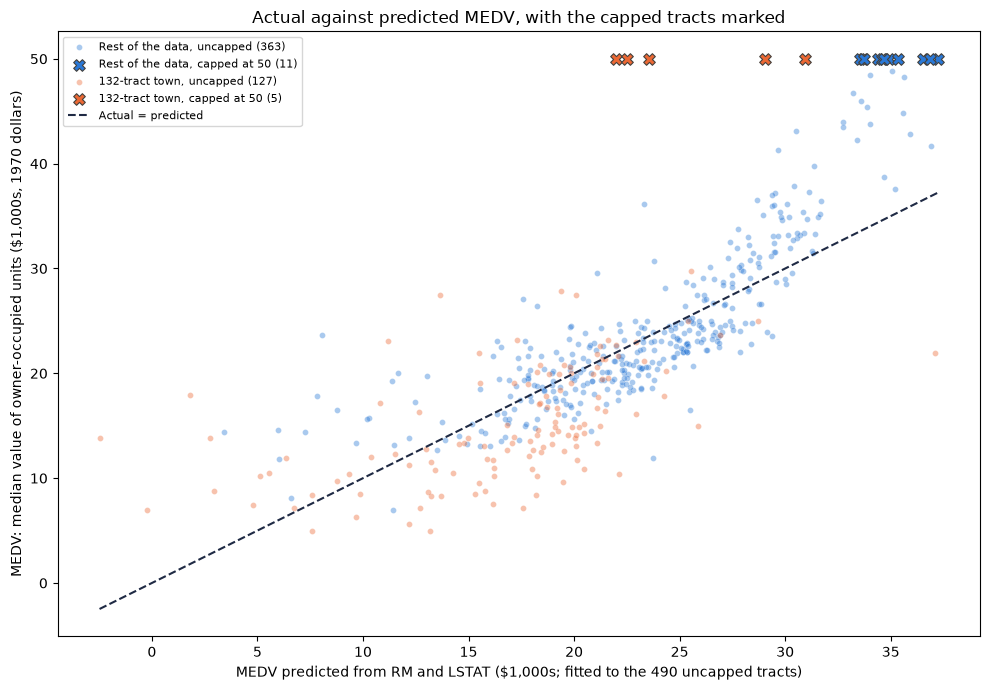

In [157]:
fig, ax = plt.subplots(figsize=(10, 7))
for name, colour in zip(town_groups.cat.categories, GROUP_COLOURS):
    part = (town_groups == name) & ~CAPPED
    ax.scatter(predicted[part], df.loc[part, "MEDV"], s=18, alpha=0.4, color=colour, edgecolor="white", linewidth=0.3,
               label=f"{name}, uncapped ({part.sum()})")
    part = (town_groups == name) & CAPPED
    ax.scatter(predicted[part], df.loc[part, "MEDV"], s=70, marker="X", color=colour, edgecolor=CAPPED_COLOUR, linewidth=0.8,
               label=f"{name}, capped at 50 ({part.sum()})")
line = np.array([predicted.min(), predicted.max()])
ax.plot(line, line, color=LOWESS_COLOUR, linestyle="--", linewidth=1.5, label="Actual = predicted")
ax.set_xlabel("MEDV predicted from RM and LSTAT ($1,000s; fitted to the 490 uncapped tracts)")
ax.set_ylabel(LABELS["MEDV"])
ax.set_title("Actual against predicted MEDV, with the capped tracts marked")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Observations from multivariate analysis of the capped tracts

- **Outside the 132-tract town, the cap is plausible.**
    - The 11 capped tracts there have 7.49 to 8.72 rooms and `LSTAT` between 1.73 and 7.44. `RM` and `LSTAT` predict 33.5 to 37.2 for them.
    - Uncapped tracts predicted 33 to 38 actually have a median of 44.3, and 11 of those 14 are above 40. The straight line under-predicts the top end, so true values of $50,000 or more fit these tracts.

- **Inside the town, it isn't.**
    - The 5 capped tracts (rows 368 to 372) are predicted only 22.0 to 30.9. The 12 uncapped town tracts with predictions in that range reach at most 29.8.
    - The town's uncapped tracts sit below their prediction in general: the median of actual minus predicted is -2.59 inside, against -0.27 outside, and 69% of them are below it, against 54%.
    - These 5 tracts also have `CRIM` between 4.90 and 9.23 and `DIS` between 1.13 and 1.36.

- **Implication:** the 5 capped tracts in the town don't fit the rest of the data. They are also 5 of the 13 far-from-line tracts in the `RM` analysis. They are the prime candidates for the miscoded `MEDV` values noted in the data overview (Gilley and Pace, 1996). Whether to keep, remove or check them is a preprocessing decision.

### Multivariate - outliers in combination
A tract can be ordinary on every feature taken alone but unusual in combination, for example a high `TAX` with a low `RAD`. The Mahalanobis distance measures how far a tract sits from the centre of all 12 features, allowing for their correlations. With 12 features, a squared distance above the 99.9th percentile of a chi-square distribution with 12 degrees of freedom is flagged.

In [158]:
def mahalanobis(data):
    """Squared Mahalanobis distance of each row from the column means."""
    centred = data - data.mean()
    return pd.Series(np.einsum("ij,jk,ik->i", centred.values, np.linalg.inv(np.cov(data.T)), centred.values), index=data.index)


mahal = mahalanobis(df[PREDICTORS])
cutoff = stats.chi2.ppf(0.999, len(PREDICTORS))
flagged = mahal[mahal > cutoff].sort_values(ascending=False)
print(f"Cut-off {cutoff:.1f}: {len(flagged)} tracts flagged")

# Univariate IQR outliers, by the rule used in the univariate analysis. ZN and CHAS are left out: most of their
# values sit at zero, so their fences flag ordinary values
uni_cols = [c for c in PREDICTORS if c not in ("ZN", "CHAS")]
q1, q3 = df[uni_cols].quantile(0.25), df[uni_cols].quantile(0.75)
uni_out = (df[uni_cols] < q1 - 1.5 * (q3 - q1)) | (df[uni_cols] > q3 + 1.5 * (q3 - q1))
z = (df[PREDICTORS] - df[PREDICTORS].mean()) / df[PREDICTORS].std()

outlier_table = pd.DataFrame({
    "distance": flagged.round(1),
    "largest z-scores": [", ".join(f"{c} {z.loc[i, c]:+.1f}" for c in z.loc[i].abs().nlargest(3).index) for i in flagged.index],
    "univariate outlier on": [", ".join(uni_out.columns[uni_out.loc[i]]) or "none" for i in flagged.index],
    "132-tract town": BIG_TOWN[flagged.index],
    "MEDV": df.loc[flagged.index, "MEDV"]})
print(f"Flagged tracts that are not a univariate outlier on any feature: {(outlier_table['univariate outlier on'] == 'none').sum()}")
print(f"Flagged tracts inside the 132-tract town: {outlier_table['132-tract town'].sum()}")
outlier_table

Cut-off 32.9: 18 tracts flagged
Flagged tracts that are not a univariate outlier on any feature: 10
Flagged tracts inside the 132-tract town: 7


,distance,largest z-scores,univariate outlier on,132-tract town,MEDV
380,145.1,"CRIM +9.9, RAD +1.7, TAX +1.5",CRIM,True,10.4
418,89.6,"CRIM +8.1, RAD +1.7, TAX +1.5",CRIM,True,8.8
405,72.7,"CRIM +7.5, RAD +1.7, TAX +1.5",CRIM,True,5.0
410,50.1,"CRIM +5.5, RAD +1.7, TAX +1.5",CRIM,True,15.0
365,48.7,"RM -3.9, RAD +1.7, TAX +1.5",RM,True,27.5
490,40.4,"INDUS +2.4, LSTAT +2.4, TAX +1.8",none,False,8.1
492,37.6,"INDUS +2.4, TAX +1.8, DIS -0.8",none,False,20.1
152,37.3,"CHAS +3.7, NOX +2.7, RM -1.8",none,False,15.3
364,37.3,"CHAS +3.7, RM +3.6, RAD +1.7",RM,True,21.9
491,37.3,"INDUS +2.4, TAX +1.8, AGE +1.1",none,False,13.6


     INDUS  RAD  TAX  PTRATIO    NOX  LSTAT  MEDV
488  27.74    4  711     20.1  0.609  18.06  15.2
489  27.74    4  711     20.1  0.609  23.97   7.0
490  27.74    4  711     20.1  0.609  29.68   8.1
491  27.74    4  711     20.1  0.609  18.07  13.6
492  27.74    4  711     20.1  0.609  13.35  20.1

With log(CRIM): 15 flagged; 13 also flagged before; no longer flagged: [380, 405, 410, 414, 418]


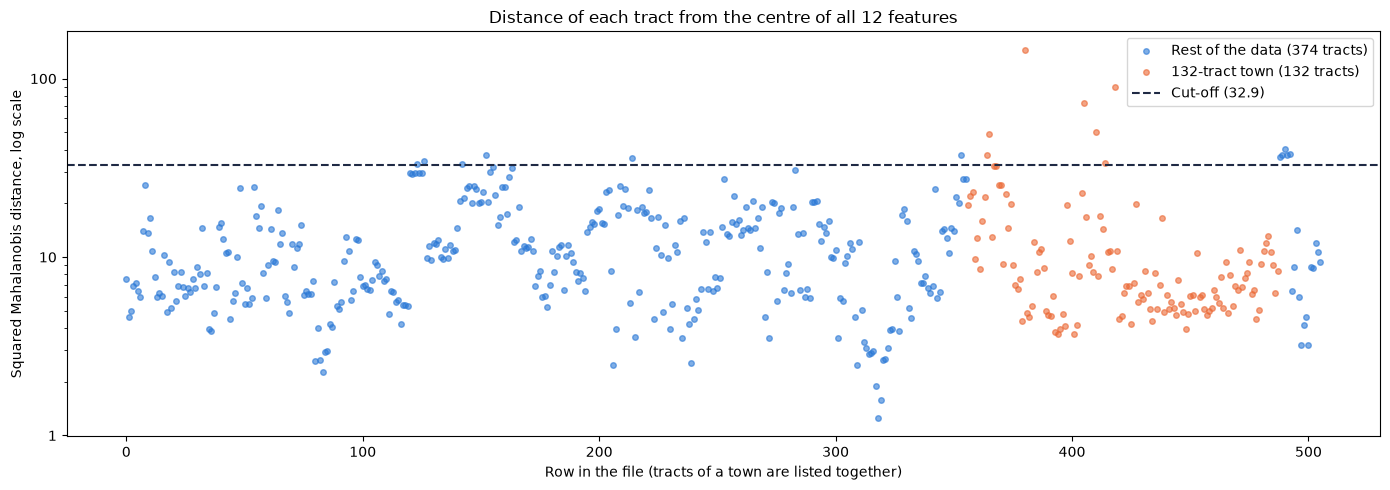

In [159]:
print(df.loc[488:492, ["INDUS", "RAD", "TAX", "PTRATIO", "NOX", "LSTAT", "MEDV"]].to_string())

# CRIM's extreme values dominate the distance, so the check is repeated with log(CRIM)
mahal_log = mahalanobis(df[PREDICTORS].assign(CRIM=np.log(df["CRIM"])))
flagged_log = mahal_log[mahal_log > cutoff]
print(f"\nWith log(CRIM): {len(flagged_log)} flagged; {len(flagged_log.index.intersection(flagged.index))} also flagged before; "
      f"no longer flagged: {sorted(set(flagged.index) - set(flagged_log.index))}")

fig, ax = plt.subplots(figsize=(14, 5))
for name, colour in zip(town_groups.cat.categories, GROUP_COLOURS):
    part = town_groups == name
    ax.scatter(df.index[part], mahal[part], s=16, alpha=0.6, color=colour, label=f"{name} ({part.sum()} tracts)")
ax.axhline(cutoff, color=LOWESS_COLOUR, linestyle="--", linewidth=1.5, label=f"Cut-off ({cutoff:.1f})")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Row in the file (tracts of a town are listed together)")
ax.set_ylabel("Squared Mahalanobis distance, log scale")
ax.set_title("Distance of each tract from the centre of all 12 features")
ax.legend()
plt.tight_layout()
plt.show()

#### Observations from multivariate analysis of outliers

- **18 tracts exceed the cut-off of 32.9,** and 10 of them are not a univariate outlier on any feature. Those 10 are only unusual in combination.

- **The `TAX` 711 town (rows 488 to 492):** all 5 of its tracts are flagged, and none is a univariate outlier. It has the highest `INDUS` (27.74) and the highest `TAX` (711), but `RAD` is only 4. It is the one town that breaks the `RAD`–`TAX` pattern, since every other tract with `TAX` above 500 has `RAD` 24. Its `MEDV` ranges from 7.0 to 20.1.

- **Other combinations:**
    - Rows 142 and 152 are river tracts at the highest `NOX` (0.871).
    - Rows 123 and 126 combine high `INDUS` and `LSTAT` with a low `TAX`.
    - Row 214 combines a high `LSTAT` with young housing (`AGE` z = -2.1), against the usual pattern.
    - Row 353 combines the largest `DIS` z-score (+4.0) with a high `ZN` (z = +3.4).

- **Inside the 132-tract town (7 tracts):**
    - 4 are flagged for extreme `CRIM` (rows 380, 405, 410 and 418, z = +5.5 to +9.9).
    - Rows 364 and 365 are the largest and smallest dwellings from the `RM` analysis.
    - Row 414 combines high `CRIM`, low `RM` and high `LSTAT`.
    - With log(`CRIM`), the four `CRIM` cases and row 414 drop out, so their distance came from `CRIM`'s skew. 15 tracts remain flagged, 13 of them flagged before.

- **Flagged tracts come in runs of neighbouring rows** (the plot), which are towns. Most multivariate outliers are whole towns with an unusual mix of values, not isolated data errors. Removing them would remove towns, so their influence is better checked on the fitted model (for example with Cook's distance).

### Summary of multivariate analysis

**Questions carried from the bivariate analysis**

| Question | Answer | Evidence |
|---|---|---|
| Does the 132-tract town explain the low `MEDV` at `PTRATIO` = 20.2? | Yes. 132 of the 140 tracts at 20.2 are the town; the other 8 have `MEDV` 18.5 to 22.2 | Membership table |
| How do `NOX`, `DIS`, `AGE` and `INDUS` behave as a group? | One block with `ZN` (average \|r\| 0.665), most of PC1 (49.2% of variance), VIFs 3.09 to 4.37. With the others held, `INDUS` and `AGE` fall to zero, `DIS` turns negative, and `NOX` keeps a smaller negative link | Clustering, PCA, VIF, partial correlations |
| How do `RM` and `LSTAT` overlap? | They share 0.389 of R². Their interaction adds 0.102. A room is worth 9.20 in the lowest `LSTAT` third and 1.43 in the highest | R² comparison, slopes by third |
| Do the 13 tracts far from the `RM` line share a town? | Yes. All 13 are in the 132-tract town | Membership check |

**Main findings**
- **Three blocks of related features:** the town markers (`CRIM`, `RAD`, `TAX`), the urban gradient (`ZN`, `INDUS`, `NOX`, `AGE`, `DIS`), and housing and status (`RM`, `LSTAT`, `MEDV`). The first two are tied to each other and to `LSTAT`.
- **Holding other features fixed changes the picture.** `LSTAT`, `RM` and `PTRATIO` remain the clearest predictors. `INDUS` and `AGE` add nothing, `DIS` reverses to negative, and `RAD`'s sign depends on whether `TAX` is held.
- **The 132-tract town behaves differently.** It is more urban on every measure. It is worth less than its `RM` and `LSTAT` predict (median gap -2.59), and `RM` hardly relates to `MEDV` inside it (r = 0.120, against 0.891 elsewhere). `RAD`'s correlation with `MEDV` exists only because the town is counted 132 times.
- **`RAD` and `TAX` are the worst multicollinearity** (VIF 9.00 and 7.45). Each falls to about 3 without the other.
- **The value of a room depends on `LSTAT`** (interaction +0.102 R²).
- **The river premium is real but small** once `RM` and `LSTAT` are allowed for (about +2.8 to +3.2 in median residual).
- **5 capped tracts in the town (rows 368 to 372) don't fit**, while the other 11 capped tracts look like genuine high-value tracts.
- **Multivariate outliers are mostly whole towns** with unusual combinations, such as the `TAX` 711 town with `RAD` 4.

**To carry into data preprocessing and model building**
- **Collinear and redundant features:** keep one of `RAD` and `TAX`, or represent the 132-tract town with a single indicator. `INDUS` and `AGE` are candidates to drop if the model confirms they add nothing.
- **The big town:** consider an indicator for it, because `RM` behaves differently there and its `MEDV` sits below what `RM` and `LSTAT` predict.
- **Terms to test:** an `RM` × `LSTAT` interaction, together with the bivariate transformations (log `LSTAT`, log `CRIM`, log `DIS`, possibly log `MEDV`, a squared `RM`).
- **Data decisions:** decide how to treat the 5 capped tracts in the town (rows 368 to 372). Keep the multivariate outliers, but check their influence on the fitted model.
- **Expected signs:** expect a negative coefficient on `DIS` despite its positive simple correlation, and don't interpret the sign of `RAD` or `TAX` while both are in the model.

**Questions:**

1. What does the distribution of 'MEDV' look like?
2. What can we infer form the correlation heatmap? Is there correlation between the dependent and independent variables?
3. What are all the inferences that can be found by doing univariate analysis for different variables?
4. Do bivariate analysis to visualize the relationship between the features having significant correlations (>= 0.7 or <= -0.7)

## Data Preprocessing

- Missing value treatment
- Log transformation of dependent variable if skewed
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

## Model Building - Linear Regression

## Model Performance Check

1. How does the model is performing? Check using Rsquared, RSME, MAE, MAPE
2. Is there multicollinearity? Check using VIF
3. How does the model is performing after cross validation?

## Checking Linear Regression Assumptions

- In order to make statistical inferences from a linear regression model, it is important to ensure that the assumptions of linear regression are satisfied.

## Final Model

## Actionable Insights and Recommendations 

- 


___

## Assumptions

- I interperet the instruction to "predict the housing prices of a town or a suburb" to mean, "predict the median price of an owner-occupied housing unit to the nearest $1,000"